In [528]:
import numpy as np
import pandas as pd
import itertools
import matplotlib.pyplot as plt
from matplotlib import cm
from datetime import date
import re
from tqdm import tqdm
import time
# from pybedtools import BedTool
import random
import math
import pickle
import seaborn as sns
from scipy.stats import percentileofscore, pearsonr, rankdata, fisher_exact, describe, hypergeom, ttest_1samp, sem
import scipy.stats as stats
from scipy.spatial.distance import jaccard, euclidean, cosine, pdist, squareform
import functools
import operator
import gzip
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from scipy.cluster import hierarchy
import sys
import os
from functools import partial
from contextlib import closing
from multiprocessing import Pool
import re
import h5py
from collections import Counter
from region_comparison_combine_scores_CT20220810 import combine_scores
from operator import is_not
import upsetplot
import matplotlib.colorbar as colorbar


today = date.today()

**Gene Set Info**

In [441]:
#all gene set
pickle_in = open('/home/ctrader/region_similarity/data/gene2allgeneset_dict_CT20220719.pickle', 'rb')
gene2allgeneset = pickle.load(pickle_in)
pickle_in.close()
total_genes = np.array(list(gene2allgeneset.keys()))
del gene2allgeneset

#c1 gene set 
pickle_in = open('/home/ctrader/region_similarity/data/gene2c1geneset_dict_CT20220725.pickle', 'rb')
gene2c1geneset = pickle.load(pickle_in)
pickle_in.close()

#c2 gene set 
pickle_in = open('/home/ctrader/region_similarity/data/gene2c2geneset_dict_CT20220725.pickle', 'rb')
gene2c2geneset = pickle.load(pickle_in)
pickle_in.close()

#hallmark gene set
pickle_in = open('/home/ctrader/region_similarity/data/gene2hallmarkgeneset_dict_CT20220718.pickle', 'rb')
gene2hallmarkgeneset = pickle.load(pickle_in)
pickle_in.close()

In [442]:
#reversing dictionaries
hallmarkgeneset2gene = {}
for gene in gene2hallmarkgeneset.keys():
    gene_sets = gene2hallmarkgeneset[gene]
    for gene_set in gene_sets:
        if gene_set not in hallmarkgeneset2gene:
            hallmarkgeneset2gene[gene_set] = np.array([gene])
        else:
            hallmarkgeneset2gene[gene_set] = np.append(hallmarkgeneset2gene[gene_set], np.array([gene]))
            
c1geneset2gene = {}
for gene in gene2c1geneset.keys():
    gene_sets = gene2c1geneset[gene]
    for gene_set in gene_sets:
        if gene_set not in c1geneset2gene:
            c1geneset2gene[gene_set] = np.array([gene])
        else:
            c1geneset2gene[gene_set] = np.append(c1geneset2gene[gene_set], np.array([gene]))
            
c2geneset2gene = {}
for gene in gene2c2geneset.keys():
    gene_sets = gene2c2geneset[gene]
    for gene_set in gene_sets:
        if gene_set not in c2geneset2gene:
            c2geneset2gene[gene_set] = np.array([gene])
        else:
            c2geneset2gene[gene_set] = np.append(c2geneset2gene[gene_set], np.array([gene]))

In [443]:
c1c2hallmarkgeneset2gene = hallmarkgeneset2gene
c1c2hallmarkgeneset2gene.update(c1geneset2gene)
c1c2hallmarkgeneset2gene.update(c2geneset2gene)

In [4]:
hallmark_gene_sets = list(hallmarkgeneset2gene.keys())
c1_gene_sets = list(c1geneset2gene.keys())
c2_gene_sets = list(c2geneset2gene.keys())

all_gene_sets = np.unique(np.append(np.append(hallmark_gene_sets, c1_gene_sets), c2_gene_sets))

In [5]:
#proteinID to gene name
pickle_in = open('/home/ctrader/region_similarity/data/gencode.v41.proteinID2genename_dict_CT20221007.pickle', 'rb')
id2gene_exact = pickle.load(pickle_in)
pickle_in.close()

id2gene = {}
for old_key in id2gene_exact.keys():
    new_key = old_key.split('.')[0]
    if new_key not in id2gene:
        id2gene[new_key] = id2gene_exact[old_key]
    else:
        print(new_key, old_key)

#finding gene to protein ind
# gene2id = {}
# for key, val in zip(id2gene.keys(), id2gene.values()):
#     if val not in gene2id:
#         gene2id[val] = np.array([key])
#     else:
#         gene2id[val] = np.append(gene2id[val], np.array([key]))
pickle_in = open('/home/ctrader/region_similarity/data/gencode.v41.genename2proteinID_dict_CT20221007.pickle', 'rb')
gene2id = pickle.load(pickle_in)
pickle_in.close()

**Gene2region dictionary**

In [6]:
pickle_in = open('/home/ctrader/region_similarity/data/gencode.v41.gene2regionwithpromoterbp_25kb_dict_CT20221007.pickle', 'rb')
gene2promoterregion = pickle.load(pickle_in)
pickle_in.close()

**OOE files**

In [7]:
# DHS_ooe_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220816.DHSpromoteronlyoee.hdf5'
# TF_ooe_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220816.TFpromoteronlyoee.hdf5'
TF_ooe_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20221007.TFpromoteronlyoee.gencode.v41.geneonly.hdf5'
# epilogos_ooe_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220816.epilogospromoteronlyoee.hdf5'

In [8]:
#loading order of each component
f = open('/home/ctrader/region_similarity/data/regions_25kb_CT20220815.TFmapped.bed', 'r')
TF_component_order = np.array(f.readline().strip().split('\t'))[3:]
f.close()

# f = open('/home/ctrader/region_similarity/data/regions_25kb_CT20220815.DHSmapped.bed', 'r')
# DHS_component_order = np.array(f.readline().strip().split('\t'))[3:]
# f.close()

# f = open('/home/ctrader/region_similarity/data/regions_25kb_CT20220815.epilogosmapped.bed', 'r')
# epilogos_component_order = np.array(f.readline().strip().split('\t'))[3:]
# f.close()

**DHS enrichment for genes**

In [9]:
gene_dhs_df = pd.read_csv('/home/ctrader/region_similarity/data/gene_ooe_all_WM20181115.txt', delimiter='\t')

In [10]:
DHS_comps_paper = np.array(['Placental / trophoblast', 'Lymphoid', 'Myeloid / erythroid', 'Cardiac', 
                            'Musculoskeletal', 'Vascular / endothelial', 'Primitive / embryonic', 
                            'Neural', 'Digestive', 'Stromal A', 'Stromal B', 'Renal / cancer', 
                            'Cancer / epithelial', 'Pulmonary devel.', 'Organ devel. / renal', 
                            'Tissue invariant'])
# DHS_comps_alpha = np.array(['Cancer / epithelial', 'Cardiac', 'Digestive', 'Lymphoid', 'Musculoskeletal', 
#                             'Myeloid / erythroid', 'Neural', 'Organ devel. / renal', 'Placental / trophoblast', 
#                             'Primitive / embryonic', 'Pulmonary devel.', 'Renal / cancer', 'Stromal A', 'Stromal B', 
#                             'Tissue invariant', 'Vascular / endothelial'])
DHS_comps_nmf = np.array(['Tissue invariant', 'Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 
                          'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 
                          'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 
                          'Myeloid / erythroid', 'Cancer / epithelial'])
# alpha2paper_order = np.array([8, 3, 5, 1, 4, 15, 9, 6, 2, 12, 13, 11, 0, 10, 7, 14])
nmf2paper_order = np.array([6, 4, 14, 8, 11, 13, 2, 7, 12, 1, 3, 5, 15, 10, 9, 0])
DHS_color = np.array(['#FFE500', '#FE8102', '#FF0000', '#07AF00', '#4C7D14', '#414613', '#05C1D9', '#0467FD', 
                      '#009588', '#BB2DD4', '#7A00FF', '#4A6876', '#08245B', '#B9461D', '#692108', '#C3C3C3'])

**All STRING associations**

In [11]:
#all associations
all_df = pd.read_csv('/home/ctrader/region_similarity/data/9606.protein.links.full.v11.5.txt', sep=' ')

# id1 = all_df['protein1'].str.split('.', expand=True)[1]
# id2 = all_df['protein2'].str.split('.', expand=True)[1]
# all_df['protein1'] = id1
# all_df['protein2'] = id2

all_protein_combos = all_df[['protein1', 'protein2']].to_numpy()
all_protein_combos_sorted = np.sort(all_protein_combos, axis=1)

#dropping repeated inds
all_used_associations = set()
inds_to_drop = []
for row_ind in range(len(all_protein_combos_sorted)):
    row = all_protein_combos_sorted[row_ind]
    tup = (row[0], row[1])
    if tup in all_used_associations:
        inds_to_drop.append(row_ind)
    else:
        all_used_associations.add(tup)
inds_to_drop = np.array(inds_to_drop)
all_df = all_df.drop(inds_to_drop)


all_df.loc[:, all_df.columns[2:]] = all_df[all_df.columns[2:]].astype(int)
all_df['neighborhood'] = all_df[['neighborhood_transferred', 'neighborhood']].max(axis=1).astype(int)
all_df['coexpression'] = all_df[['coexpression_transferred', 'coexpression']].max(axis=1).astype(int)
all_df['experiments'] = all_df[['experiments_transferred', 'experiments']].max(axis=1).astype(int)
all_df['database'] = all_df[['database_transferred', 'database']].max(axis=1).astype(int)
all_df['textmining'] = all_df[['textmining_transferred', 'textmining']].max(axis=1).astype(int)
all_df = all_df[['protein1', 'protein2', 'neighborhood', 'fusion', 'cooccurence', 'homology', 'coexpression', 
                 'experiments', 'database', 'textmining', 'combined_score']]


all_df_arr = all_df.iloc[:, 2:].to_numpy()
all_df_mean = np.mean(all_df_arr, axis=0)

In [330]:
#getting all associations
string_scores_arr = []
filename = '/home/ctrader/region_similarity/data/9606.protein.links.full.v11.5.txt'
f = open(filename, 'r')
for line in f.readlines()[1:]:
    line = line.strip().split(' ')
    line[0] = line[0].split('.')[1]
    line[1] = line[1].split('.')[1]
    string_scores_arr.append(line)
f.close()
string_scores_arr = np.array(string_scores_arr)

In [12]:
string_label_dict = {
    'coexpression' : 'Co-expressed',
    'cooccurence' : 'Co-evolved',
    'database' : 'Co-annotated',
    'experiments' : 'Interacts in vitro',
    'fusion' : 'Fused in Other Species',
    'homology' : 'Has Common Ancestory',
    'neighborhood' : 'is Nearby',
    'textmining' : 'Co-occurs in Literature'
}

**Gene set order for spectrum plots**

In [13]:
infile = '/home/ctrader/region_similarity/data/regions_25kb_CT20220926.genesethallmarkc1c2order.significancedependent.gsregionbon.cosine.average.npz'
gene_set_order = np.load(infile)['gene_set_order']
inds_clustered = np.load(infile)['inds_clustered']

hdf5_file_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220926.genesethallmarkc1c2freqooe.hdf5'
hdf5_file = h5py.File(hdf5_file_path, 'r')
spectrum_gene_sets = np.char.decode(hdf5_file['gene_sets'][:], 'utf-8')
hdf5_file.close()

#clustered order - alphabetical order, then cluster order
spectrum_gene_sets = spectrum_gene_sets[inds_clustered][gene_set_order]

**Functions**

In [236]:
def make_upset(data_for_upset, labels_for_upset, title, upset_dir, no_save=False):
    bool_for_upset = np.where(data_for_upset>0, True, False)
    indicators_for_upset = {}
    for i, l in zip(range(len(labels_for_upset)), labels_for_upset):
        indicators_for_upset[l] = bool_for_upset[:, i]

    upset_data = upsetplot.from_indicators(indicators_for_upset)
    upset_data = upset_data.groupby(list(upset_data.index.names)).count()

    #sorting upset categories
    upset_factors = np.array(upset_data.index.names)
    upset_factor_counts = np.array([])
    for i in range(len(upset_factors)):
        upset_factor_counts = np.append(upset_factor_counts, np.sum(upset_data.unstack(level=i)[True]))
    upset_factors_sorted = upset_factors[np.argsort(upset_factor_counts)]
    sorted_upset_data = upset_data.reorder_levels(upset_factors_sorted)

    fig = plt.figure(figsize=(10,10))

    upsetplot.plot(sorted_upset_data, sort_categories_by=None, min_subset_size=1, show_counts=True, sort_by='cardinality')
#     plt.yscale('log')

    plt.ylabel('Number of Regions')
    plt.title(title)
    if not no_save:
        plt.savefig(upset_dir + title + '_upset_CT' + today.strftime("%Y%m%d") + '.pdf', 
                    bbox_inches='tight', 
                    dpi=400, 
                    facecolor="#FFFFFF", 
                    edgecolor="#FFFFFF", 
                    transparent=False)
    plt.show()

In [54]:
def analyze_regions(region_inds_TF, all_string_mean, set_string_mean, genes_to_test_DHS, title, enrichments_dir):
    
#     genes[np.isin(genes, np.array(gene_dhs_df.index))]
    print('DHS shape', gene_dhs_df.loc[genes_to_test_DHS].shape)
    
    gene_DHS_ooe_mean = np.array(gene_dhs_df.loc[genes_to_test_DHS].mean())
    gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)
    
    TF_ooe_hdf5 = h5py.File(TF_ooe_hdf5_path, 'r')
    TF_ooe = TF_ooe_hdf5['ooe_arr'][:][region_inds_TF]
    TF_ooe_hdf5.close()
    
    print('TF shape', TF_ooe.shape)

    TF_ooe_mean = np.mean(TF_ooe, axis=0)
    TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
    
    if set_string_mean.isnull().sum() != len(set_string_mean): #all null values
        string_ooe_mean = np.array(set_string_mean) / all_string_mean
        string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score
    else:
        string_ooe_mean_log2 = np.array([np.nan]*len(set_string_mean))

    #only positively enriched and 3 maximum
    DHS_inds = np.argsort(-gene_DHS_ooe_mean_log2)[:3]
    DHS_inds = DHS_inds[gene_DHS_ooe_mean_log2[DHS_inds] > 0]
    #get colors for DHS plot
    colors_for_DHS = np.array([])
    for ind in DHS_inds:
        colors_for_DHS = np.append(colors_for_DHS, DHS_color[np.where(nmf2paper_order==ind)[0]])

    TF_inds = np.argsort(-TF_ooe_mean_log2)[:3]
    TF_inds = TF_inds[TF_ooe_mean_log2[TF_inds] > 0]

    string_inds = np.argsort(-string_ooe_mean_log2)[:3]
    string_inds = string_inds[string_ooe_mean_log2[string_inds] > 0]

    string_labels = np.array([])
    for label in np.array(set_string_mean.index)[:-1][string_inds]:
        string_labels = np.append(string_labels, string_label_dict[label])

    max_val_DHS = 0
    if len(DHS_inds) > 0:
        max_val_DHS = np.max(gene_DHS_ooe_mean_log2[DHS_inds])

    max_val_TF = 0
    if len(TF_inds) > 0:
        max_val_TF = np.max(TF_ooe_mean_log2[TF_inds])

    max_val_str = 0
    if len(string_inds) > 0:
        max_val_str = np.max(string_ooe_mean_log2[string_inds])


    #plotting
    fig, axes = plt.subplots(ncols=3, figsize=(10,5))
    fig.patch.set_facecolor('white')
    plt.subplots_adjust(wspace=0.2)

    axes = axes.ravel()

    axes[0].bar(np.arange(len(string_ooe_mean_log2[string_inds])), string_ooe_mean_log2[string_inds])
    axes[1].bar(np.arange(len(gene_DHS_ooe_mean_log2[DHS_inds])), gene_DHS_ooe_mean_log2[DHS_inds], 
                color=colors_for_DHS)
    axes[2].bar(np.arange(len(TF_ooe_mean_log2[TF_inds])), TF_ooe_mean_log2[TF_inds])

    axes[0].set_xticks(np.arange(len(string_ooe_mean_log2[string_inds])))
    axes[0].set_xticklabels(string_labels, rotation=45, ha='right')
    axes[0].set_xlim([-1, len(string_ooe_mean_log2[string_inds])])
    axes[0].set_ylim([0, max_val_str*1.1])
    if len(string_inds)==0:
        axes[0].set_yticks([])
    axes[0].set_ylabel('Enrichment')
    axes[0].set_title('Gene Relations')

    axes[1].set_xticks(np.arange(len(gene_DHS_ooe_mean_log2[DHS_inds])))
    axes[1].set_xticklabels(DHS_comps_nmf[DHS_inds], rotation=45, ha='right')
    axes[1].set_xlim([-1, len(gene_DHS_ooe_mean_log2[DHS_inds])])
    axes[1].set_ylim([0, max_val_DHS*1.1])
    axes[1].set_title('DHS Components')

    axes[2].set_xticks(np.arange(len(TF_ooe_mean_log2[TF_inds])))
    axes[2].set_xticklabels(TF_component_order[TF_inds], rotation=45, ha='right')
    axes[2].set_xlim([-1, len(TF_ooe_mean_log2[TF_inds])])
    axes[2].set_ylim([0, max_val_TF*1.1])
    axes[2].set_title('TF Motifs')

    fig.suptitle(title)
    
    fig.savefig(enrichments_dir + title + '_gene_factor_enrichments_CT' + today.strftime("%Y%m%d") + '.png')
    plt.savefig(enrichments_dir + title + '_gene_factor_enrichments_CT' + today.strftime("%Y%m%d") + '.pdf', 
                bbox_inches='tight', 
                dpi=400, 
                facecolor="#FFFFFF", 
                edgecolor="#FFFFFF", 
                transparent=False)
    plt.pause(0.01)
    return set_string_mean

In [275]:
def set_of_genes_analysis(gene_list, title, enrichments_dir, upset_dir, spectrum_dir, no_sig_gs=False):
    print('original number of genes', len(gene_list))
    #filter oout genes that don't have gene ids 
    
    
    gene_list_filtered_STRING = gene_list[np.isin(gene_list, np.array(list(gene2id.keys())))]
#     #filter out genes without a region
#     gene_list_filtered = gene_list_filtered[np.isin(gene_list_filtered, 
#                                                     np.array(list(gene2promoterregion.keys())))]
#     #filter out genes not in gene dhs df
#     gene_list_filtered = gene_list_filtered[np.isin(gene_list_filtered, np.array(gene_dhs_df.index))]
    
    ids_to_test = np.array([])
    for gene in gene_list_filtered_STRING:
        ids_to_test = np.append(ids_to_test, gene2id[gene])
        
        
    for i in range(len(ids_to_test)):
        ids_to_test[i] = ids_to_test[i].split('.')[0]
        

    ids_to_test_set = set(ids_to_test)
    
    #collecting all associations from genes of interest
    string_scores_for_ids = []
    filename = '/home/ctrader/region_similarity/data/9606.protein.links.full.v11.5.txt'
    f = open(filename, 'r')
    for line in f.readlines()[1:]:
        line = line.strip().split(' ')
        if line[0].split('.')[1] in ids_to_test_set:
            line[0] = line[0].split('.')[1]
            line[1] = line[1].split('.')[1]
            string_scores_for_ids.append(line)
    string_scores_for_ids = np.array(string_scores_for_ids)
    f.close()
    
    
    #if ids have gene associations
    scores_g = []
    for row in string_scores_for_ids:
        new_row = []
        if row[0] in id2gene:
            new_row.append(id2gene[row[0]])
        else:
            new_row.append(row[0])

        if row[1] in id2gene:
            new_row.append(id2gene[row[1]])
        else:
            new_row.append(row[1])

        for i in range(2, len(row)):
            new_row.append(row[i])
        scores_g.append(new_row)
    scores_g = np.array(scores_g)
    
    
    if len(scores_g) > 0:
        #Dataframe
        set_df = pd.DataFrame(scores_g, columns = ['Gene1', 'Gene2', 'neighborhood', 'neighborhood_transferred',
                                                   'fusion', 'cooccurence', 'homology', 'coexpression',
                                                   'coexpression_transferred', 'experiments', 'experiments_transferred',
                                                   'database', 'database_transferred', 'textmining', 'textmining_transferred',
                                                   'combined_score'])

        set_df.loc[:, set_df.columns[2:]] = set_df[set_df.columns[2:]].astype(int)

        #combine human and transferred scores
        set_df['neighborhood'] = set_df[['neighborhood_transferred', 'neighborhood']].max(axis=1).astype(int)
        set_df['coexpression'] = set_df[['coexpression_transferred', 'coexpression']].max(axis=1).astype(int)
        set_df['experiments'] = set_df[['experiments_transferred', 'experiments']].max(axis=1).astype(int)
        set_df['database'] = set_df[['database_transferred', 'database']].max(axis=1).astype(int)
        set_df['textmining'] = set_df[['textmining_transferred', 'textmining']].max(axis=1).astype(int)
        set_df = set_df[['Gene1', 'Gene2', 'neighborhood', 'fusion', 'cooccurence', 'homology', 'coexpression', 
                         'experiments', 'database', 'textmining', 'combined_score']]

        
#         set_used_associations = set()
#         for index in np.array(set_df.index):
#             tup = (set_df.loc[index]['Gene1'], set_df.loc[index]['Gene2'])
#             tup = tuple(np.sort(tup))
#             if tup in set_used_associations:
#                 set_df = set_df.drop(index)
#             else:
#                 set_used_associations.add(tup)
                
        genes12 = np.hstack((np.array(set_df['Gene1']).reshape(-1, 1), np.array(set_df['Gene2']).reshape(-1, 1)))
        genes12_sorted = np.sort(genes12, axis=1)
        genes12_sorted_joined = genes12_sorted[:, 0] + np.array(['_']*len(genes12_sorted)) + genes12_sorted[:, 1]
        genes12_unique, genes12_unique_inds = np.unique(genes12_sorted_joined, return_index=True)
        set_df = set_df.iloc[genes12_unique_inds]
                

        set_df_inter = set_df[set_df['Gene2'].isin(gene_list_filtered_STRING)]
        
        
        if len(set_df_inter) > 0:
            data_for_upset = set_df_inter.iloc[:, 2:-1].to_numpy()
            
            labels_for_upset = ['is Nearby', 'Fused in Other Species', 'Co-evolved', 'Has Common Ancestory', 
                                'Co-expressed', 'Interacts in vitro', 'Co-annotated', 'Co-occurs in Literature']
            if np.count_nonzero(np.sum(data_for_upset, axis=0)) > 1:
                make_upset(data_for_upset, labels_for_upset, title, upset_dir)

        set_df_inter_mean = set_df_inter.mean(axis=0)
        
        print('inter-string shape', set_df_inter.shape)
    else:
        set_df_inter_mean = pd.Series(np.array([np.nan]*11))
    
    
    regions_set_TF = np.array([], dtype=int)
    for gene in gene_list:
        if gene in gene2promoterregion:
            regions_set_TF = np.append(regions_set_TF, gene2promoterregion[gene])
            
    #filter out genes not in gene dhs df
    genes_to_test_DHS = gene_list[np.isin(gene_list, np.array(gene_dhs_df.index))]
            
    #plotting - new format
    set_string_mean = analyze_regions(regions_set_TF, all_df_mean, set_df_inter_mean, genes_to_test_DHS, title, enrichments_dir)
    
    if not no_sig_gs:
        #gene set analysis
        gene_sets_of_interest = np.array([])
        for gene in gene_list: #not using filtered
            #finding the gene sets for each gene
            if gene in gene2hallmarkgeneset:
                gene_sets_of_interest = np.append(gene_sets_of_interest, gene2hallmarkgeneset[gene])
            if gene in gene2c1geneset:
                gene_sets_of_interest = np.append(gene_sets_of_interest, gene2c1geneset[gene])
            if gene in gene2c2geneset:
                gene_sets_of_interest = np.append(gene_sets_of_interest, gene2c2geneset[gene])
        gene_sets_of_interest = np.unique(gene_sets_of_interest)

        significant_gene_sets = []
        pvals = []
        for gene_set in gene_sets_of_interest:
            #finding genes for each gene set
            if gene_set in hallmarkgeneset2gene:
                genes_in_gene_set_of_interest = hallmarkgeneset2gene[gene_set] 
            elif gene_set in c1geneset2gene:
                genes_in_gene_set_of_interest = c1geneset2gene[gene_set] 
            else:
                genes_in_gene_set_of_interest = c2geneset2gene[gene_set]
            #fisher's exact test
            a = len(total_genes[(np.isin(total_genes, gene_list)) & 
                                (np.isin(total_genes, genes_in_gene_set_of_interest))])
            b = len(total_genes[(~np.isin(total_genes, gene_list)) & 
                                (np.isin(total_genes, genes_in_gene_set_of_interest))])
            c = len(total_genes[(np.isin(total_genes, gene_list)) & 
                                (~np.isin(total_genes, genes_in_gene_set_of_interest))])
            d = len(total_genes[(~np.isin(total_genes, gene_list)) & 
                                (~np.isin(total_genes, genes_in_gene_set_of_interest))])
            conting = np.array([[a, b], [c, d]])
            odds, pval = fisher_exact(conting, alternative='greater')
            if pval < 0.05 / len(all_gene_sets): #bonferroni correction
                significant_gene_sets.append(gene_set)
                pvals.append(pval)
        significant_gene_sets = np.array(significant_gene_sets)
        pvals = np.array(pvals)

        significant_gene_sets_ordered = significant_gene_sets[np.argsort(pvals)]
        pval_ordered = pvals[np.argsort(pvals)]

        #spectrum plots
        if len(significant_gene_sets_ordered) > 0:
            spectrum_plots(spectrum_gene_sets, significant_gene_sets_ordered, pval_ordered, title, spectrum_dir)
    
        return significant_gene_sets_ordered, pval_ordered, set_string_mean
    
    else:
        return set_string_mean

In [56]:
def spectrum_plots(spectrum_gs, megamap_gs, megamap_p, title, spectrum_dir):
    #spectrum plot
    
    #create spectrum
    colors = cm.get_cmap('nipy_spectral', len(spectrum_gs))

    #find overlap between megamap and spectrum gene sets
    megamap_spectrum_gs = megamap_gs[np.isin(megamap_gs, spectrum_gs)]
    megamap_spectrum_p = -np.log10(megamap_p[np.isin(megamap_gs, spectrum_gs)])
    megamap_spectrum_inds = np.array([], dtype=int)
    for gs in megamap_spectrum_gs:
        megamap_spectrum_inds = np.append(megamap_spectrum_inds, np.where(spectrum_gs==gs)[0])

    #sorting
    sort_order = np.argsort(megamap_spectrum_inds)
    megamap_spectrum_gs_sorted = megamap_spectrum_gs[sort_order]
    megamap_spectrum_p_sorted = megamap_spectrum_p[sort_order]
    megamap_spectrum_inds_sorted = megamap_spectrum_inds[sort_order]

    #setting pvalue array
    spectrum_pvals = np.zeros(len(spectrum_gs))
    spectrum_pvals[megamap_spectrum_inds_sorted] = megamap_spectrum_p_sorted

    #limiting labels 
    min_dist = 40
    to_label_inds = np.array([], dtype=int)
    to_label_labels = np.array([])
    to_label_vals = np.array([])
    for ind, label, val in zip(megamap_spectrum_inds_sorted, megamap_spectrum_gs_sorted, megamap_spectrum_p_sorted):
        if len(to_label_inds) == 0:
            to_label_inds = np.append(to_label_inds, ind)
            to_label_labels = np.append(to_label_labels, label)
            to_label_vals = np.append(to_label_vals, val)
        elif ind - to_label_inds[-1] > min_dist:
            to_label_inds = np.append(to_label_inds, ind)
            to_label_labels = np.append(to_label_labels, label)
            to_label_vals = np.append(to_label_vals, val)
        elif to_label_vals[-1] < val:
            to_label_inds[-1] = ind
            to_label_labels[-1] = label
            to_label_vals[-1] = val

    #trimming terms
    for i in range(len(to_label_labels)):
        to_label_labels[i] = to_label_labels[i].replace('_', ' ').replace('WP ', '').replace('HALLMARK ', '').replace('KEGG ', '').replace('REACTOME ', '').replace('BIOCARTA ', '')

    #plot
    fig, axes = plt.subplots(nrows=2, gridspec_kw={'height_ratios': [4, 1]}, figsize=(12, 2))
    fig.patch.set_facecolor('white')
    axes = axes.ravel()
    plt.subplots_adjust(hspace=0)

    axes[0].fill_between(range(len(spectrum_pvals)), spectrum_pvals, color='k')

    colorbar.ColorbarBase(axes[1], cmap=colors, orientation='horizontal').set_ticks(to_label_inds/len(spectrum_pvals))
    axes[1].set_xticklabels(to_label_labels, rotation=45, ha='right')
    axes[0].set_xlim([0, len(spectrum_pvals)])
    axes[0].set_xticks([])
    axes[0].set_ylabel('-log10(p value)')
    axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


    title = 'Significant Gene Sets for %s' %(title)
    fig.suptitle(title, y=1.08)
    title = title.replace(' ', '_')
    print(title)
    plt.savefig(spectrum_dir + title + '_spectrum_CT' + today.strftime("%Y%m%d") + '.png')
    plt.savefig(spectrum_dir + title + '_spectrum_CT' + today.strftime("%Y%m%d") + '.pdf', 
                bbox_inches='tight', 
                dpi=400, 
                facecolor="#FFFFFF", 
                edgecolor="#FFFFFF", 
                transparent=False)
    plt.pause(0.01)
    return
# spectrum_plots(spectrum_gene_sets, significant_gene_sets, pvals, experiment)

**Results**

In [18]:
f = open('/home/meuleman/projects/MegaMap/WM20220727_extract_MegaMap_target_genes_for_Cameron/table_targets_forCameron_WM20220727.txt', 'r')
exper_plus_genes = []
exper_only = np.array([])
for line in f.readlines():
    line = re.split(',|\t', line.strip())
    exper_plus_genes.append(line)
    exper_only = np.append(exper_only, line[0])

ACACA_KRAB_2_Alt-seq-v1
original number of genes 2
inter-string shape (0, 11)
DHS shape (1, 16)
TF shape (2, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


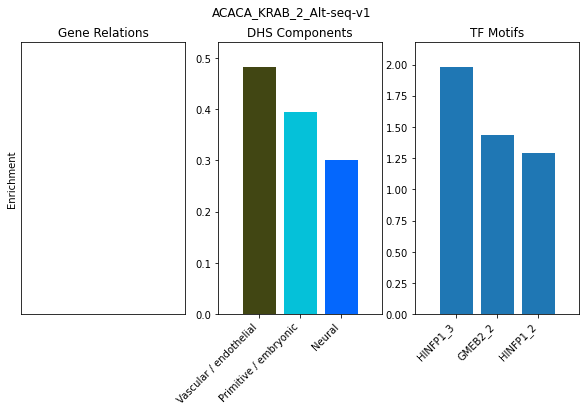

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_ACACA_KRAB_2_Alt-seq-v1


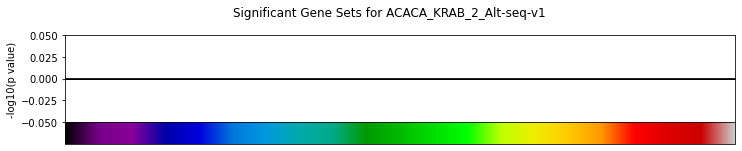

ACADSB_KRAB_5_Alt-seq-v1
original number of genes 2


<Figure size 720x720 with 0 Axes>

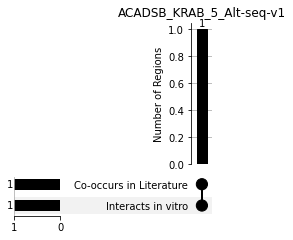

/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)
/tmp/ipykernel_154253/751357204.py:7: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)


inter-string shape (1, 11)
DHS shape (2, 16)
TF shape (2, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


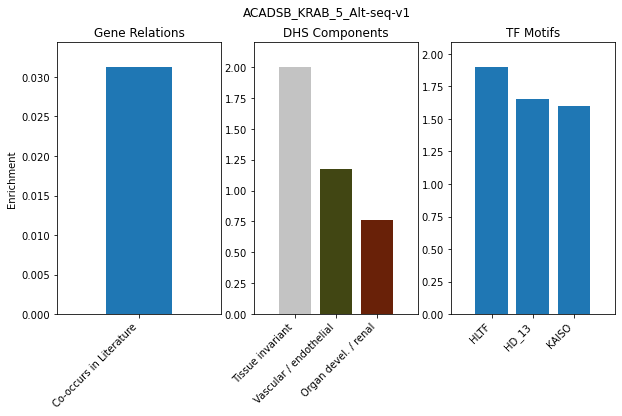

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_ACADSB_KRAB_5_Alt-seq-v1


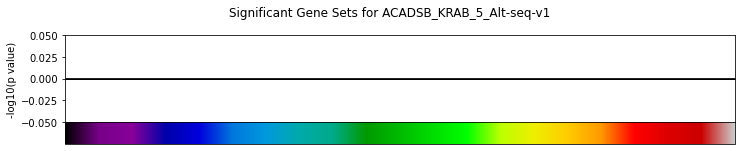

AK9_KRAB_2_Alt-seq-v0
original number of genes 2
inter-string shape (0, 11)
DHS shape (2, 16)
TF shape (2, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


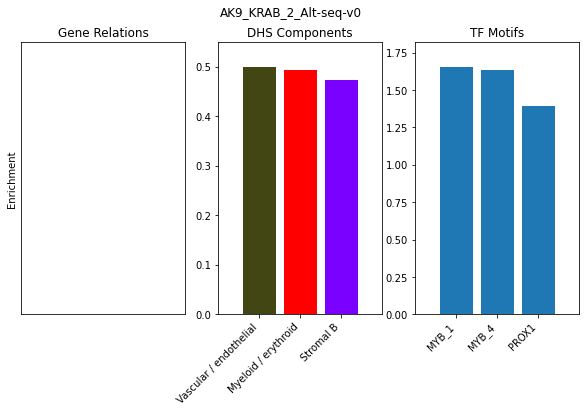

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_AK9_KRAB_2_Alt-seq-v0


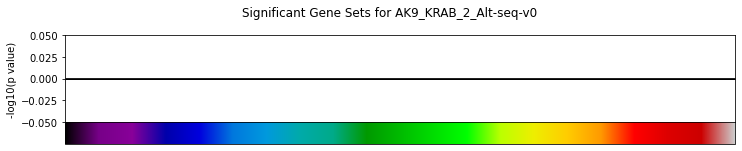

AK9_KRAB_2_mRNA
original number of genes 2
inter-string shape (0, 11)
DHS shape (2, 16)
TF shape (2, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


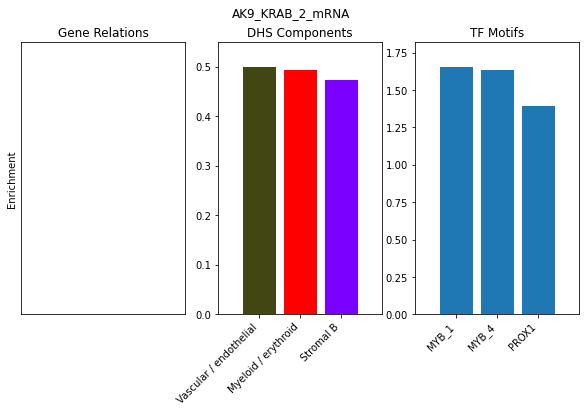

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_AK9_KRAB_2_mRNA


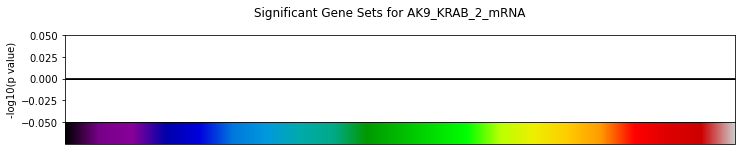

AK9_KRAB_5_mRNA
original number of genes 2
inter-string shape (0, 11)
DHS shape (2, 16)
TF shape (2, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


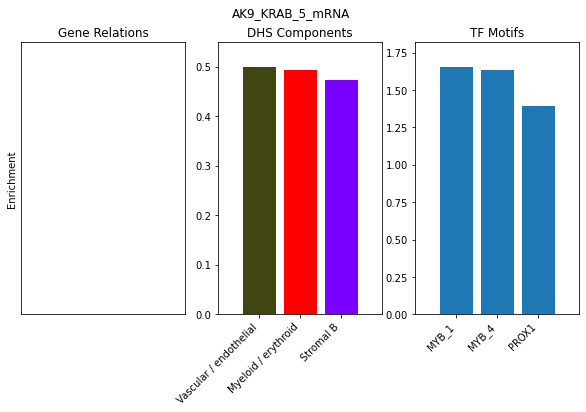

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_AK9_KRAB_5_mRNA


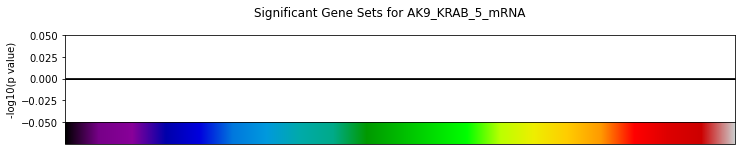

ALDH18A1_KRAB_2_Alt-seq-v1
original number of genes 6


<Figure size 720x720 with 0 Axes>

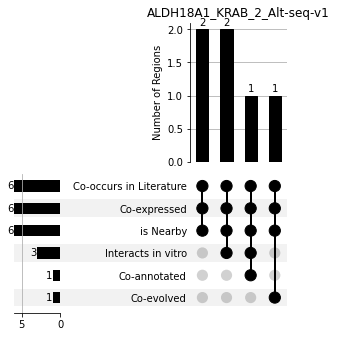

/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)


inter-string shape (6, 11)
DHS shape (6, 16)
TF shape (6, 282)


/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


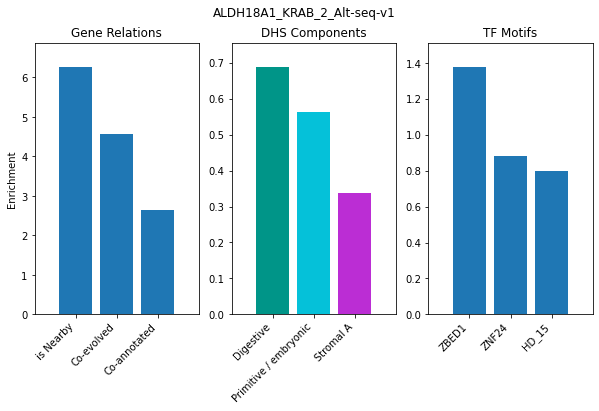

Significant_Gene_Sets_for_ALDH18A1_KRAB_2_Alt-seq-v1


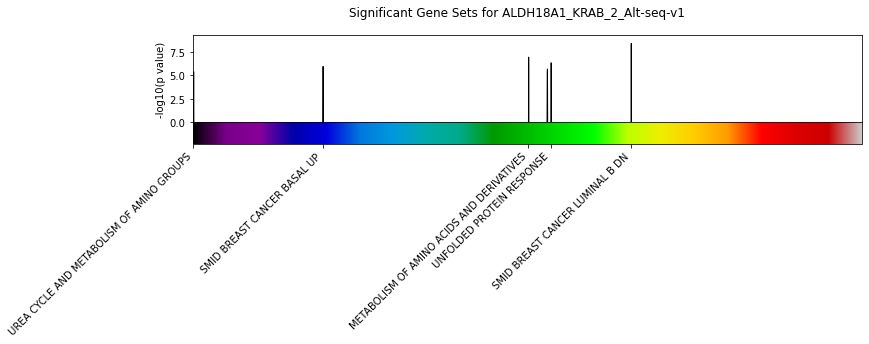

ALDH18A1_KRAB_2_mRNA
original number of genes 19


<Figure size 720x720 with 0 Axes>

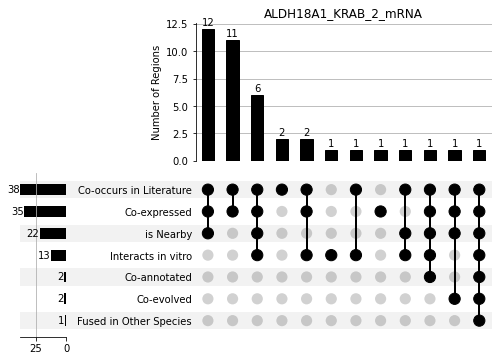

/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)


inter-string shape (40, 11)
DHS shape (19, 16)
TF shape (18, 282)


/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


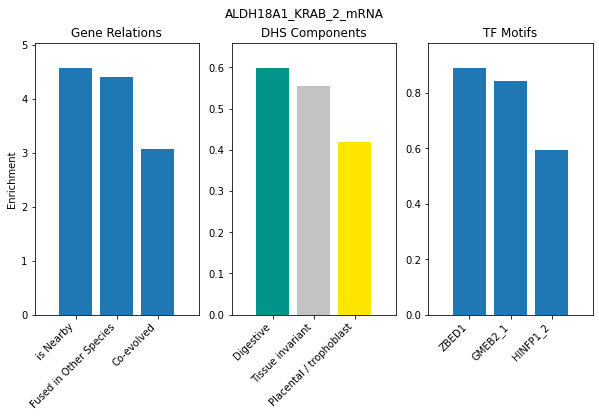

Significant_Gene_Sets_for_ALDH18A1_KRAB_2_mRNA


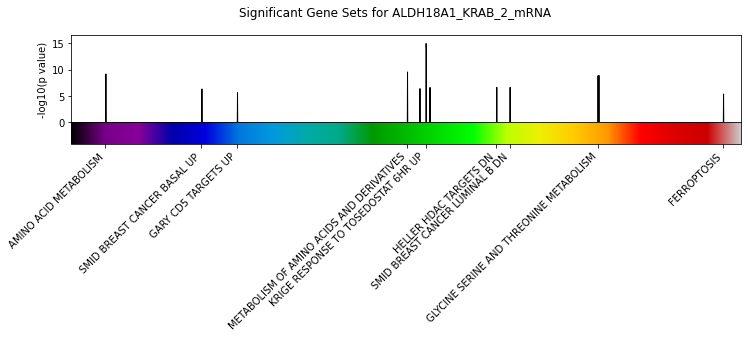

ALDH18A1_KRAB_5_Alt-seq-v1
original number of genes 10


<Figure size 720x720 with 0 Axes>

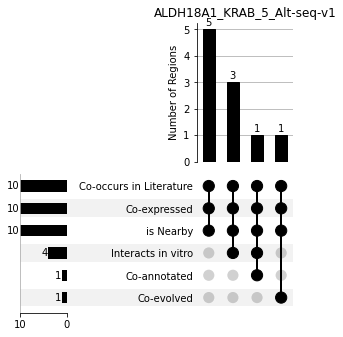

/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)


inter-string shape (10, 11)
DHS shape (10, 16)
TF shape (9, 282)


/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


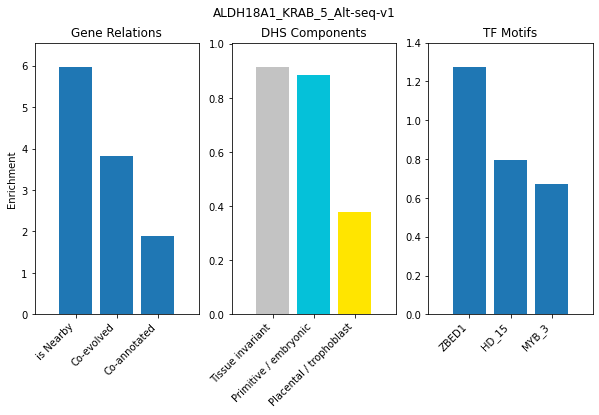

Significant_Gene_Sets_for_ALDH18A1_KRAB_5_Alt-seq-v1


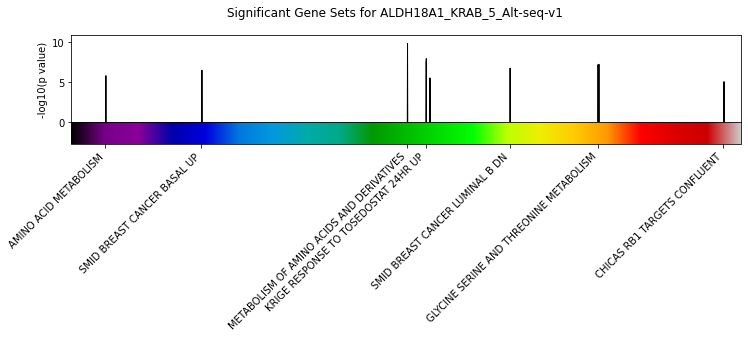

ATR_KRAB_5_mRNA
original number of genes 2
inter-string shape (0, 11)
DHS shape (2, 16)
TF shape (2, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


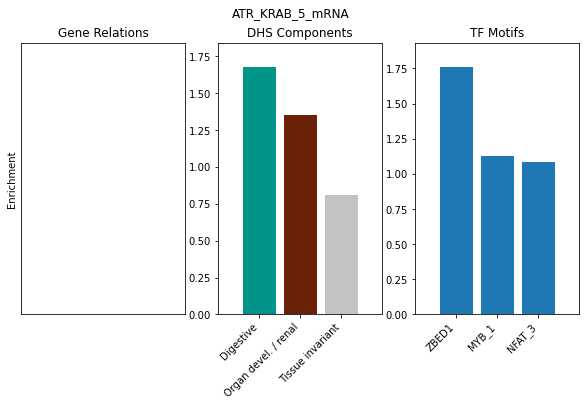

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_ATR_KRAB_5_mRNA


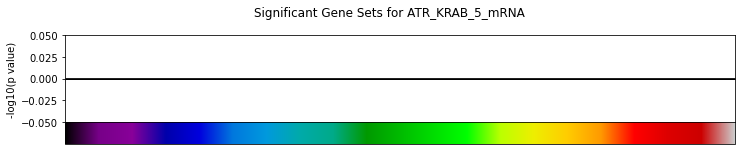

BATF_KRAB_5_Alt-seq-v1
original number of genes 14


<Figure size 720x720 with 0 Axes>

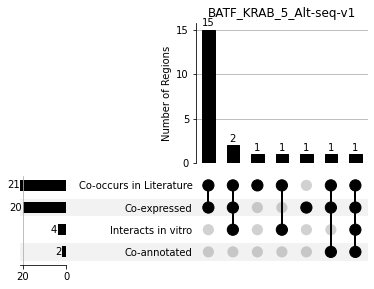

/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)


inter-string shape (22, 11)
DHS shape (12, 16)
TF shape (12, 282)


/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


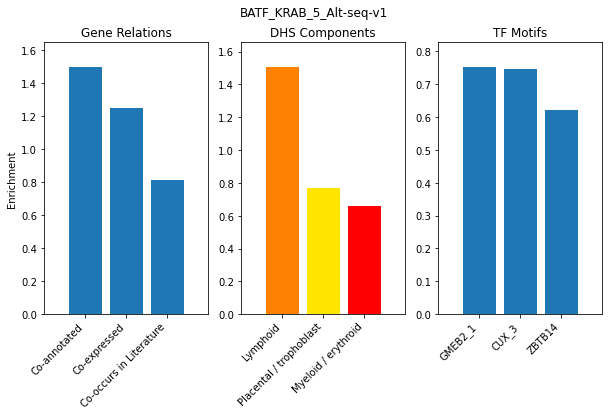

Significant_Gene_Sets_for_BATF_KRAB_5_Alt-seq-v1


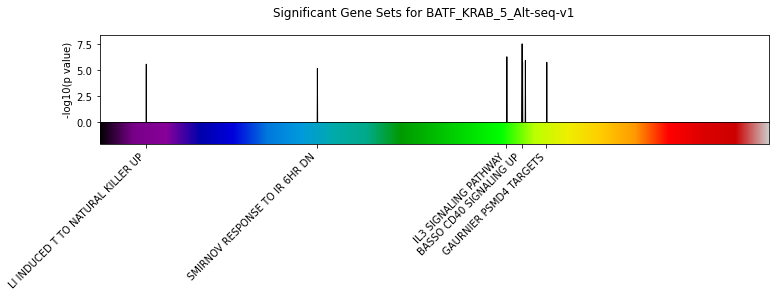

BATF_KRAB_8_Alt-seq-v1
original number of genes 3


<Figure size 720x720 with 0 Axes>

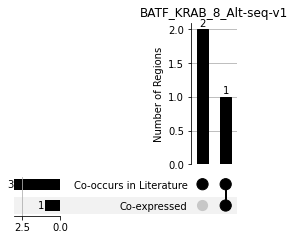

/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)


inter-string shape (3, 11)
DHS shape (3, 16)
TF shape (3, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


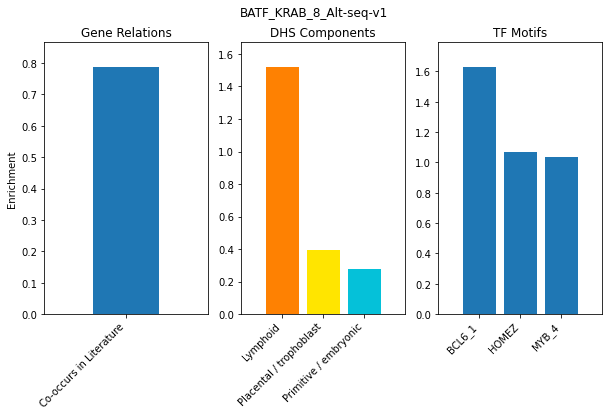

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_BATF_KRAB_8_Alt-seq-v1


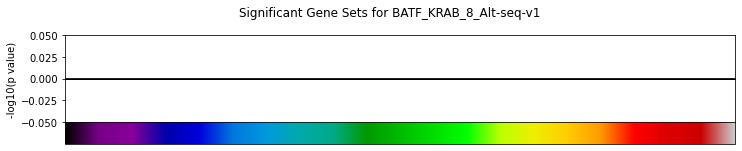

BRCA1_KRAB_2_mRNA
original number of genes 2
inter-string shape (0, 11)
DHS shape (2, 16)
TF shape (2, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


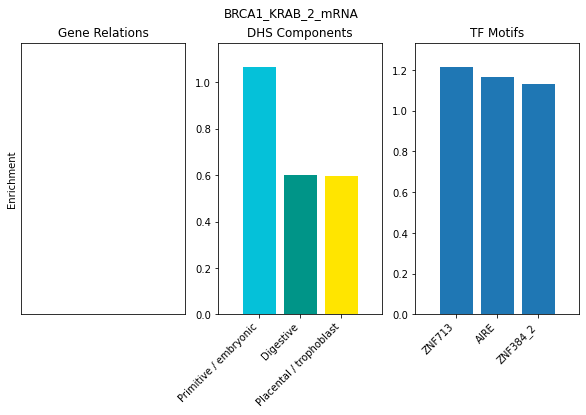

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_BRCA1_KRAB_2_mRNA


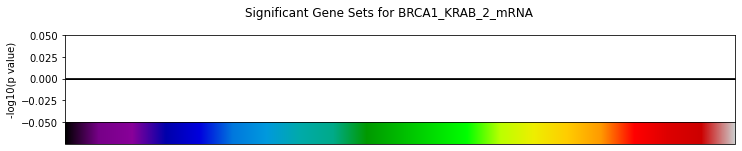

BRCA1_KRAB_5_mRNA
original number of genes 8


<Figure size 720x720 with 0 Axes>

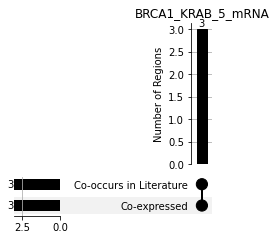

/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)


inter-string shape (3, 11)
DHS shape (7, 16)
TF shape (8, 282)


/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


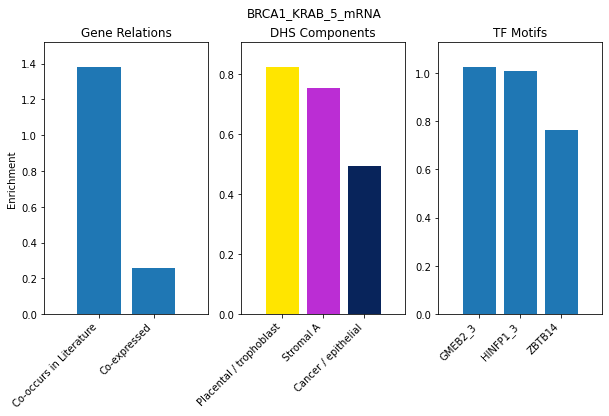

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_BRCA1_KRAB_5_mRNA


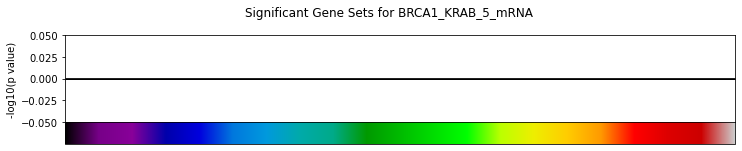

BRCA2_KRAB_2_mRNA
original number of genes 11


/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)


inter-string shape (3, 11)
DHS shape (7, 16)
TF shape (10, 282)


/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


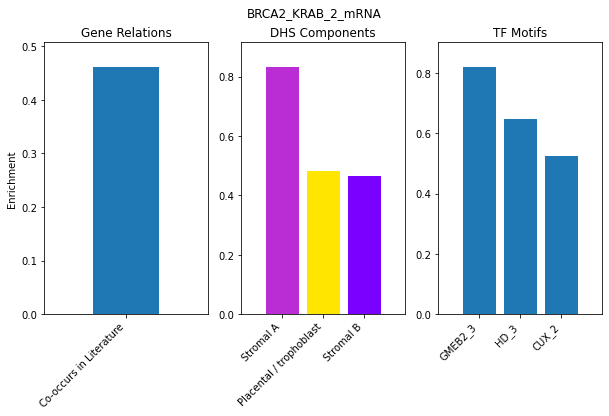

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_BRCA2_KRAB_2_mRNA


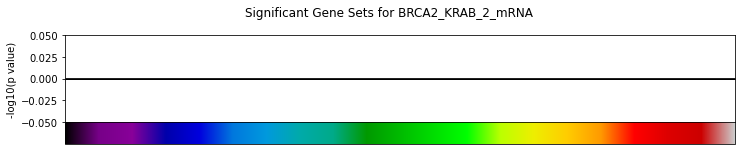

BRCA2_KRAB_5_mRNA
original number of genes 10


<Figure size 720x720 with 0 Axes>

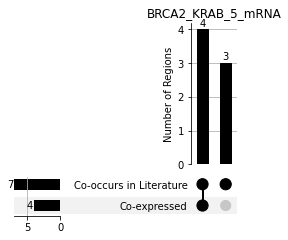

/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)


inter-string shape (7, 11)
DHS shape (9, 16)
TF shape (10, 282)


/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


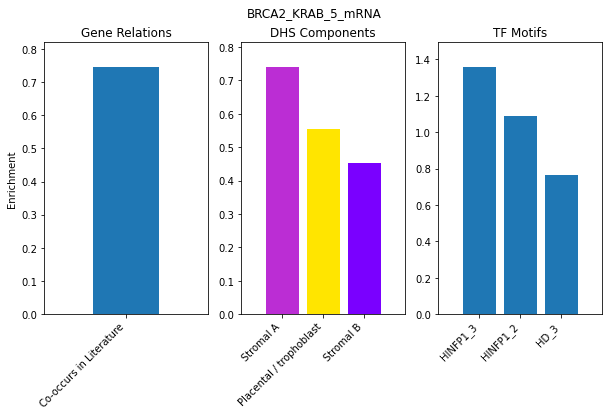

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_BRCA2_KRAB_5_mRNA


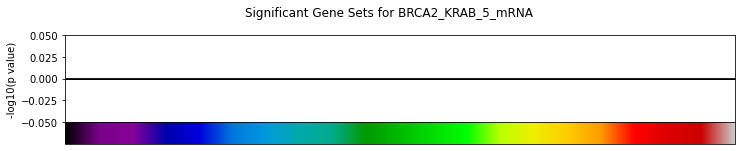

CD6_KRAB_5_Alt-seq-v1
original number of genes 2


/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)


inter-string shape (1, 11)
DHS shape (2, 16)
TF shape (1, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


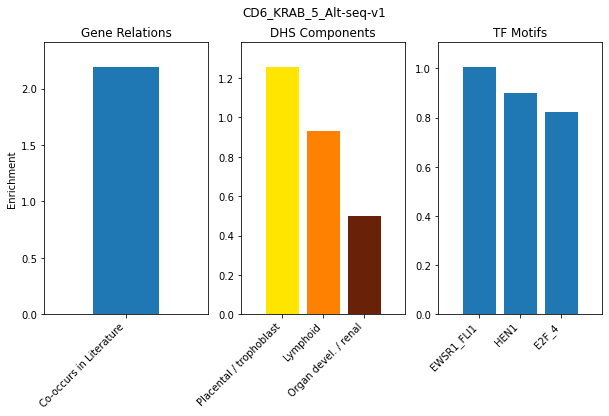

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_CD6_KRAB_5_Alt-seq-v1


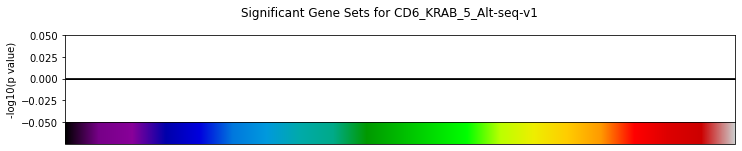

CDK2_VP64_2_Alt-seq-v1
original number of genes 2


<Figure size 720x720 with 0 Axes>

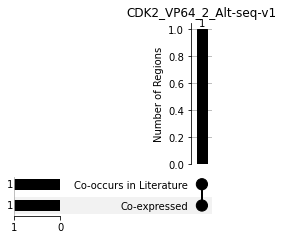

/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)
/tmp/ipykernel_154253/751357204.py:7: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)


inter-string shape (1, 11)
DHS shape (2, 16)
TF shape (2, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


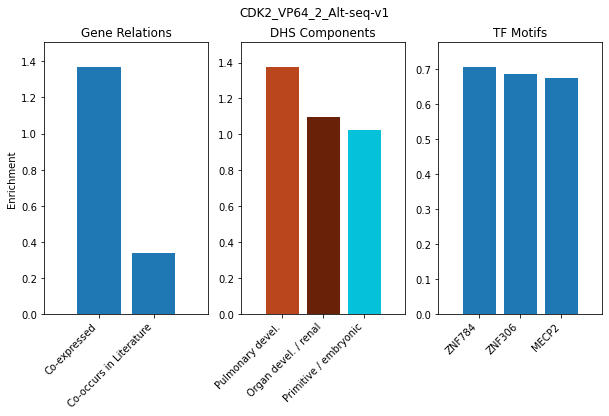

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_CDK2_VP64_2_Alt-seq-v1


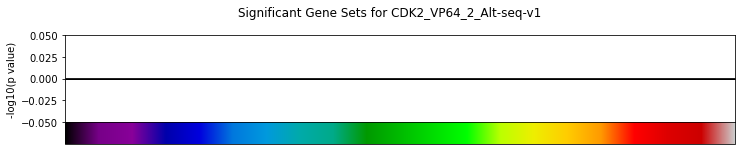

CHD4_KRAB_2_Alt-seq-v1
original number of genes 31


<Figure size 720x720 with 0 Axes>

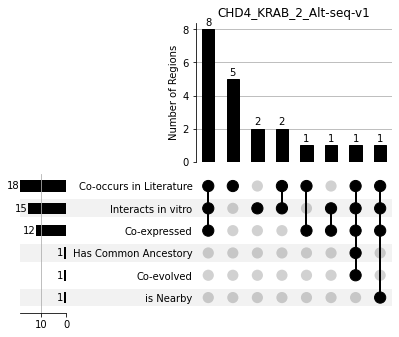

/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)


inter-string shape (21, 11)
DHS shape (29, 16)
TF shape (27, 282)


/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


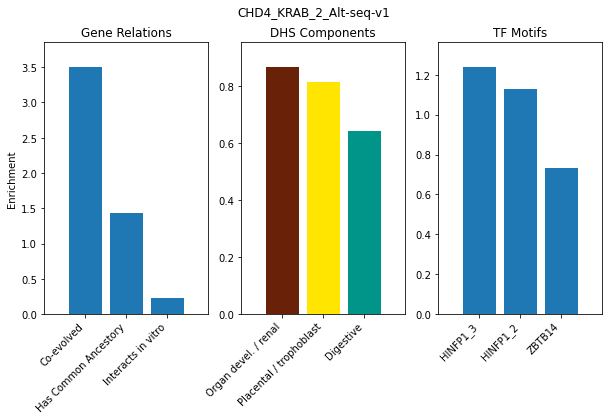

Significant_Gene_Sets_for_CHD4_KRAB_2_Alt-seq-v1


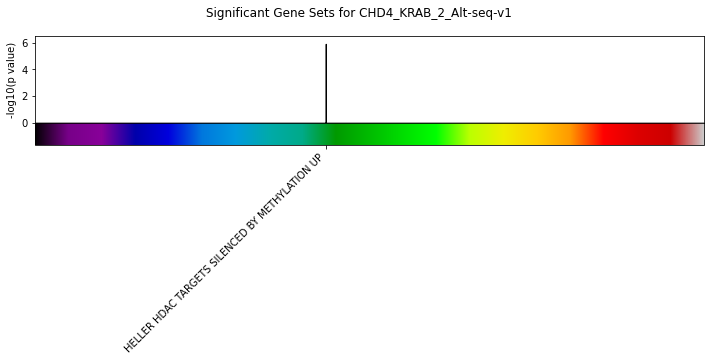

CHD4_KRAB_5_Alt-seq-v1
original number of genes 5
inter-string shape (0, 11)
DHS shape (4, 16)
TF shape (4, 282)


/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


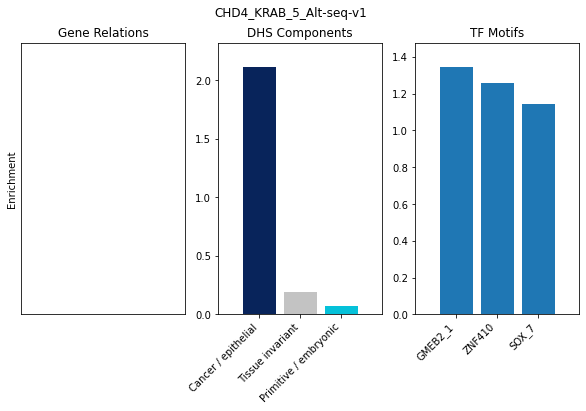

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_CHD4_KRAB_5_Alt-seq-v1


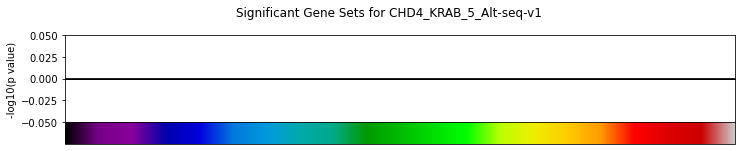

CHMP6_KRAB_5_Alt-seq-v1
original number of genes 3


<Figure size 720x720 with 0 Axes>

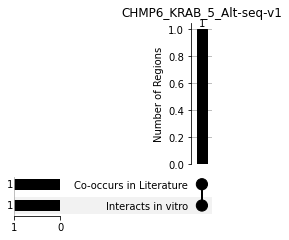

/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)


inter-string shape (1, 11)
DHS shape (3, 16)
TF shape (2, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


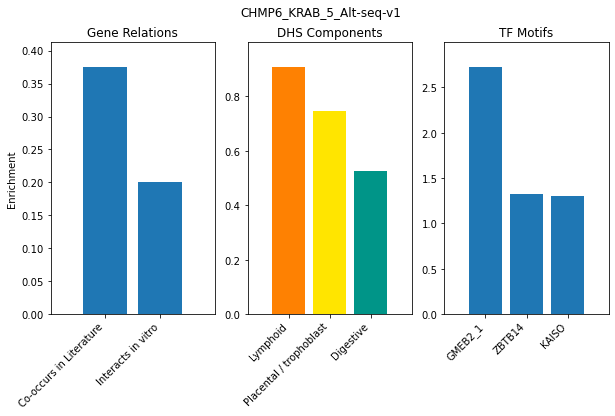

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_CHMP6_KRAB_5_Alt-seq-v1


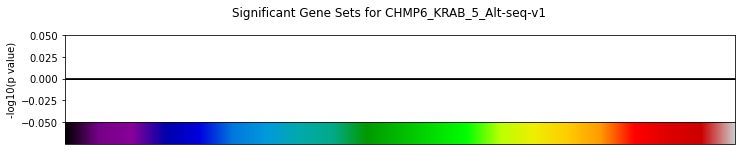

CLCN6_KRAB_2_mRNA
original number of genes 2


<Figure size 720x720 with 0 Axes>

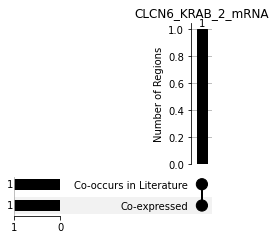

/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)
/tmp/ipykernel_154253/751357204.py:7: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)


inter-string shape (1, 11)
DHS shape (2, 16)
TF shape (2, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


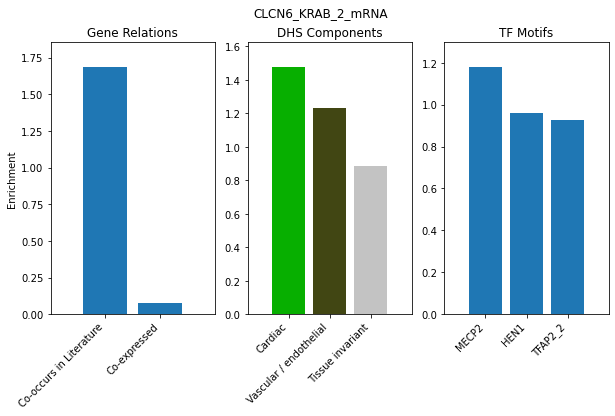

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_CLCN6_KRAB_2_mRNA


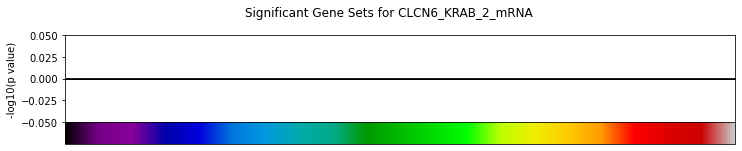

CLCN6_KRAB_5_Alt-seq-v1
original number of genes 2


<Figure size 720x720 with 0 Axes>

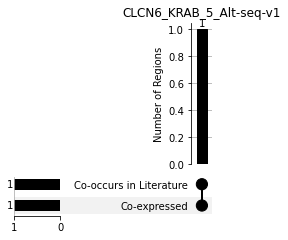

/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)
/tmp/ipykernel_154253/751357204.py:7: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)


inter-string shape (1, 11)
DHS shape (2, 16)
TF shape (2, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


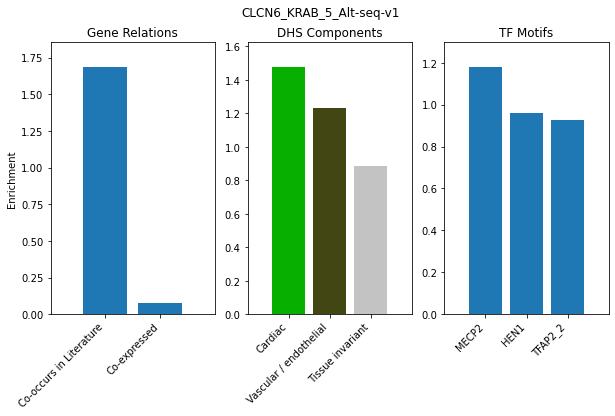

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_CLCN6_KRAB_5_Alt-seq-v1


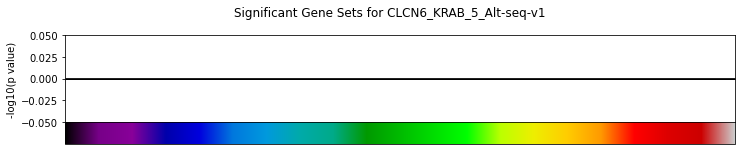

CLPB_KRAB_5_Alt-seq-v1
original number of genes 19


<Figure size 720x720 with 0 Axes>

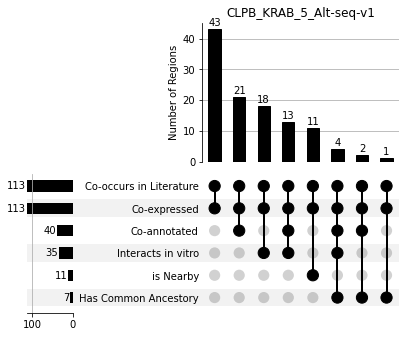

/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)


inter-string shape (113, 11)
DHS shape (19, 16)
TF shape (18, 282)


/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


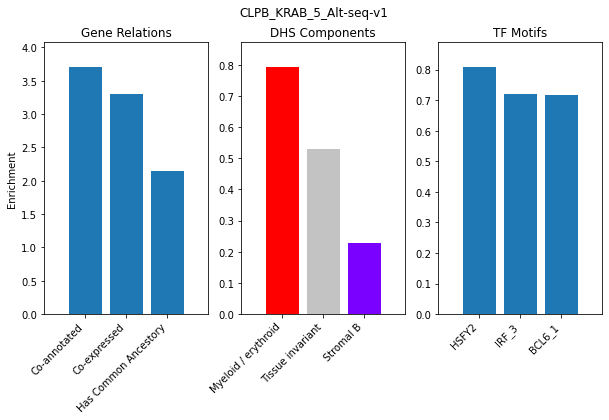

Significant_Gene_Sets_for_CLPB_KRAB_5_Alt-seq-v1


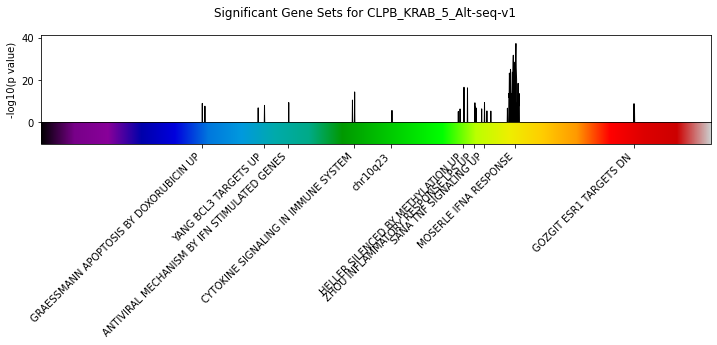

CLPB_KRAB_8_Alt-seq-v1
original number of genes 8


<Figure size 720x720 with 0 Axes>

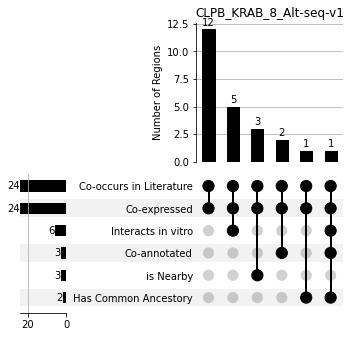

/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)


inter-string shape (24, 11)
DHS shape (8, 16)
TF shape (7, 282)


/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


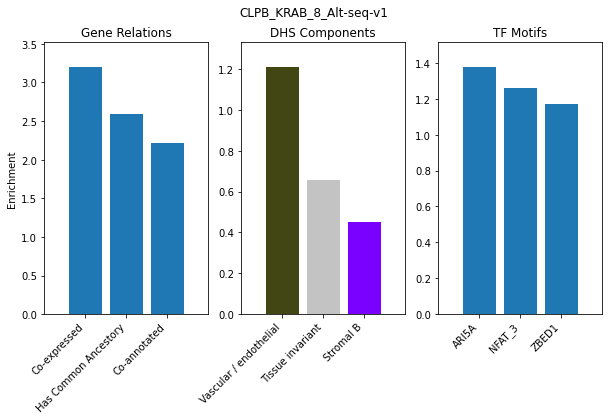

Significant_Gene_Sets_for_CLPB_KRAB_8_Alt-seq-v1


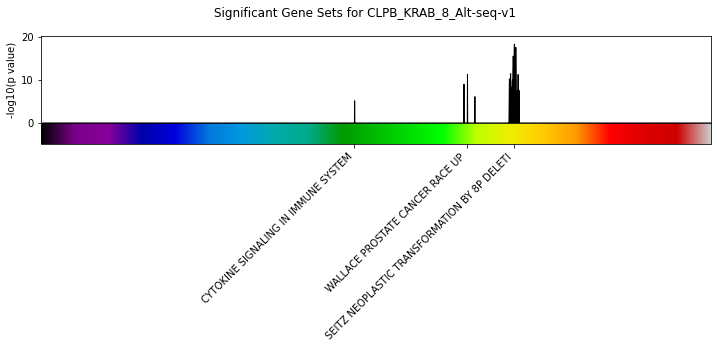

CMIP_KRAB_2_Alt-seq-v1
original number of genes 2
inter-string shape (0, 11)
DHS shape (2, 16)
TF shape (2, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


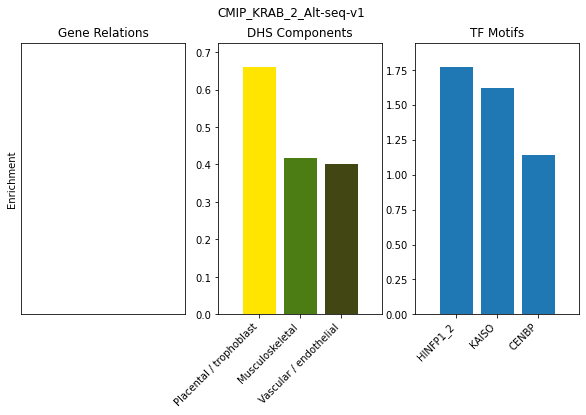

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_CMIP_KRAB_2_Alt-seq-v1


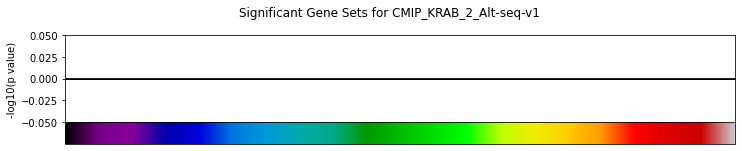

CSAD_KRAB_2_Alt-seq-v1
original number of genes 2
inter-string shape (0, 11)
DHS shape (2, 16)


/tmp/ipykernel_154253/751357204.py:7: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)


TF shape (2, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


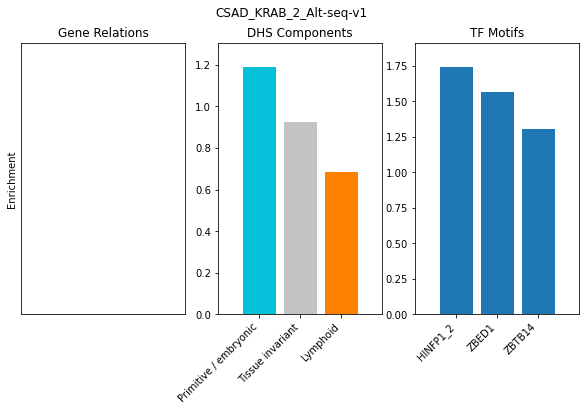

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_CSAD_KRAB_2_Alt-seq-v1


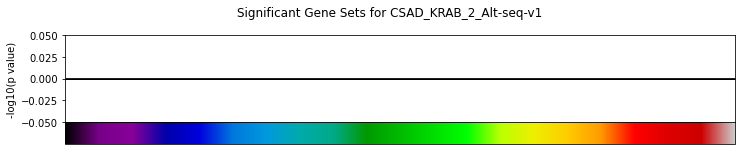

CTSL_KRAB_2_Alt-seq-v1
original number of genes 2


<Figure size 720x720 with 0 Axes>

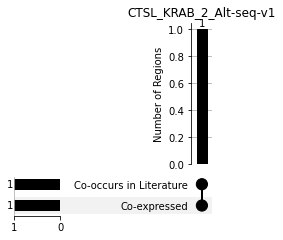

/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)


inter-string shape (1, 11)
DHS shape (2, 16)
TF shape (2, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


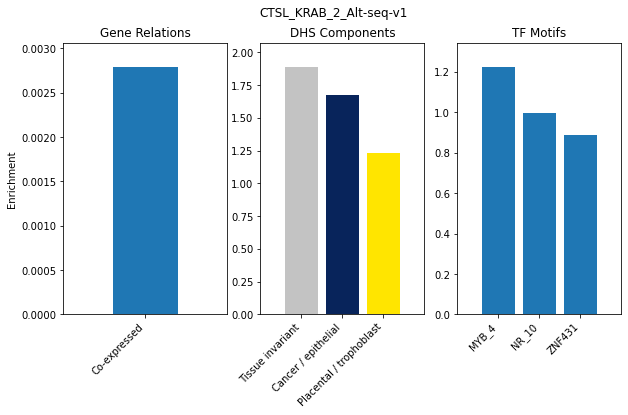

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_CTSL_KRAB_2_Alt-seq-v1


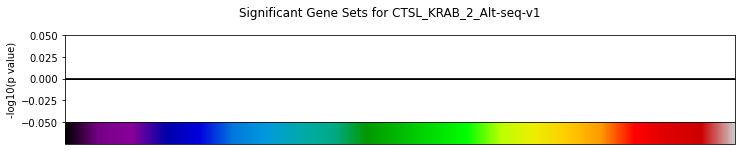

DCLRE1B_KRAB_2_Alt-seq-v0
original number of genes 2
inter-string shape (0, 11)
DHS shape (2, 16)
TF shape (2, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


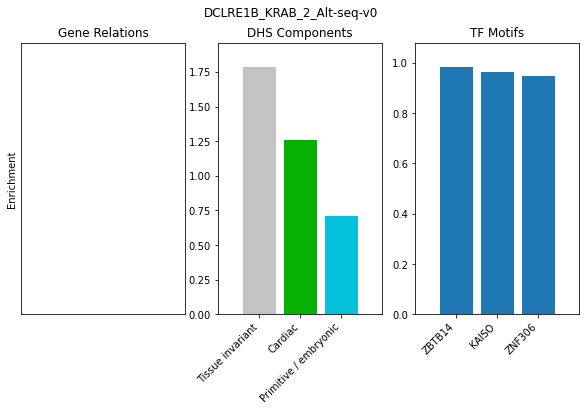

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_DCLRE1B_KRAB_2_Alt-seq-v0


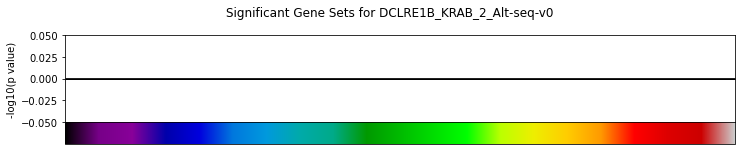

DCLRE1B_KRAB_2_Alt-seq-v1
original number of genes 3
inter-string shape (0, 11)
DHS shape (2, 16)
TF shape (3, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


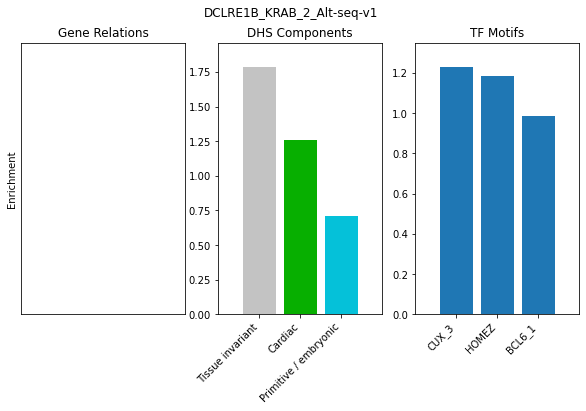

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_DCLRE1B_KRAB_2_Alt-seq-v1


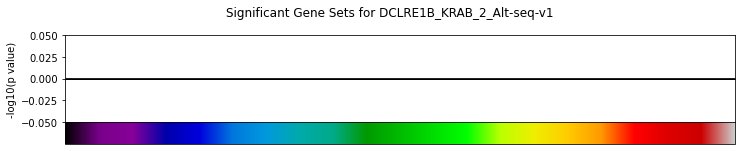

DDOST_KRAB_2_Alt-seq-v1
original number of genes 2
inter-string shape (0, 11)
DHS shape (1, 16)


/tmp/ipykernel_154253/751357204.py:7: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)


TF shape (2, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


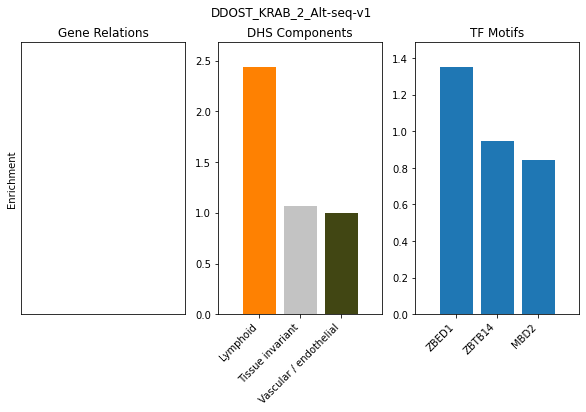

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_DDOST_KRAB_2_Alt-seq-v1


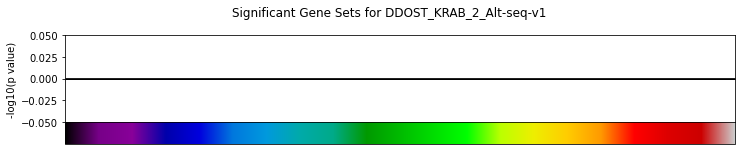

DEF6_VP64_2_Alt-seq-v2
original number of genes 3
inter-string shape (0, 11)
DHS shape (2, 16)
TF shape (1, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


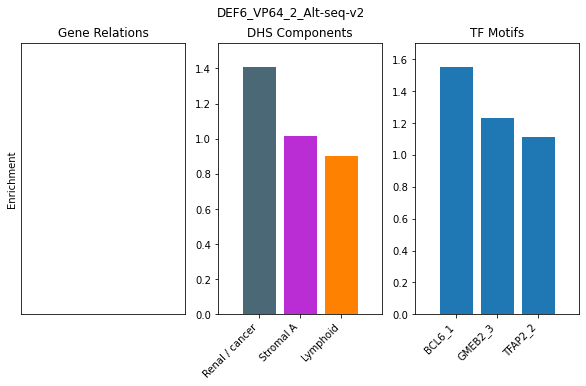

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_DEF6_VP64_2_Alt-seq-v2


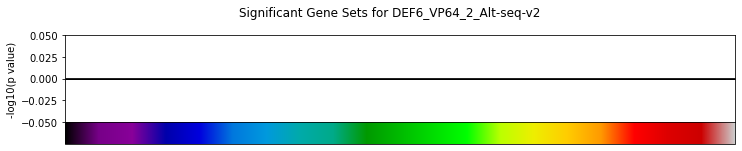

E4F1_KRAB_2_Alt-seq-v1
original number of genes 3
inter-string shape (0, 11)
DHS shape (2, 16)


/tmp/ipykernel_154253/751357204.py:7: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)


TF shape (1, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


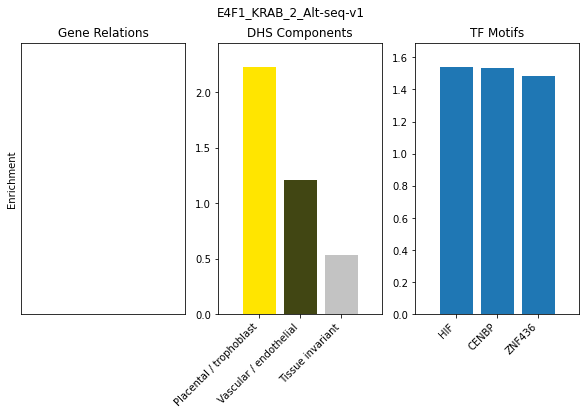

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_E4F1_KRAB_2_Alt-seq-v1


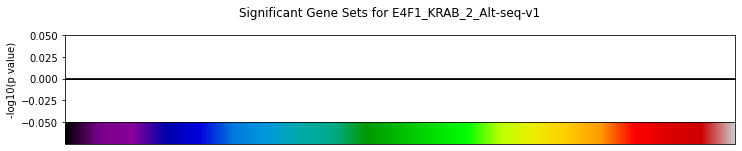

E4F1_KRAB_8_Alt-seq-v1
original number of genes 2
inter-string shape (0, 11)
DHS shape (2, 16)


/tmp/ipykernel_154253/751357204.py:7: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)


TF shape (2, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


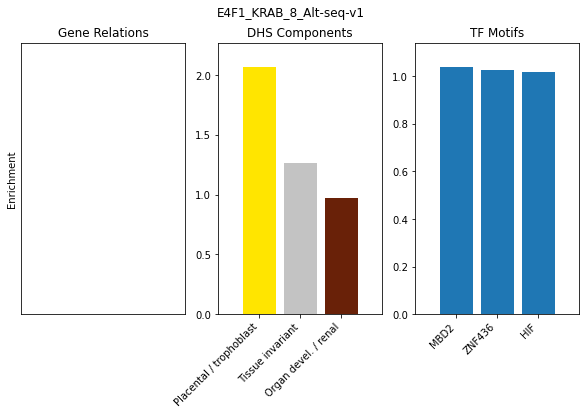

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_E4F1_KRAB_8_Alt-seq-v1


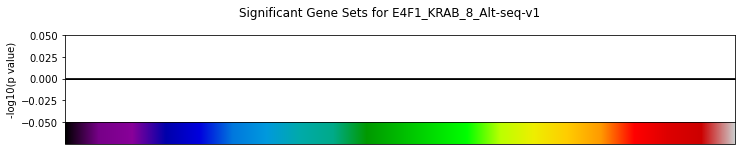

EVL_KRAB_2_Alt-seq-v1
original number of genes 3
inter-string shape (0, 11)
DHS shape (2, 16)
TF shape (2, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


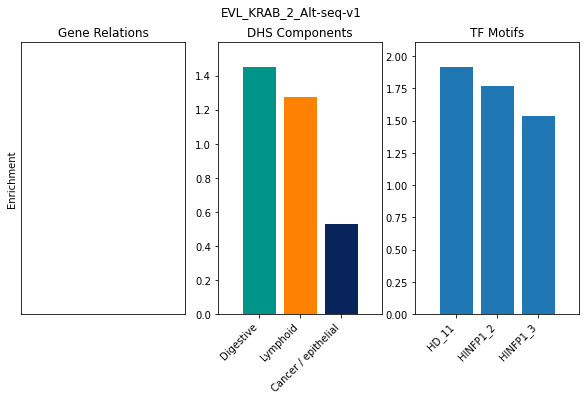

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_EVL_KRAB_2_Alt-seq-v1


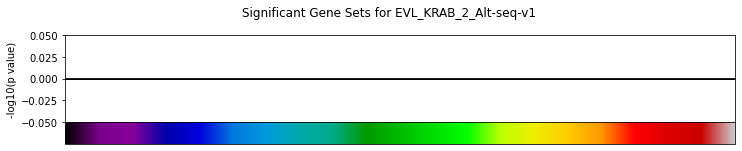

EXOC4_KRAB_8_Alt-seq-v1
original number of genes 2
inter-string shape (0, 11)
DHS shape (2, 16)
TF shape (2, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


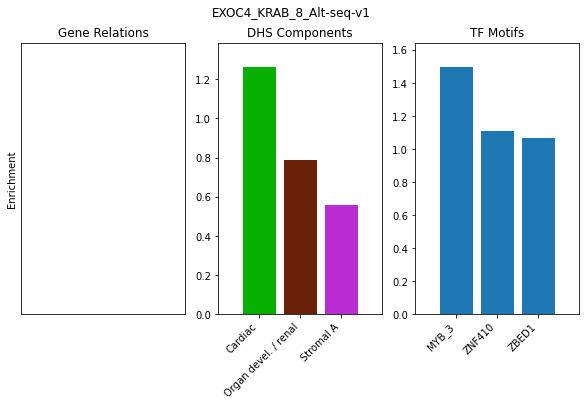

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_EXOC4_KRAB_8_Alt-seq-v1


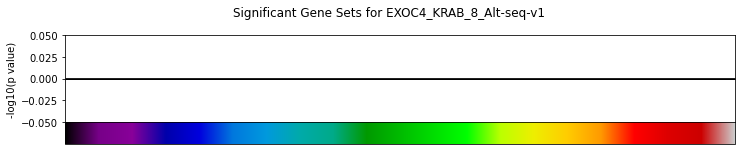

FAS_KRAB_2_Alt-seq-v0
original number of genes 2
inter-string shape (0, 11)
DHS shape (2, 16)
TF shape (1, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


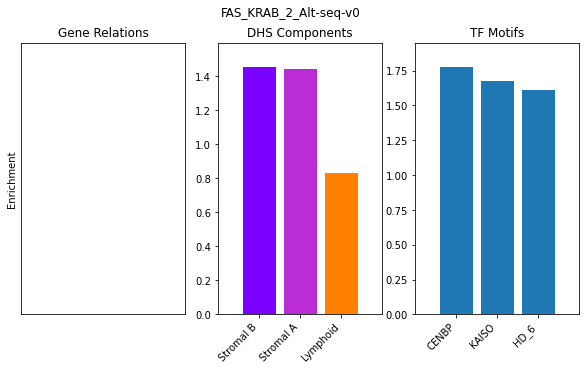

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_FAS_KRAB_2_Alt-seq-v0


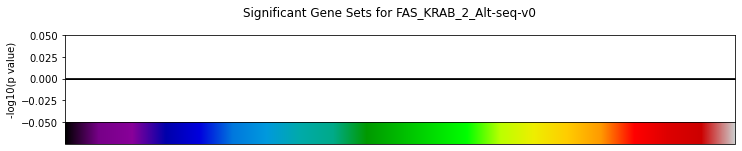

FAS_KRAB_2_mRNA
original number of genes 2
inter-string shape (0, 11)
DHS shape (1, 16)


/tmp/ipykernel_154253/751357204.py:7: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)


TF shape (0, 282)


/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/numpy/core/fromnumeric.py:3440: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/numpy/core/_methods.py:181: RuntimeWarning: invalid value encountered in true_divide
  ret = um.true_divide(
/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])
/tmp/ipykernel_154253/751357204.py:85: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[2].set_ylim([0, max_val_TF*1.1])


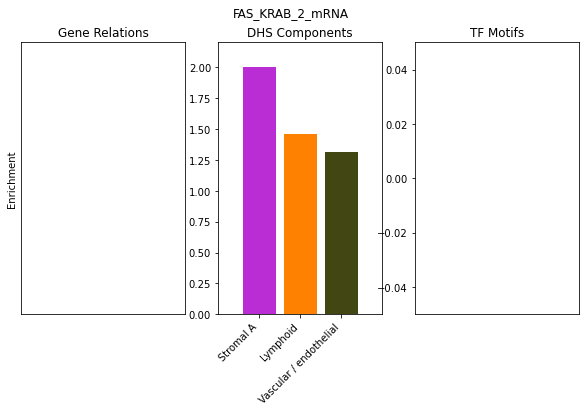

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_FAS_KRAB_2_mRNA


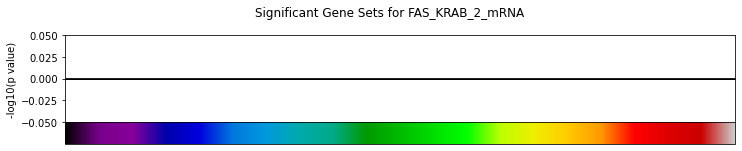

FAS_KRAB_5_mRNA
original number of genes 3
inter-string shape (0, 11)
DHS shape (2, 16)
TF shape (1, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


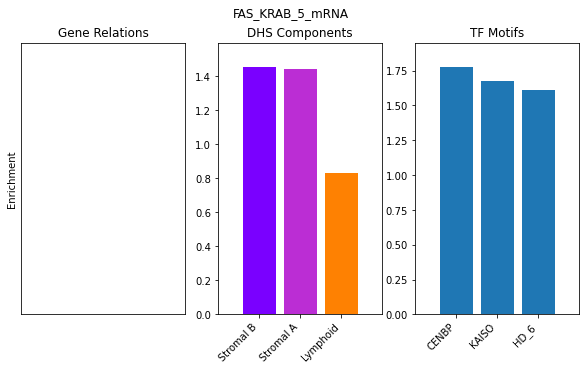

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_FAS_KRAB_5_mRNA


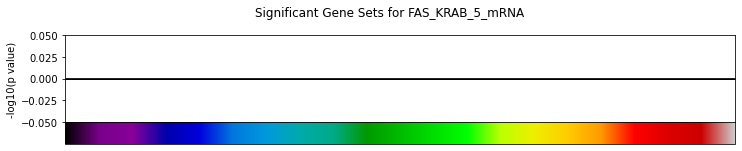

FERMT3_KRAB_5_Alt-seq-v1
original number of genes 2
inter-string shape (0, 11)
DHS shape (2, 16)


/tmp/ipykernel_154253/751357204.py:7: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)


TF shape (2, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


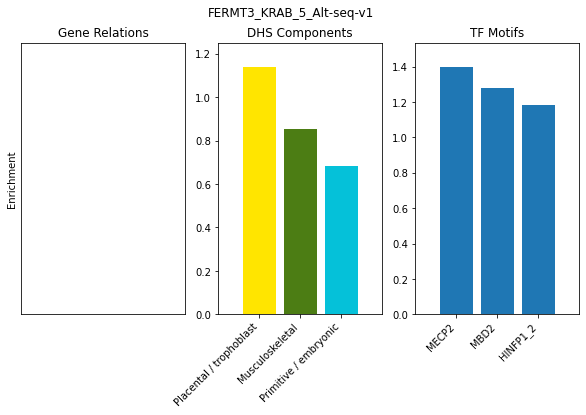

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_FERMT3_KRAB_5_Alt-seq-v1


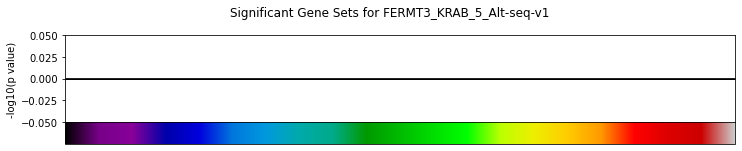

GBP4_KRAB_2_Alt-seq-v1
original number of genes 2
inter-string shape (0, 11)
DHS shape (1, 16)


/tmp/ipykernel_154253/751357204.py:7: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)


TF shape (1, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


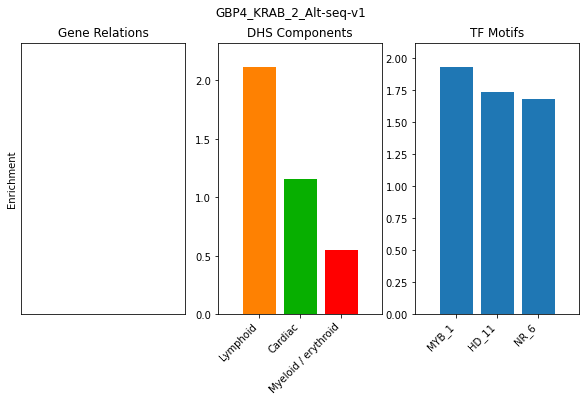

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_GBP4_KRAB_2_Alt-seq-v1


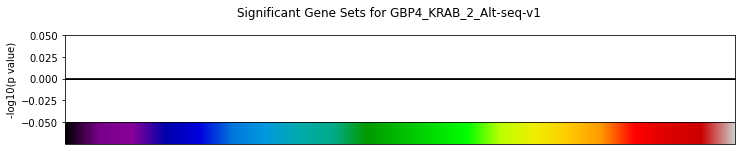

GBP4_KRAB_5_Alt-seq-v1
original number of genes 2
inter-string shape (0, 11)
DHS shape (1, 16)


/tmp/ipykernel_154253/751357204.py:7: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)


TF shape (1, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


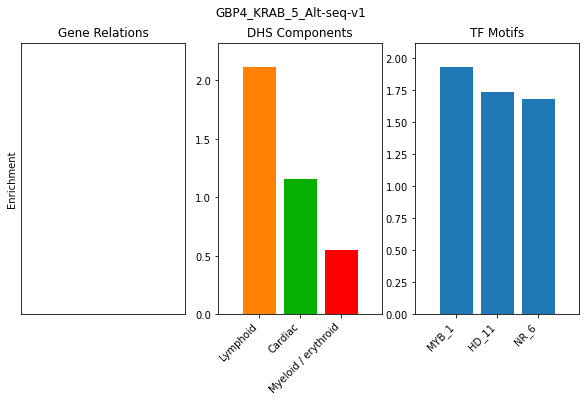

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_GBP4_KRAB_5_Alt-seq-v1


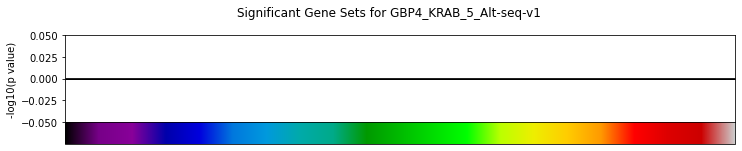

GBP4_KRAB_8_Alt-seq-v1
original number of genes 2
inter-string shape (0, 11)
DHS shape (1, 16)


/tmp/ipykernel_154253/751357204.py:7: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)


TF shape (1, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


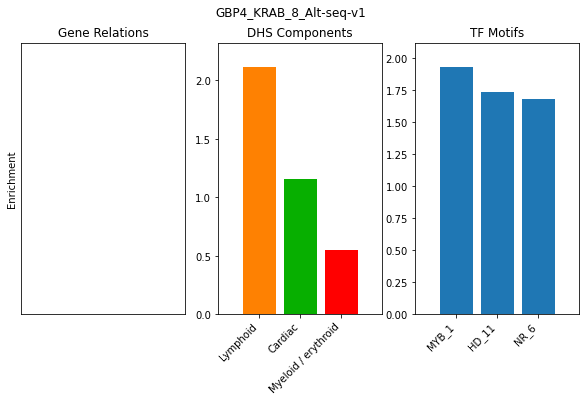

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_GBP4_KRAB_8_Alt-seq-v1


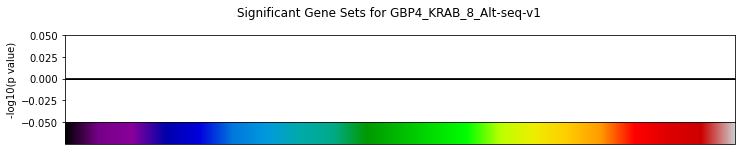

GFM1_KRAB_2_Alt-seq-v1
original number of genes 2
inter-string shape (0, 11)
DHS shape (2, 16)
TF shape (2, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


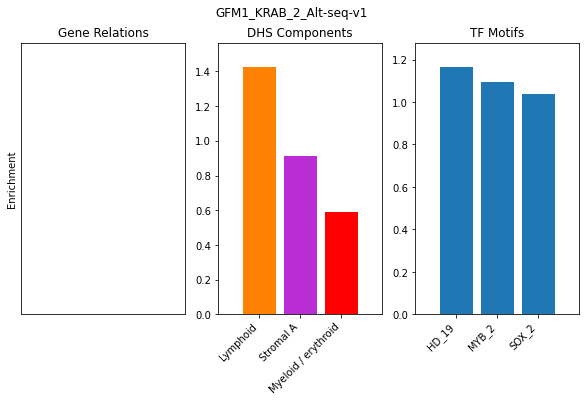

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_GFM1_KRAB_2_Alt-seq-v1


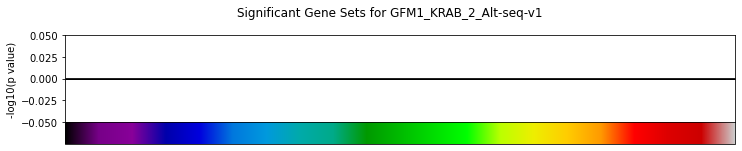

GPR65_KRAB_5_Alt-seq-v1
original number of genes 2
inter-string shape (0, 11)
DHS shape (1, 16)


/tmp/ipykernel_154253/751357204.py:7: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)


TF shape (2, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


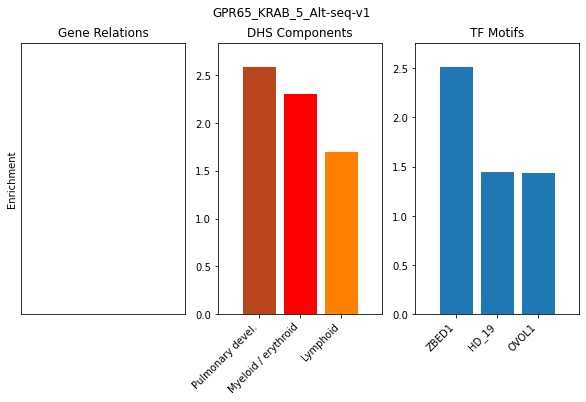

Significant_Gene_Sets_for_GPR65_KRAB_5_Alt-seq-v1


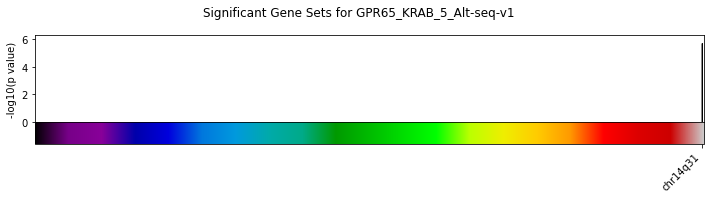

GSTM2_KRAB_2_Alt-seq-v1
original number of genes 2


<Figure size 720x720 with 0 Axes>

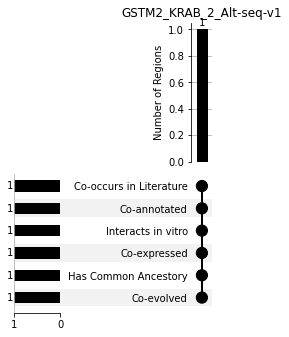

/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)
/tmp/ipykernel_154253/751357204.py:7: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)


inter-string shape (1, 11)
DHS shape (2, 16)
TF shape (2, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


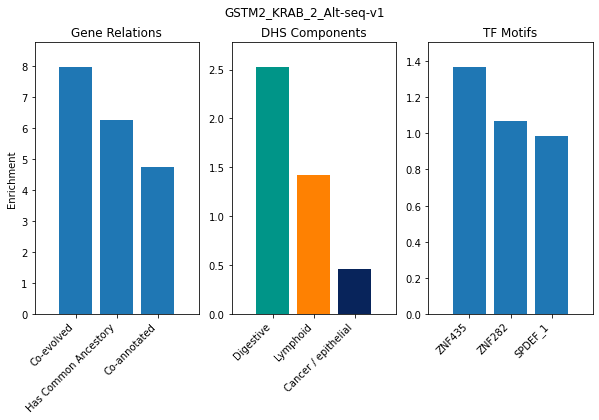

Significant_Gene_Sets_for_GSTM2_KRAB_2_Alt-seq-v1


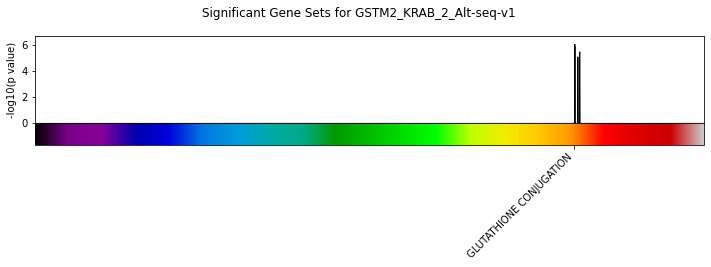

GSTM2_KRAB_5_Alt-seq-v1
original number of genes 2


<Figure size 720x720 with 0 Axes>

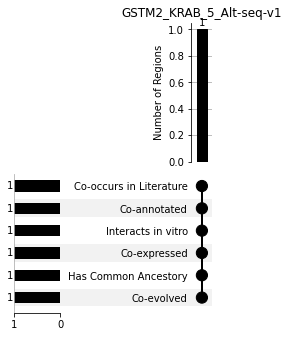

/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)
/tmp/ipykernel_154253/751357204.py:7: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)


inter-string shape (1, 11)
DHS shape (2, 16)
TF shape (2, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


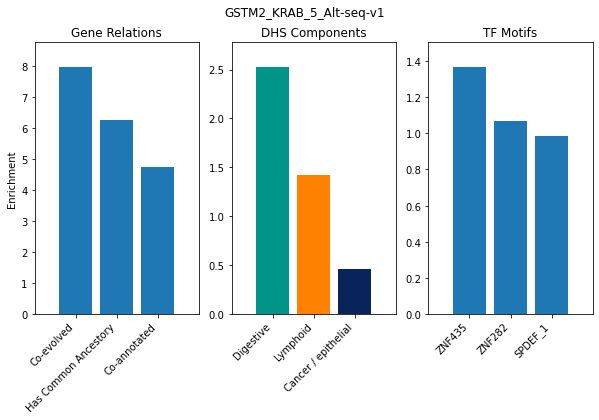

Significant_Gene_Sets_for_GSTM2_KRAB_5_Alt-seq-v1


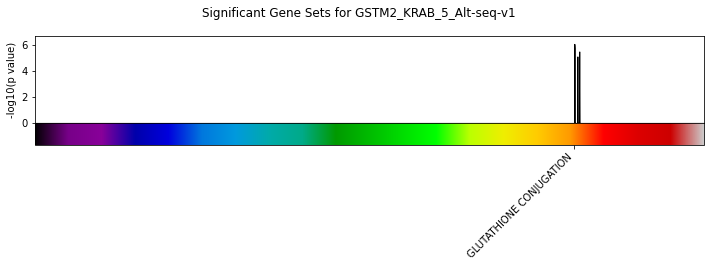

GTF2B_VP64_2_Alt-seq-v1
original number of genes 2
inter-string shape (0, 11)
DHS shape (2, 16)
TF shape (2, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


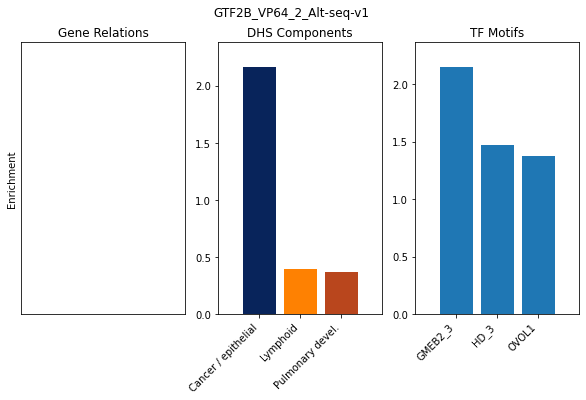

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_GTF2B_VP64_2_Alt-seq-v1


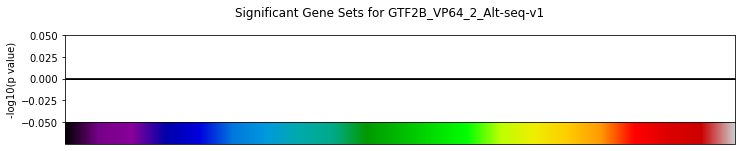

HDAC1_KRAB_2_Alt-seq-v1
original number of genes 2
inter-string shape (0, 11)
DHS shape (2, 16)


/tmp/ipykernel_154253/751357204.py:7: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)


TF shape (2, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


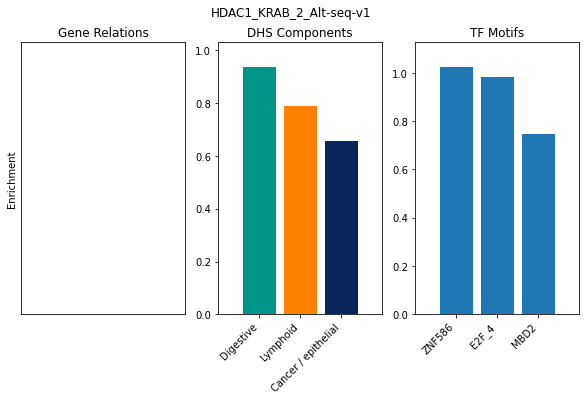

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_HDAC1_KRAB_2_Alt-seq-v1


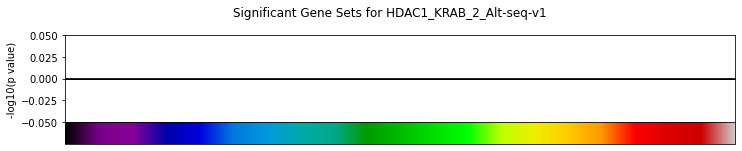

HDAC1_KRAB_5_Alt-seq-v1
original number of genes 2
inter-string shape (0, 11)
DHS shape (2, 16)


/tmp/ipykernel_154253/751357204.py:7: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)


TF shape (2, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


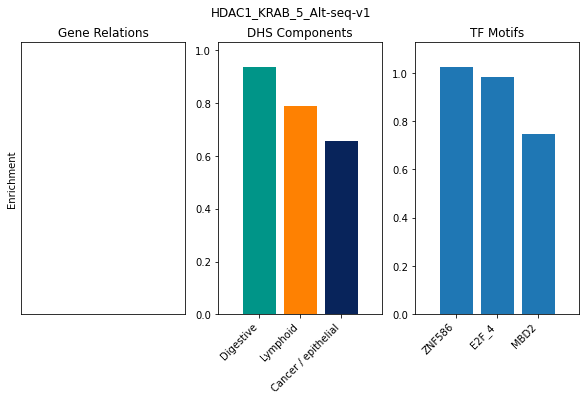

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_HDAC1_KRAB_5_Alt-seq-v1


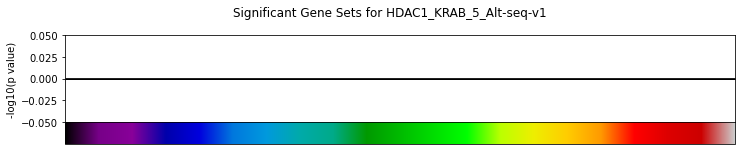

HIF1AN_KRAB_2_Alt-seq-v1
original number of genes 2
inter-string shape (0, 11)
DHS shape (2, 16)


/tmp/ipykernel_154253/751357204.py:7: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)


TF shape (2, 282)


/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


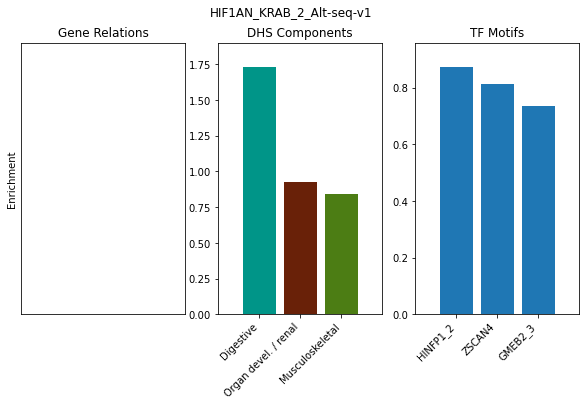

Significant_Gene_Sets_for_HIF1AN_KRAB_2_Alt-seq-v1


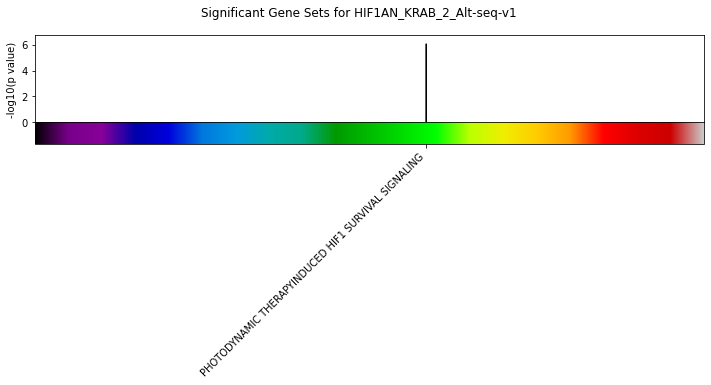

HLA-DQB1_KRAB_2_Alt-seq-v1
original number of genes 2


<Figure size 720x720 with 0 Axes>

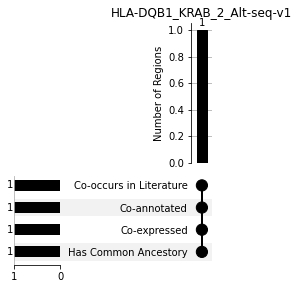

/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)
/tmp/ipykernel_154253/751357204.py:7: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)


inter-string shape (1, 11)
DHS shape (2, 16)
TF shape (2, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


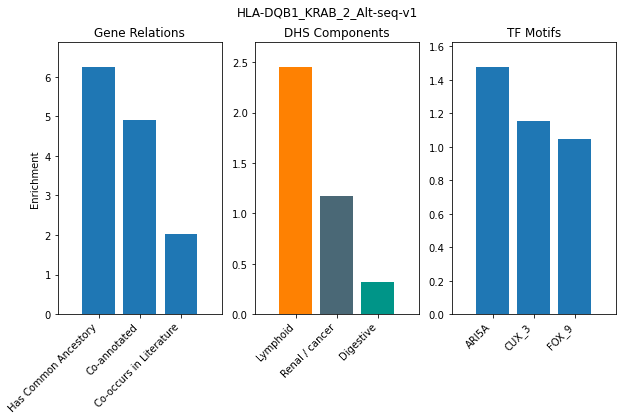

Significant_Gene_Sets_for_HLA-DQB1_KRAB_2_Alt-seq-v1


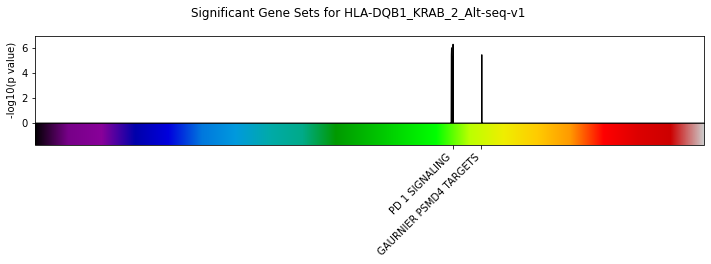

IL2RA_KRAB_5_Alt-seq-v1
original number of genes 192


<Figure size 720x720 with 0 Axes>

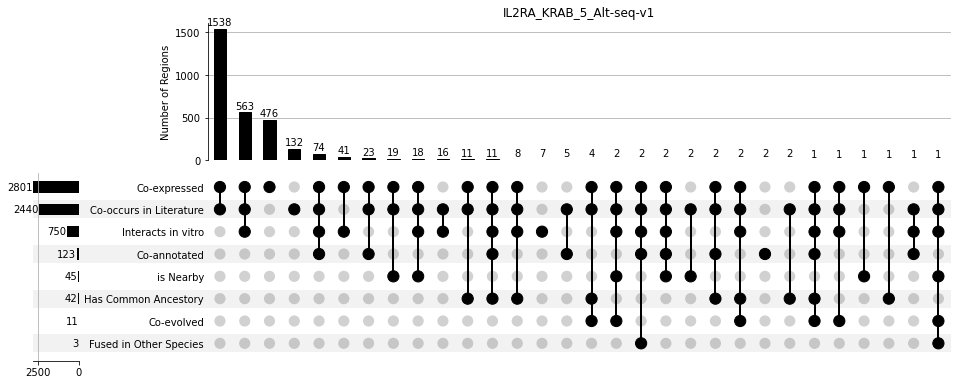

/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)


inter-string shape (2968, 11)
DHS shape (172, 16)
TF shape (169, 282)


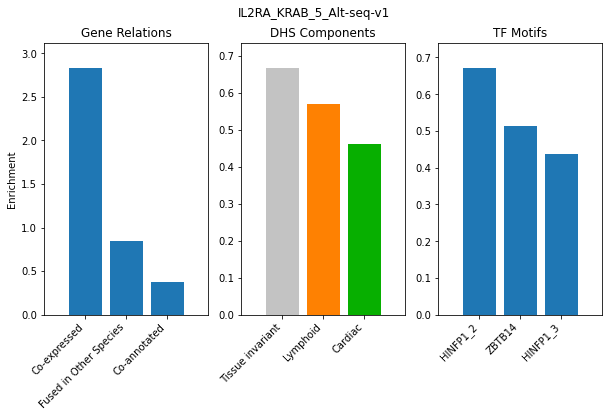

Significant_Gene_Sets_for_IL2RA_KRAB_5_Alt-seq-v1


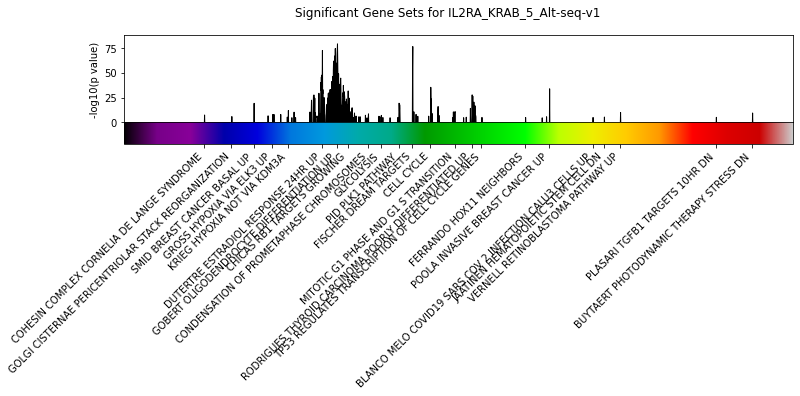

IL2RB_KRAB_2_Alt-seq-v1
original number of genes 19


<Figure size 720x720 with 0 Axes>

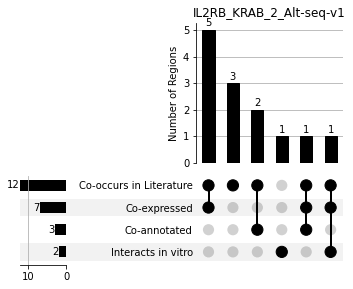

/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)


inter-string shape (13, 11)
DHS shape (18, 16)
TF shape (15, 282)


/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


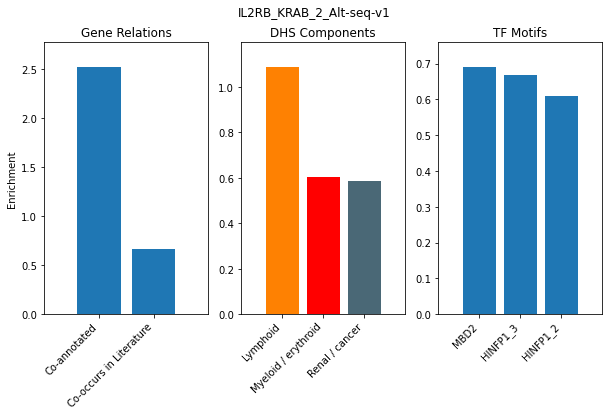

Significant_Gene_Sets_for_IL2RB_KRAB_2_Alt-seq-v1


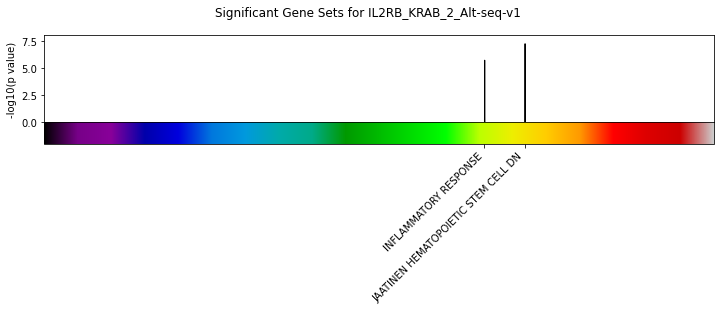

ITGB7_VP64_2_Alt-seq-v1
original number of genes 18


<Figure size 720x720 with 0 Axes>

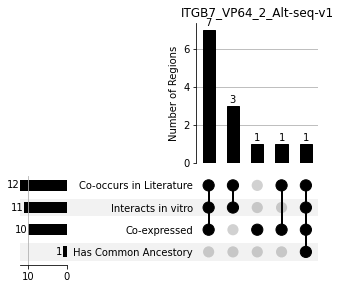

/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)


inter-string shape (13, 11)
DHS shape (14, 16)
TF shape (14, 282)


/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


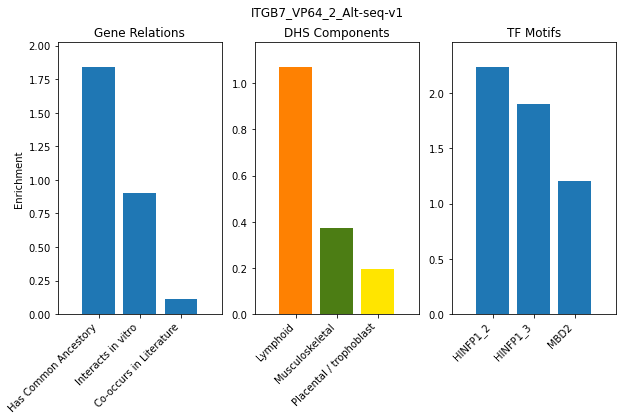

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_ITGB7_VP64_2_Alt-seq-v1


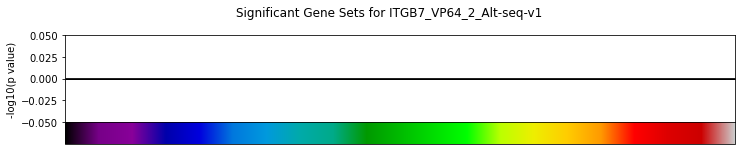

KRAS_VP64_8_Alt-seq-v1
original number of genes 3


<Figure size 720x720 with 0 Axes>

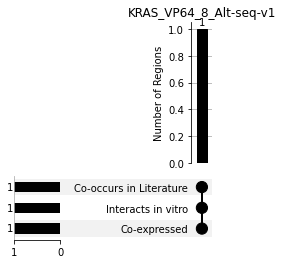

/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)


inter-string shape (1, 11)
DHS shape (3, 16)
TF shape (3, 282)


/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


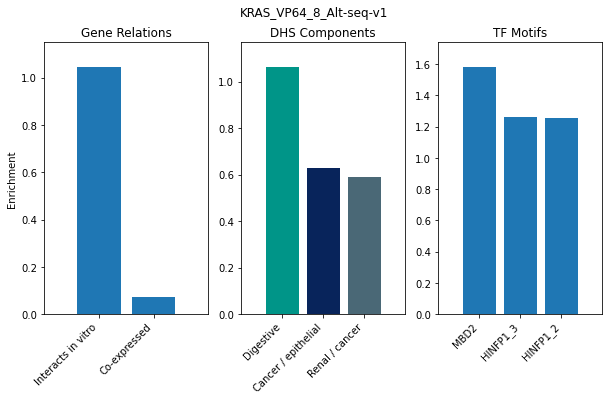

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_KRAS_VP64_8_Alt-seq-v1


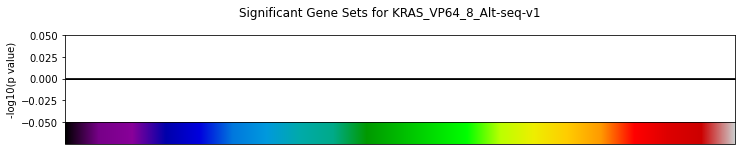

LHX4_VP64_5_Alt-seq-v1
original number of genes 3
inter-string shape (0, 11)
DHS shape (1, 16)


/tmp/ipykernel_154253/751357204.py:7: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)


TF shape (1, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


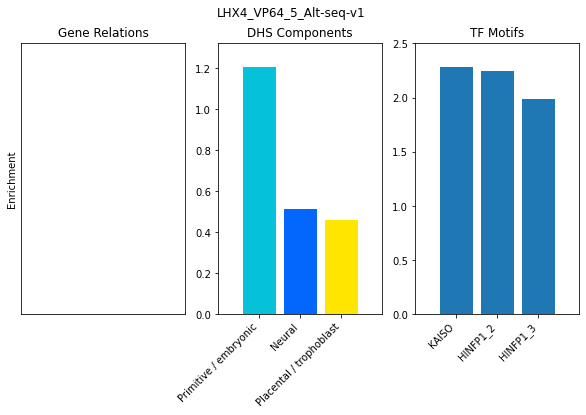

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_LHX4_VP64_5_Alt-seq-v1


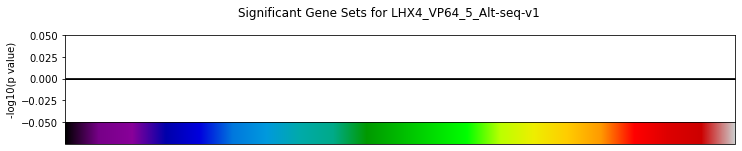

LMTK2_VP64_2_Alt-seq-v1
original number of genes 3
inter-string shape (0, 11)
DHS shape (2, 16)
TF shape (2, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


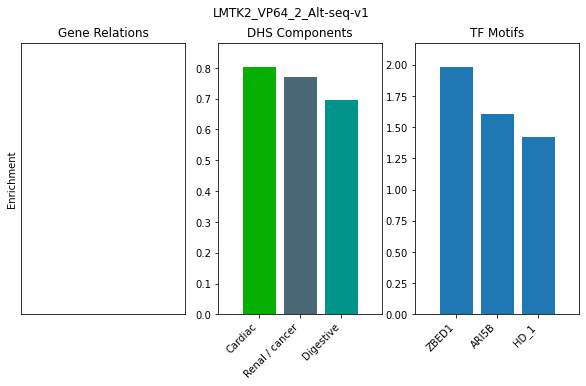

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_LMTK2_VP64_2_Alt-seq-v1


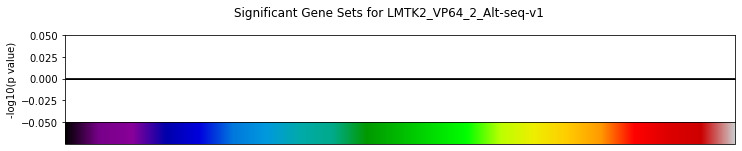

MAPK3_KRAB_2_Alt-seq-v1
original number of genes 2


<Figure size 720x720 with 0 Axes>

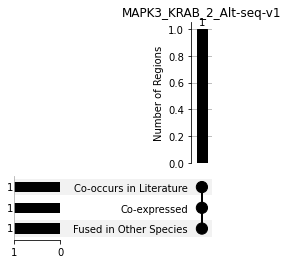

/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)
/tmp/ipykernel_154253/751357204.py:7: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)


inter-string shape (1, 11)
DHS shape (2, 16)
TF shape (2, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


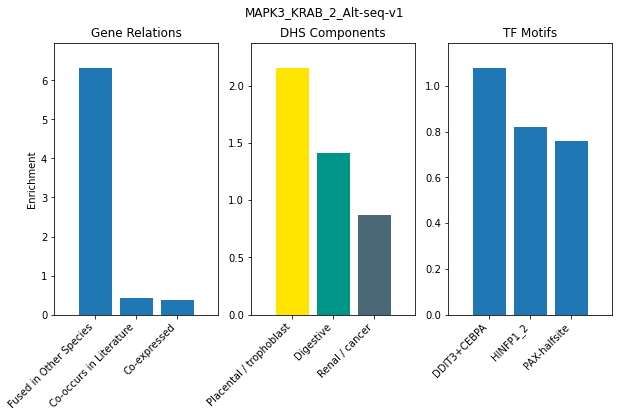

Significant_Gene_Sets_for_MAPK3_KRAB_2_Alt-seq-v1


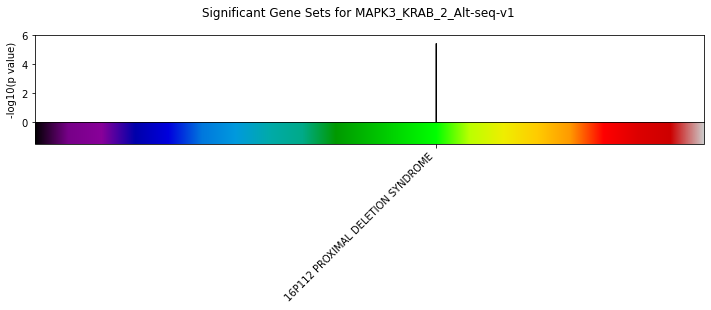

MAPK3_KRAB_2_mRNA
original number of genes 2


<Figure size 720x720 with 0 Axes>

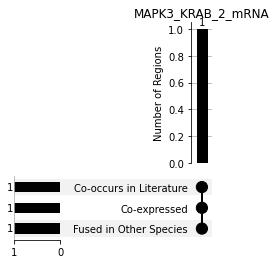

/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)
/tmp/ipykernel_154253/751357204.py:7: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)


inter-string shape (1, 11)
DHS shape (2, 16)
TF shape (2, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


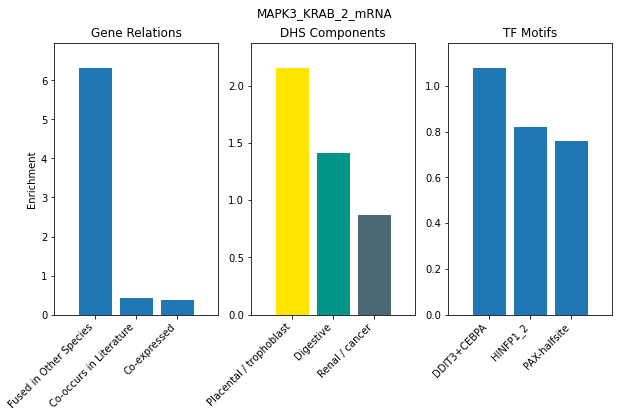

Significant_Gene_Sets_for_MAPK3_KRAB_2_mRNA


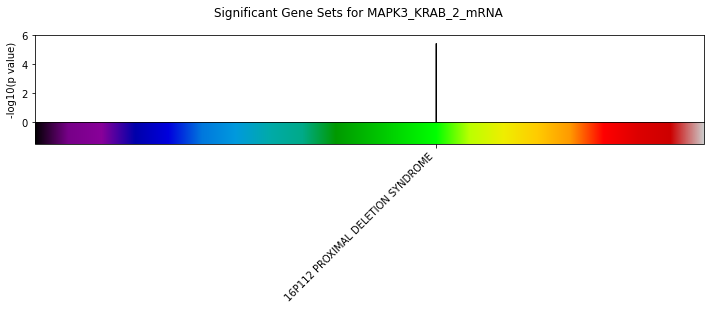

MAPK3_KRAB_5_Alt-seq-v1
original number of genes 2


<Figure size 720x720 with 0 Axes>

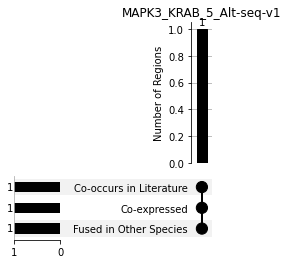

/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)
/tmp/ipykernel_154253/751357204.py:7: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)


inter-string shape (1, 11)
DHS shape (2, 16)
TF shape (2, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


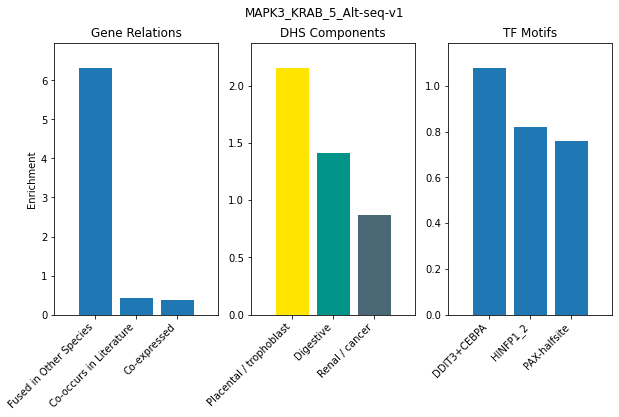

Significant_Gene_Sets_for_MAPK3_KRAB_5_Alt-seq-v1


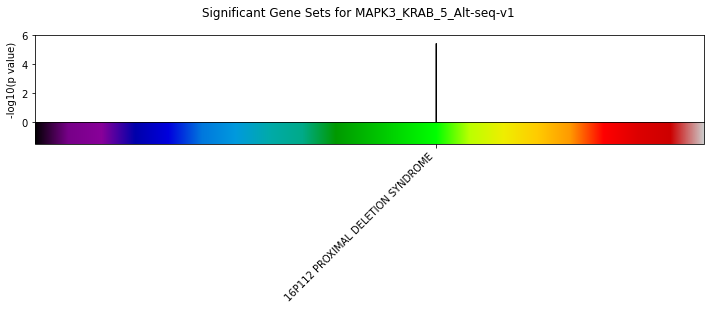

PTPN22_VP64_2_Alt-seq-v1
original number of genes 2
inter-string shape (0, 11)
DHS shape (2, 16)
TF shape (2, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


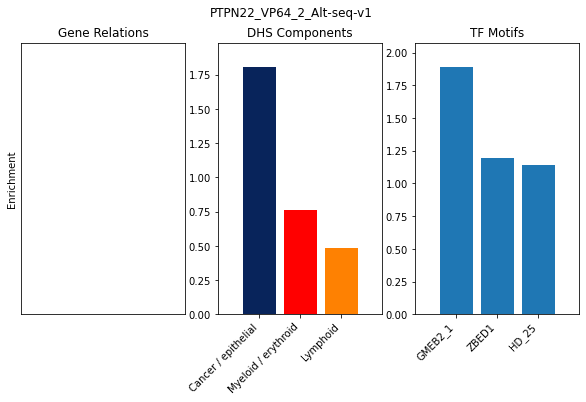

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_PTPN22_VP64_2_Alt-seq-v1


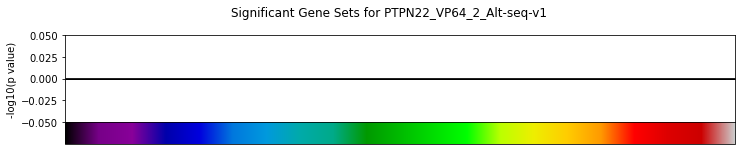

RCL1_VP64_2_Alt-seq-v1
original number of genes 10


<Figure size 720x720 with 0 Axes>

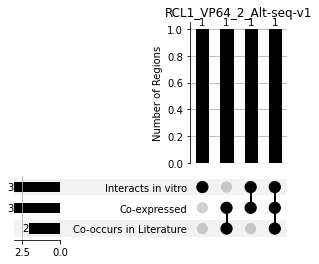

/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)


inter-string shape (4, 11)
DHS shape (9, 16)
TF shape (9, 282)


/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


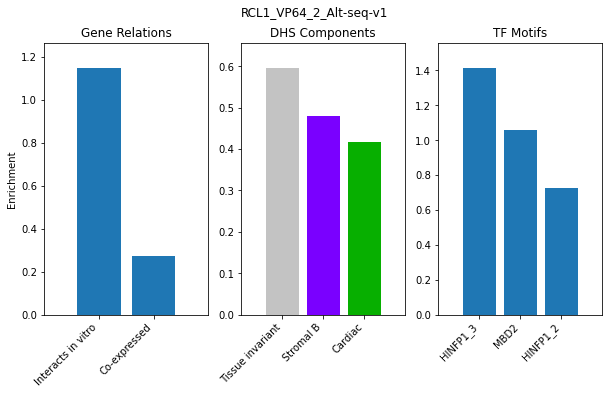

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_RCL1_VP64_2_Alt-seq-v1


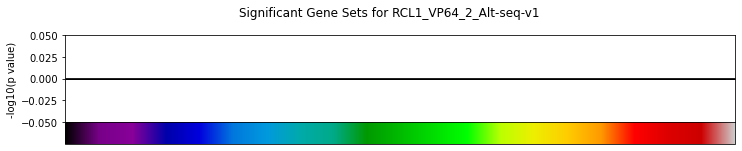

RORC_KRAB_5_Alt-seq-v1
original number of genes 5


/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)


inter-string shape (2, 11)
DHS shape (5, 16)
TF shape (5, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


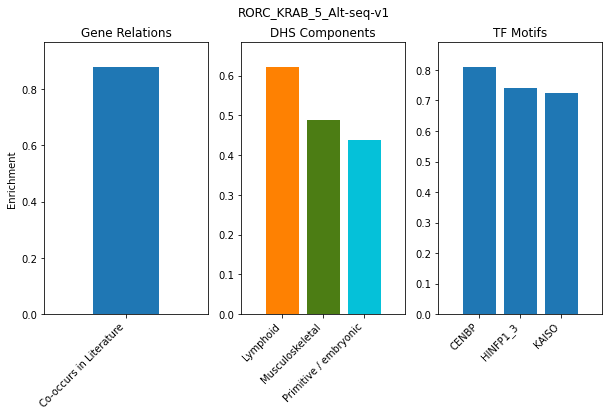

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_RORC_KRAB_5_Alt-seq-v1


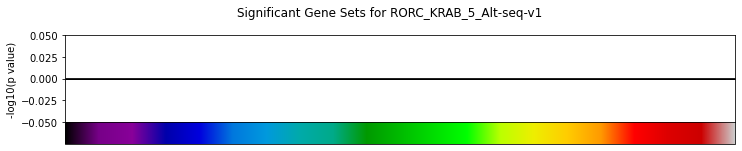

SETDB1_KRAB_2_Alt-seq-v1
original number of genes 2
inter-string shape (0, 11)
DHS shape (1, 16)


/tmp/ipykernel_154253/751357204.py:7: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)


TF shape (1, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


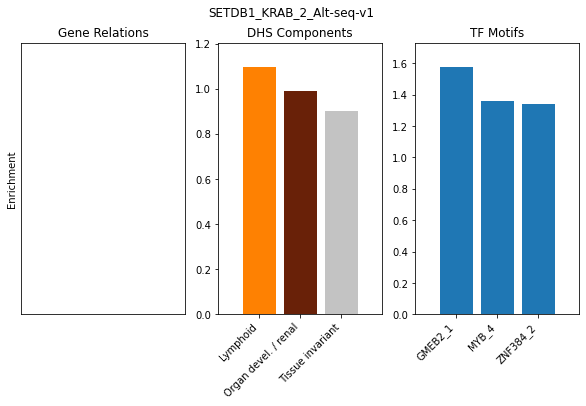

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_SETDB1_KRAB_2_Alt-seq-v1


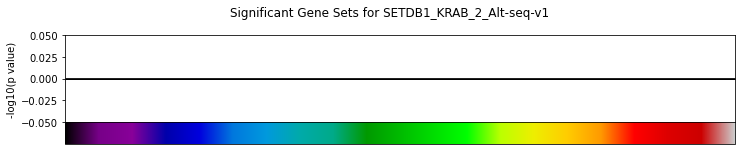

SHOC2_KRAB_2_mRNA
original number of genes 2


/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)


inter-string shape (1, 11)
DHS shape (2, 16)
TF shape (2, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


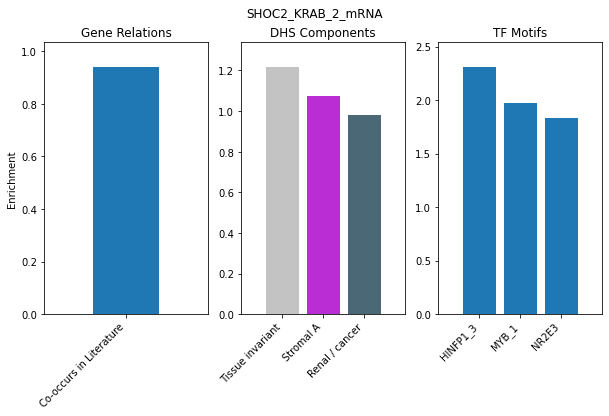

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_SHOC2_KRAB_2_mRNA


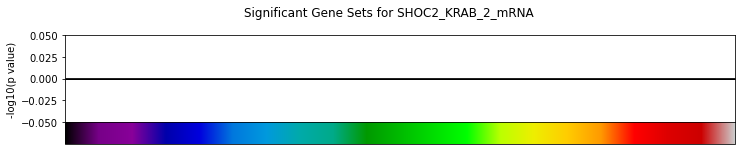

SLC39A14_VP64_2_Alt-seq-v1
original number of genes 2


/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)


inter-string shape (1, 11)
DHS shape (2, 16)
TF shape (2, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score
/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


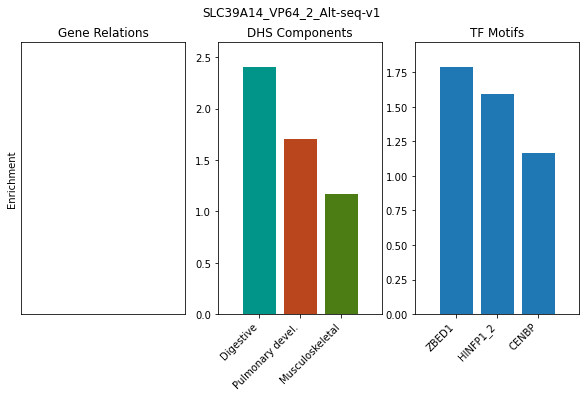

Significant_Gene_Sets_for_SLC39A14_VP64_2_Alt-seq-v1


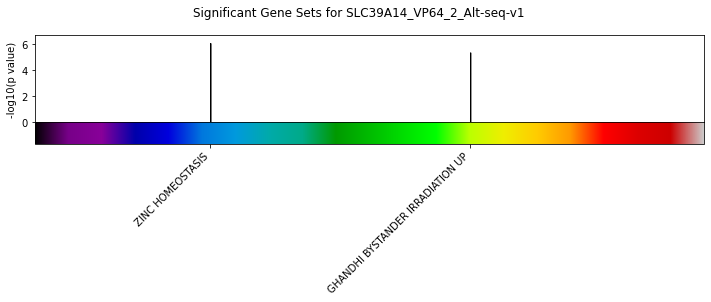

SLC9A9_KRAB_2_Alt-seq-v1
original number of genes 7
inter-string shape (0, 11)
DHS shape (6, 16)
TF shape (7, 282)


/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


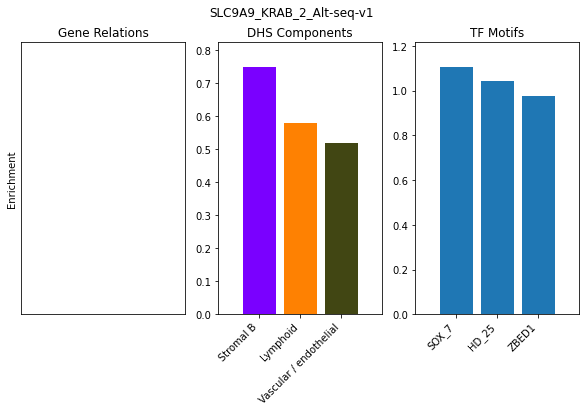

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_SLC9A9_KRAB_2_Alt-seq-v1


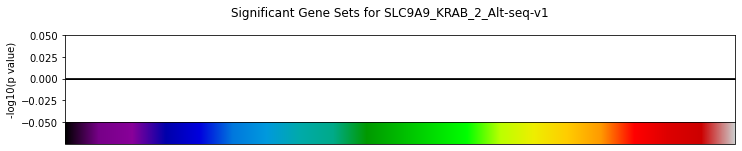

SPINT2_VP64_2_Alt-seq-v1
original number of genes 2


<Figure size 720x720 with 0 Axes>

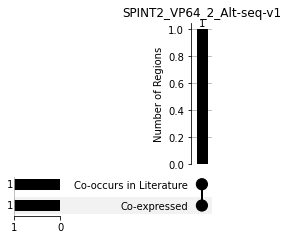

/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)
/tmp/ipykernel_154253/751357204.py:7: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)


inter-string shape (1, 11)
DHS shape (2, 16)
TF shape (1, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


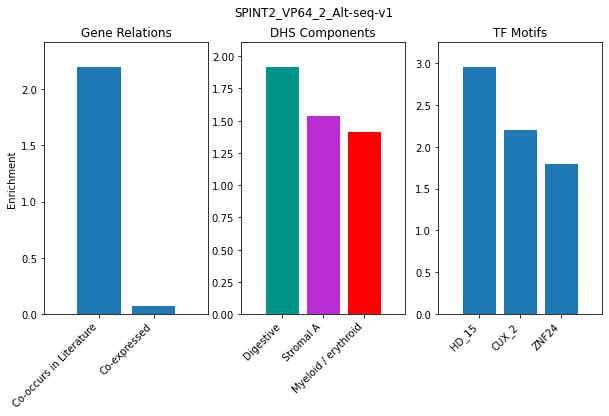

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_SPINT2_VP64_2_Alt-seq-v1


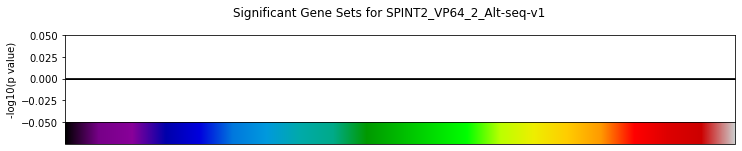

SREBF1_VP64_5_Alt-seq-v1
original number of genes 2
inter-string shape (0, 11)
DHS shape (2, 16)
TF shape (2, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


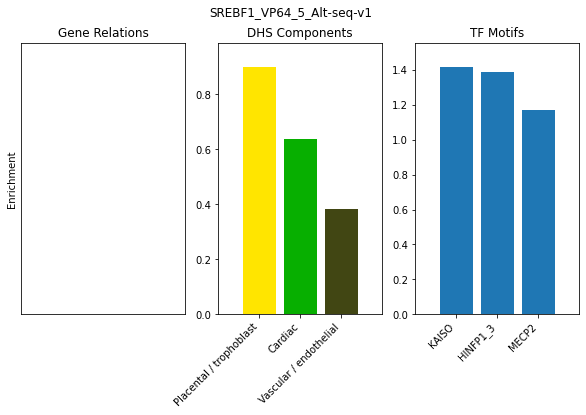

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_SREBF1_VP64_5_Alt-seq-v1


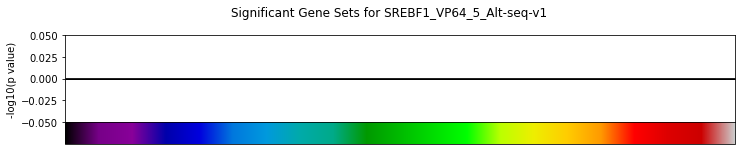

STAT6_KRAB_5_Alt-seq-v1
original number of genes 20


<Figure size 720x720 with 0 Axes>

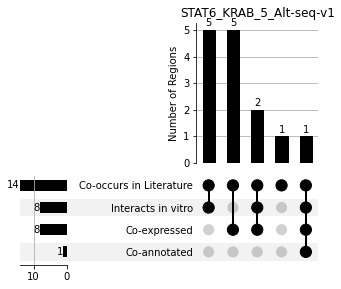

/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)


inter-string shape (14, 11)
DHS shape (19, 16)
TF shape (19, 282)


/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


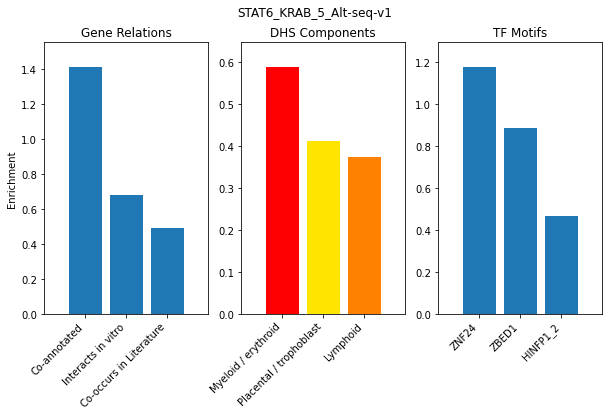

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_STAT6_KRAB_5_Alt-seq-v1


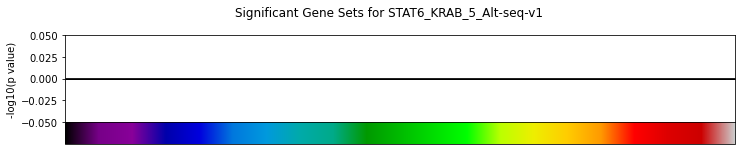

STAT6_KRAB_8_Alt-seq-v1
original number of genes 15


<Figure size 720x720 with 0 Axes>

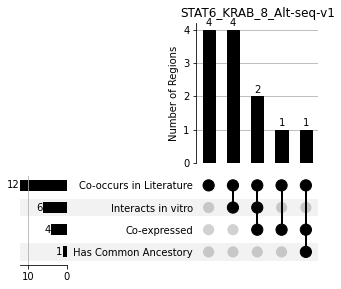

/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)


inter-string shape (12, 11)
DHS shape (14, 16)
TF shape (14, 282)


/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


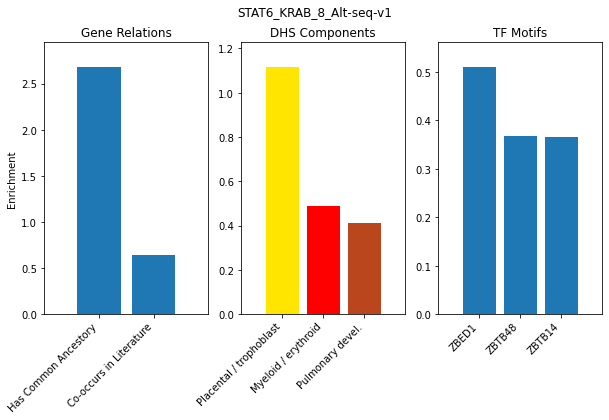

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_STAT6_KRAB_8_Alt-seq-v1


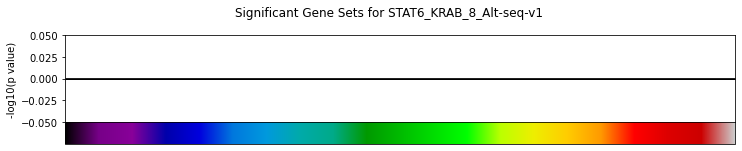

STAT6_VP64_2_Alt-seq-v1
original number of genes 2
inter-string shape (0, 11)
DHS shape (2, 16)


/tmp/ipykernel_154253/751357204.py:7: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)


TF shape (2, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


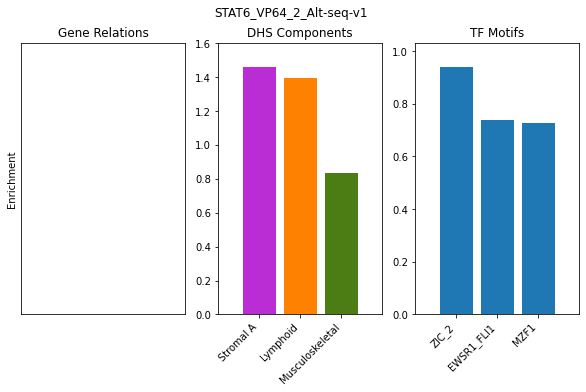

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_STAT6_VP64_2_Alt-seq-v1


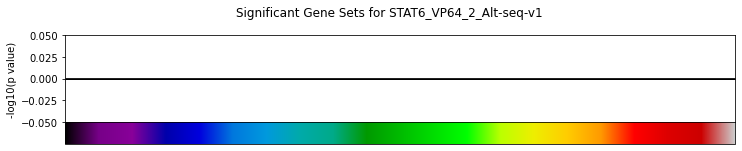

SYVN1_KRAB_5_Alt-seq-v1
original number of genes 7
inter-string shape (0, 11)
DHS shape (6, 16)
TF shape (5, 282)


/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


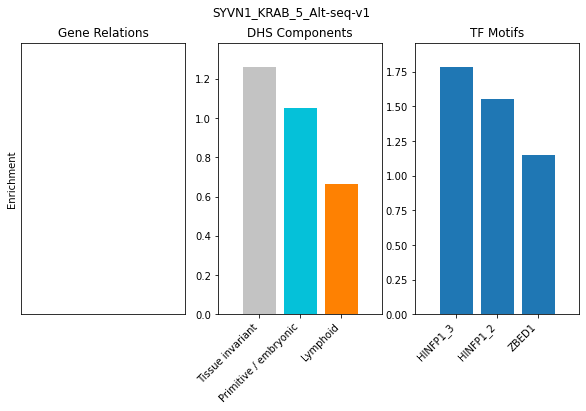

Significant_Gene_Sets_for_SYVN1_KRAB_5_Alt-seq-v1


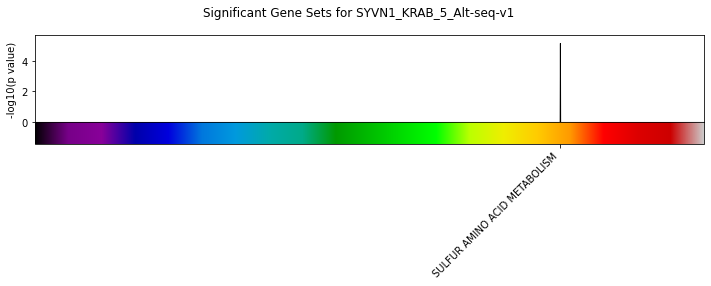

TOP2A_KRAB_2_Alt-seq-v1
original number of genes 22


<Figure size 720x720 with 0 Axes>

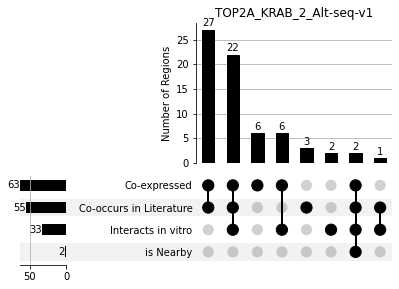

/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)


inter-string shape (69, 11)
DHS shape (21, 16)
TF shape (19, 282)


/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


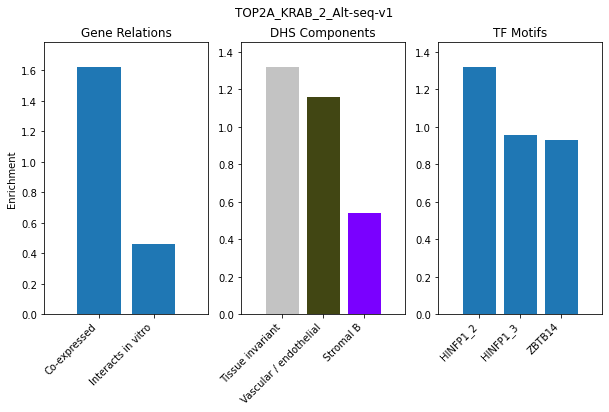

Significant_Gene_Sets_for_TOP2A_KRAB_2_Alt-seq-v1


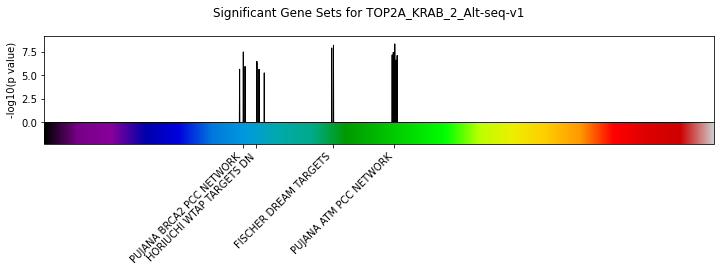

TP53_KRAB_2_mRNA
original number of genes 9


<Figure size 720x720 with 0 Axes>

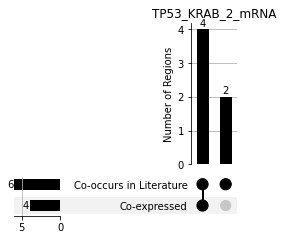

/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)


inter-string shape (6, 11)
DHS shape (7, 16)
TF shape (9, 282)


/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


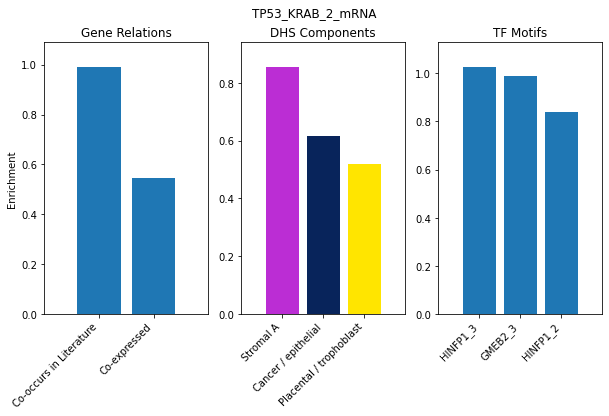

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_TP53_KRAB_2_mRNA


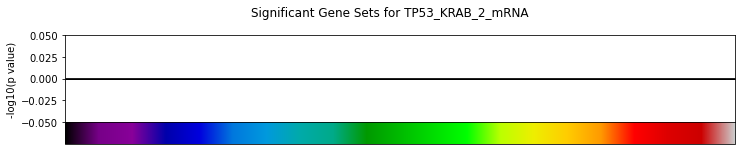

TXNIP_KRAB_2_mRNA
original number of genes 2


<Figure size 720x720 with 0 Axes>

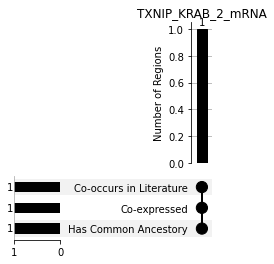

/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)
/tmp/ipykernel_154253/751357204.py:7: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)


inter-string shape (1, 11)
DHS shape (2, 16)
TF shape (2, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


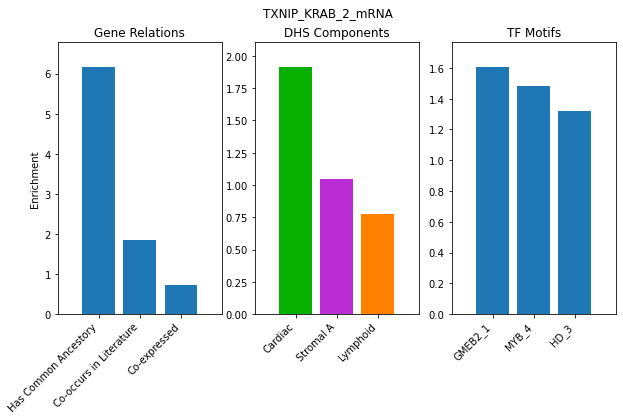

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_TXNIP_KRAB_2_mRNA


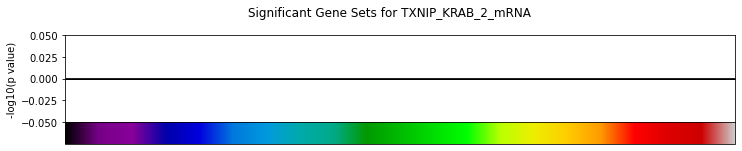

TXNIP_KRAB_5_Alt-seq-v1
original number of genes 3


<Figure size 720x720 with 0 Axes>

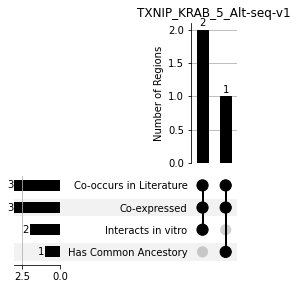

/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)
/tmp/ipykernel_154253/751357204.py:7: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)


inter-string shape (3, 11)
DHS shape (3, 16)
TF shape (3, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


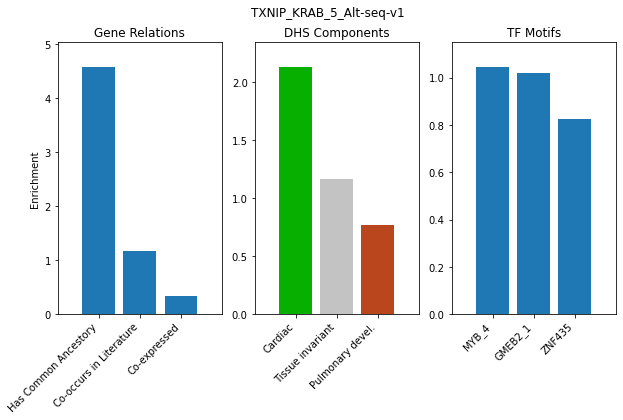

Significant_Gene_Sets_for_TXNIP_KRAB_5_Alt-seq-v1


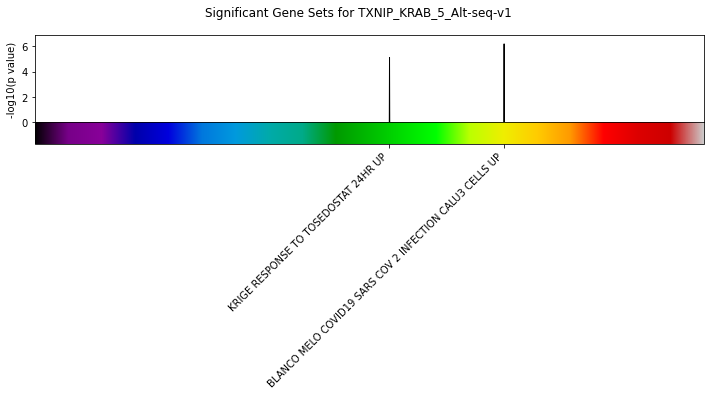

TXNIP_KRAB_5_Alt-seq-v2
original number of genes 3


<Figure size 720x720 with 0 Axes>

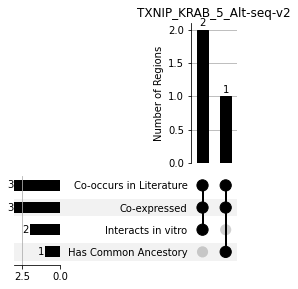

/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)
/tmp/ipykernel_154253/751357204.py:7: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)


inter-string shape (3, 11)
DHS shape (3, 16)
TF shape (3, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


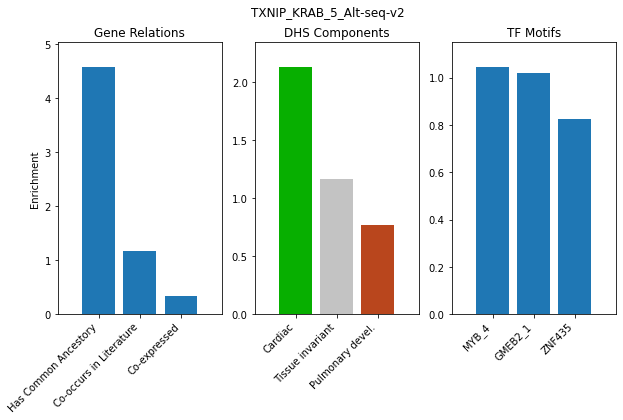

Significant_Gene_Sets_for_TXNIP_KRAB_5_Alt-seq-v2


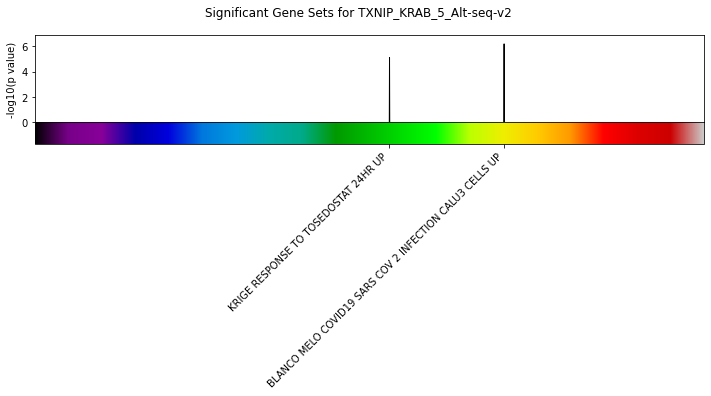

TXNIP_KRAB_5_mRNA
original number of genes 3


<Figure size 720x720 with 0 Axes>

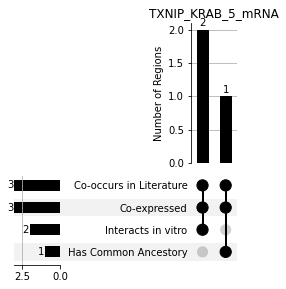

/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)
/tmp/ipykernel_154253/751357204.py:7: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)


inter-string shape (3, 11)
DHS shape (3, 16)
TF shape (3, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


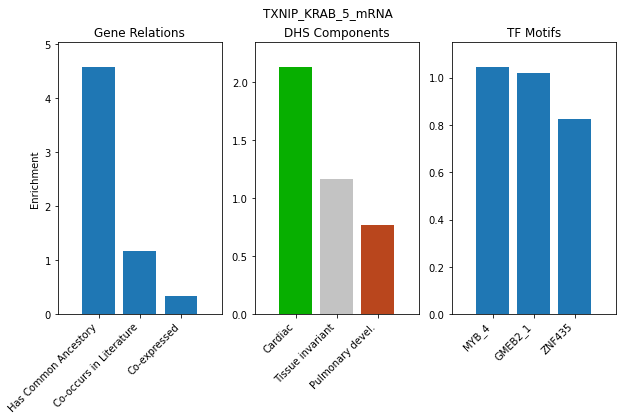

Significant_Gene_Sets_for_TXNIP_KRAB_5_mRNA


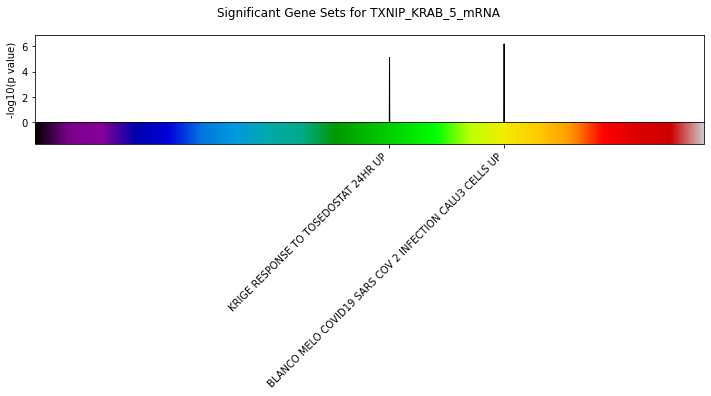

UAP1_KRAB_2_mRNA
original number of genes 2


<Figure size 720x720 with 0 Axes>

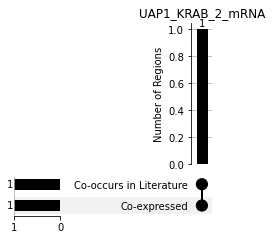

/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)


inter-string shape (1, 11)
DHS shape (2, 16)
TF shape (2, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


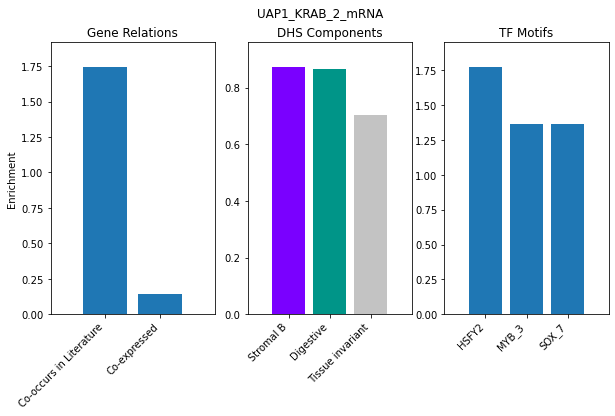

Significant_Gene_Sets_for_UAP1_KRAB_2_mRNA


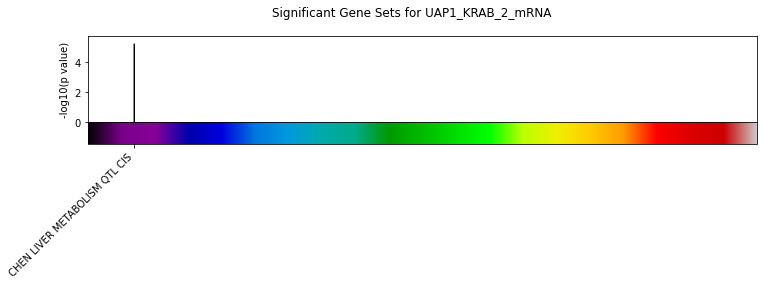

UBE2E2_KRAB_2_mRNA
original number of genes 2
inter-string shape (0, 11)
DHS shape (2, 16)
TF shape (2, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


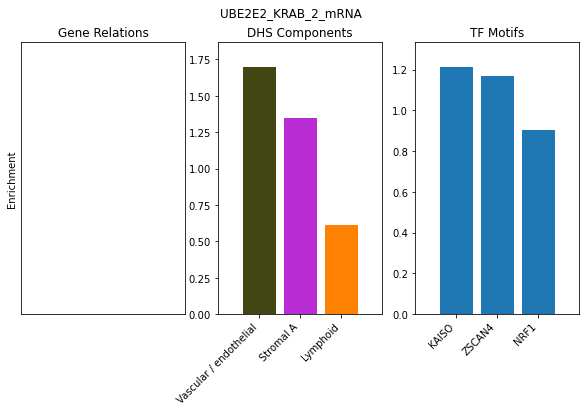

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_UBE2E2_KRAB_2_mRNA


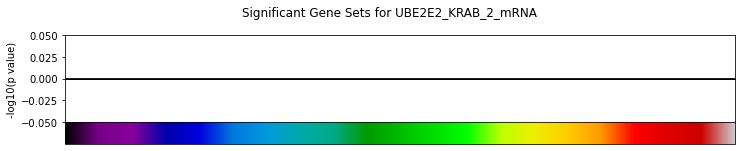

UBE2T_KRAB_2_mRNA
original number of genes 8


<Figure size 720x720 with 0 Axes>

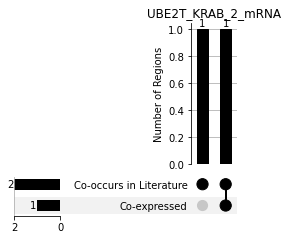

/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)


inter-string shape (2, 11)
DHS shape (7, 16)
TF shape (7, 282)


/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


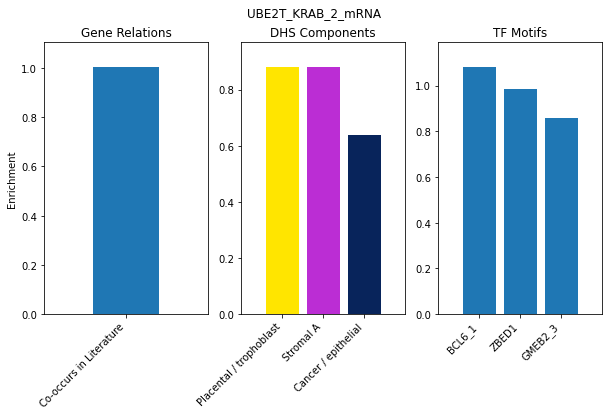

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_UBE2T_KRAB_2_mRNA


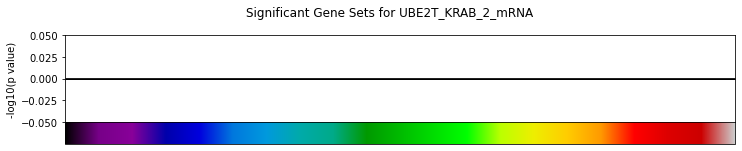

UBE2T_KRAB_5_Alt-seq-cycler
original number of genes 4


/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)


inter-string shape (1, 11)
DHS shape (4, 16)
TF shape (4, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score
/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


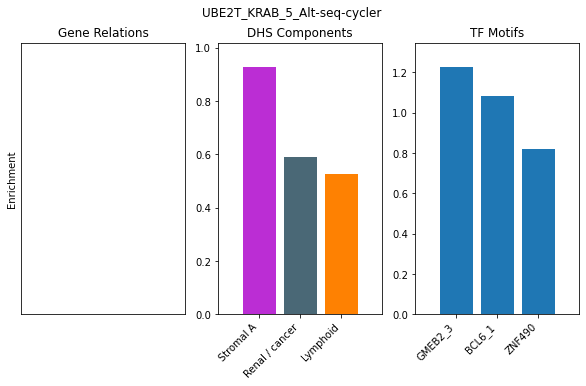

Significant_Gene_Sets_for_UBE2T_KRAB_5_Alt-seq-cycler


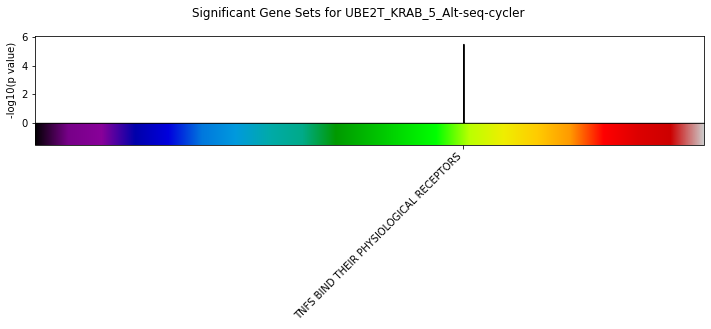

UBE2T_KRAB_5_Alt-seq-v1
original number of genes 12


<Figure size 720x720 with 0 Axes>

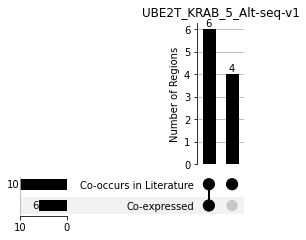

/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)


inter-string shape (10, 11)
DHS shape (11, 16)
TF shape (12, 282)


/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


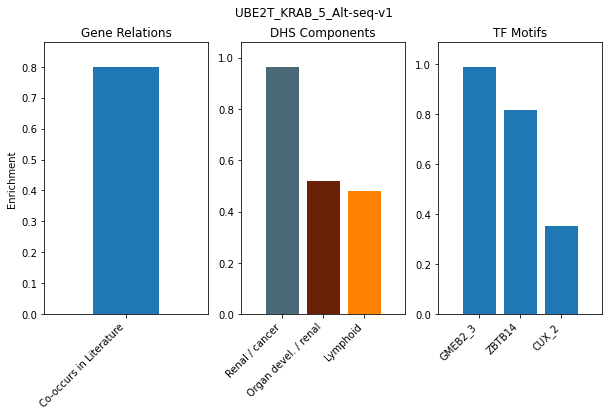

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_UBE2T_KRAB_5_Alt-seq-v1


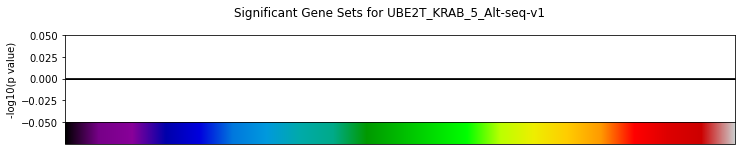

UHMK1_KRAB_2_Alt-seq-v1
original number of genes 9


<Figure size 720x720 with 0 Axes>

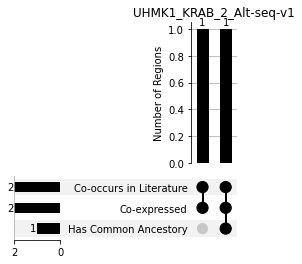

/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)


inter-string shape (2, 11)
DHS shape (7, 16)
TF shape (8, 282)


/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


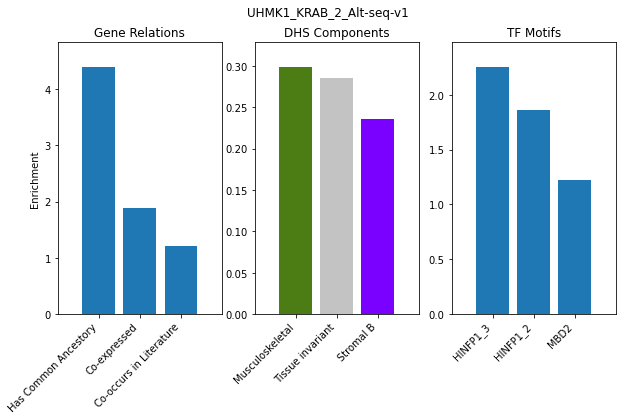

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_UHMK1_KRAB_2_Alt-seq-v1


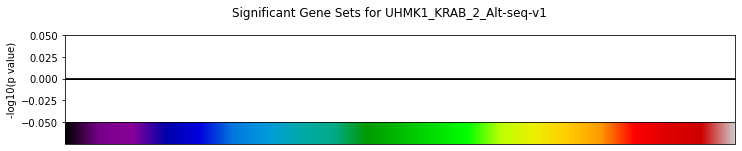

UHMK1_KRAB_5_Alt-seq-v1
original number of genes 6
inter-string shape (0, 11)
DHS shape (5, 16)
TF shape (6, 282)


/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


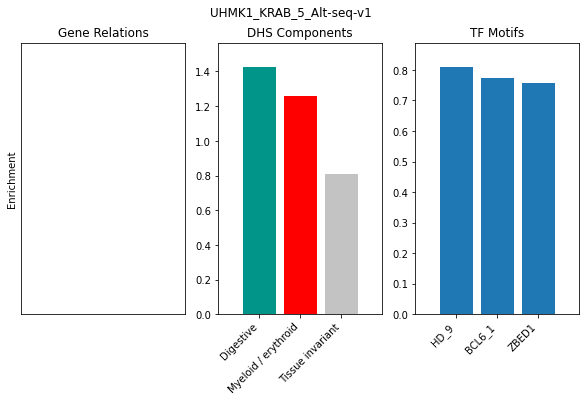

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_UHMK1_KRAB_5_Alt-seq-v1


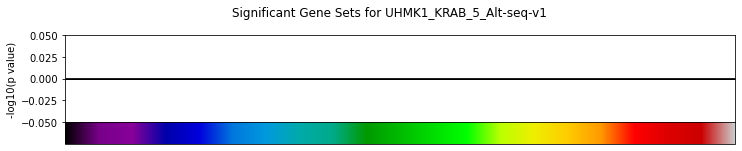

UHMK1_VP64_2_Alt-seq-v1
original number of genes 2
inter-string shape (0, 11)
DHS shape (2, 16)
TF shape (2, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


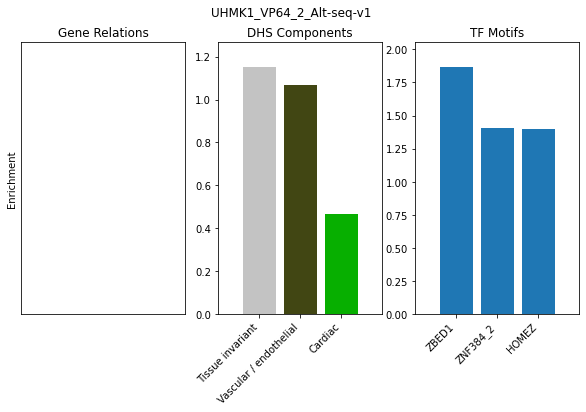

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_UHMK1_VP64_2_Alt-seq-v1


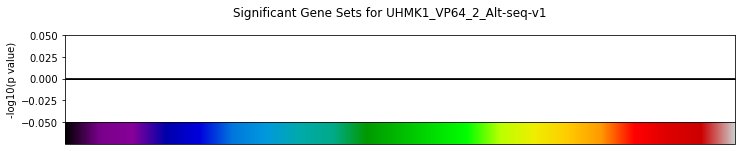

WEE1_KRAB_2_mRNA
original number of genes 76


<Figure size 720x720 with 0 Axes>

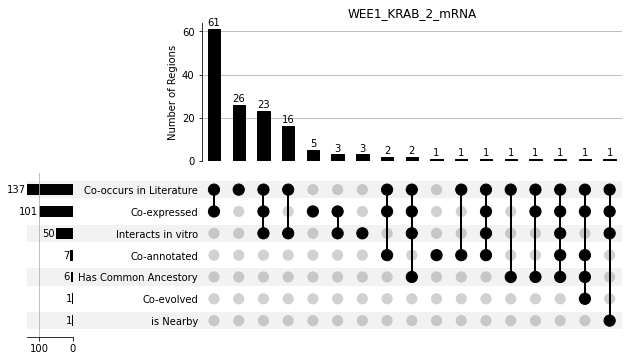

/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)


inter-string shape (149, 11)
DHS shape (65, 16)
TF shape (65, 282)


/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


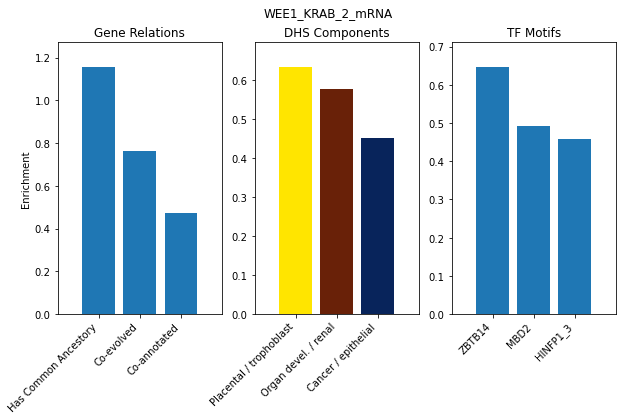

Significant_Gene_Sets_for_WEE1_KRAB_2_mRNA


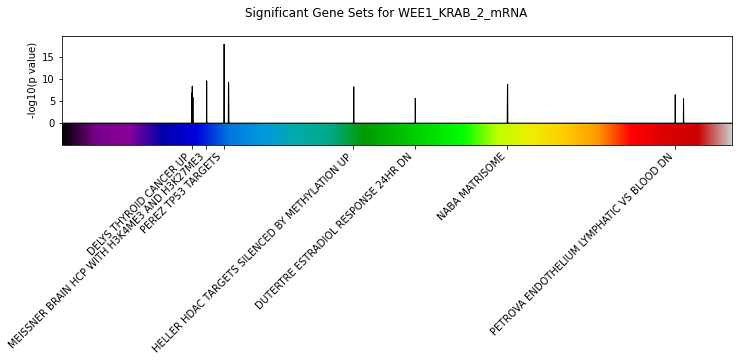

WEE1_KRAB_2_totalRNA
original number of genes 13


<Figure size 720x720 with 0 Axes>

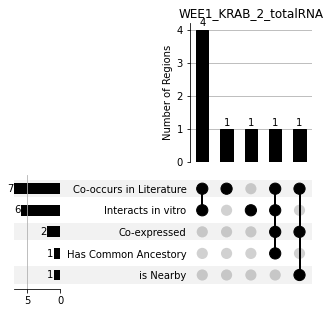

/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)


inter-string shape (8, 11)
DHS shape (12, 16)
TF shape (10, 282)


/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


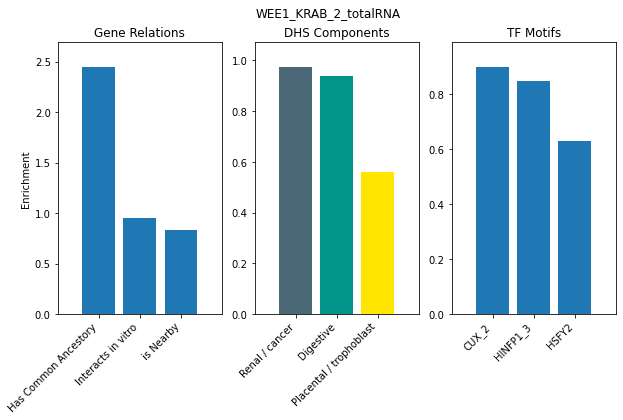

Significant_Gene_Sets_for_WEE1_KRAB_2_totalRNA


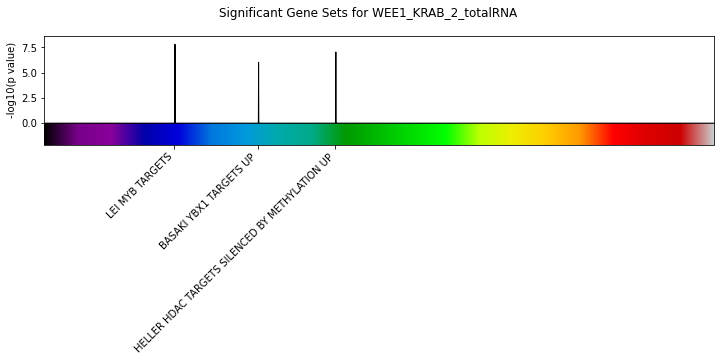

ZBTB39_VP64_2_Alt-seq-v1
original number of genes 2
inter-string shape (0, 11)
DHS shape (2, 16)


/tmp/ipykernel_154253/751357204.py:7: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)


TF shape (2, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


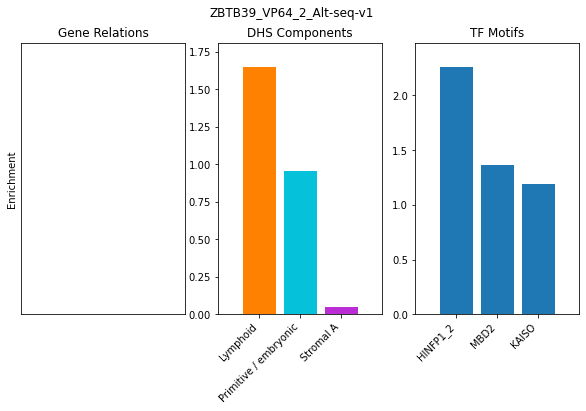

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_ZBTB39_VP64_2_Alt-seq-v1


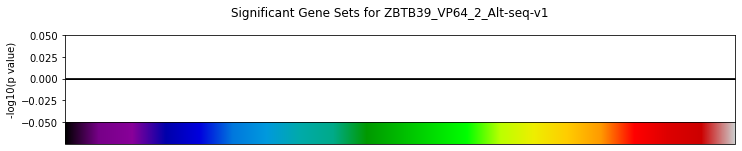

ZMPSTE24_KRAB_2_mRNA
original number of genes 2
inter-string shape (0, 11)
DHS shape (1, 16)


/tmp/ipykernel_154253/751357204.py:7: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)


TF shape (1, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


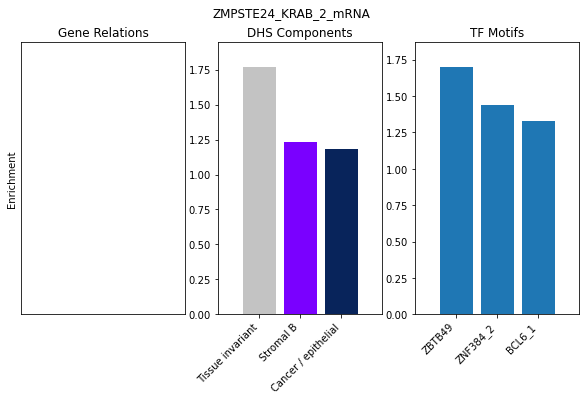

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_ZMPSTE24_KRAB_2_mRNA


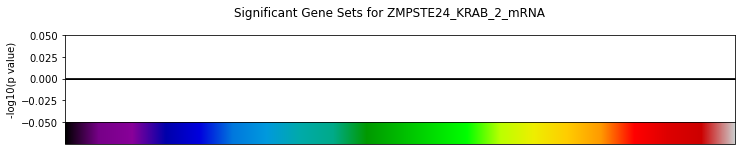

ZMPSTE24_KRAB_5_Alt-seq-v1
original number of genes 2
inter-string shape (0, 11)
DHS shape (1, 16)


/tmp/ipykernel_154253/751357204.py:7: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)


TF shape (1, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


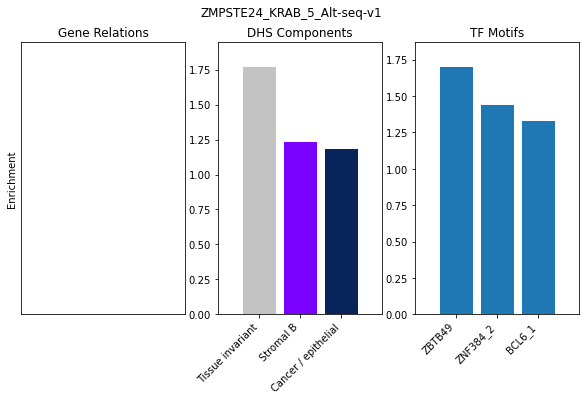

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_ZMPSTE24_KRAB_5_Alt-seq-v1


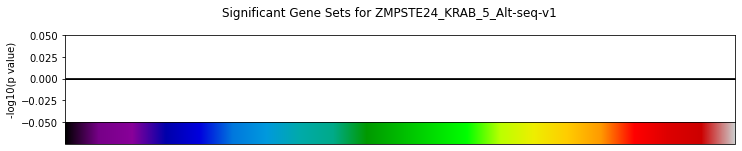

ZNF160_KRAB_8_Alt-seq-v1
original number of genes 51


<Figure size 720x720 with 0 Axes>

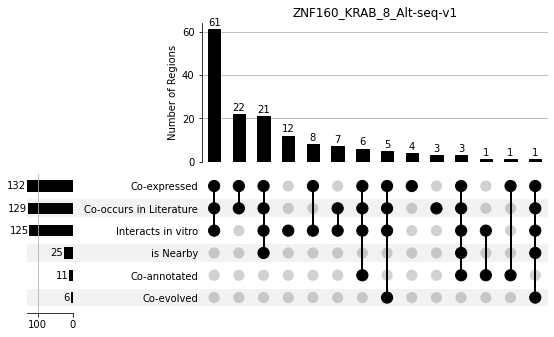

/tmp/ipykernel_154253/1437453650.py:93: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)


inter-string shape (155, 11)
DHS shape (44, 16)
TF shape (42, 282)


/tmp/ipykernel_154253/751357204.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


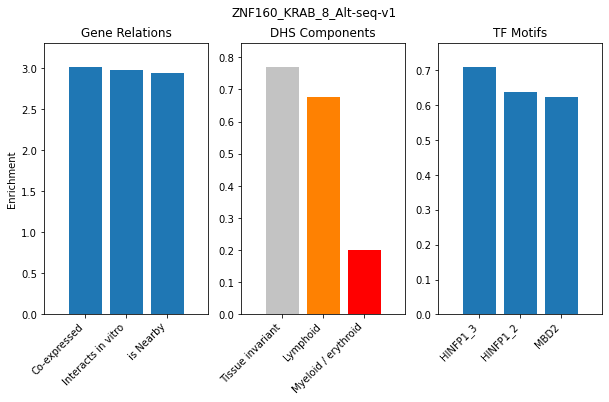

Significant_Gene_Sets_for_ZNF160_KRAB_8_Alt-seq-v1


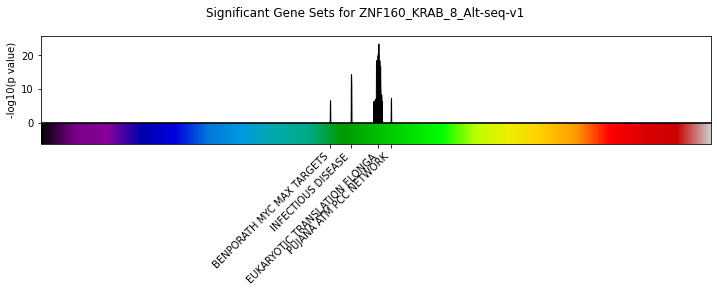

ZNF574_KRAB_2_Alt-seq-v1
original number of genes 2
inter-string shape (0, 11)
DHS shape (1, 16)


/tmp/ipykernel_154253/751357204.py:7: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)


TF shape (2, 282)


/tmp/ipykernel_154253/751357204.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_154253/751357204.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


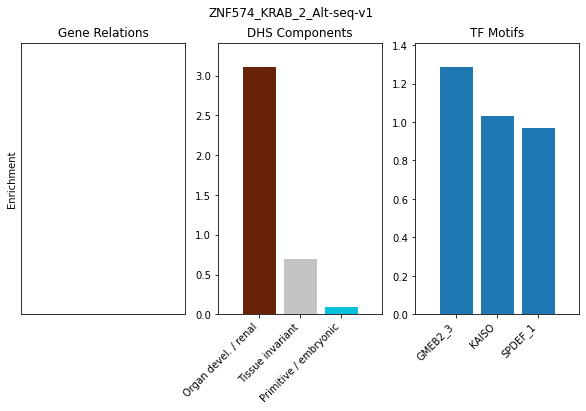

/tmp/ipykernel_154253/2693152678.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_ZNF574_KRAB_2_Alt-seq-v1


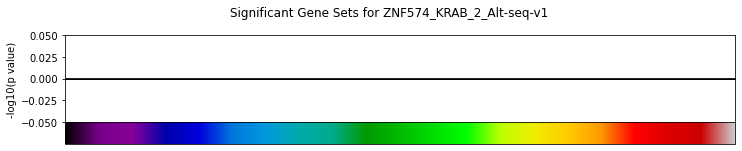

In [28]:
enrichments_dir = '/home/ctrader/region_similarity/data/gene_DHS_TF_enrichments/independent_filtering/WM20220727_extract_MegaMap_target_genes_for_Cameron/enrichments/'
upset_dir = '/home/ctrader/region_similarity/data/gene_DHS_TF_enrichments/independent_filtering/WM20220727_extract_MegaMap_target_genes_for_Cameron/upset/'
spectrum_dir = '/home/ctrader/region_similarity/data/gene_DHS_TF_enrichments/independent_filtering/WM20220727_extract_MegaMap_target_genes_for_Cameron/spectrum/'
sig_gene_sets_dir = '/home/ctrader/region_similarity/data/gene_DHS_TF_enrichments/independent_filtering/WM20220727_extract_MegaMap_target_genes_for_Cameron/significant_gene_sets/'

#spectrum plots
for row in exper_plus_genes:
    experiment = row[0]
    print(experiment)
    genes = np.array(row[1:])
    significant_gene_sets, pvals, set_string_mean = set_of_genes_analysis(genes, experiment, enrichments_dir, upset_dir, spectrum_dir)
    f = open(sig_gene_sets_dir + 'significant_gene_sets.'+experiment+'_CT' + today.strftime("%Y%m%d") + '.txt', 'w')
    for gene_set, pval in zip(significant_gene_sets, pvals):
        f.write(gene_set + '\t' + str(pval) + '\n')
    f.close()
#     print(significant_gene_sets)

**Ranking experiments by their average score**

In [454]:
###use feather file (but just rerun the ones I've already done)
full_megamap_results_df = pd.read_feather('/net/seq/data2/projects/megamap/rnaseq_analysis_v3/metric_thresh_cossim/deseq_stat/effect_thresh_2.0/min_num_effect_3/significant_downstreams_07.feather')

In [40]:
full_megamap_results_df.shape

(6180, 36595)

In [31]:
np.unique((full_megamap_results_df['kit_name_short']), return_counts=True)

(array(['Alt-Seq', 'Prime-Seq', 'mRNA', 'totalRNA'], dtype=object),
 array([5946,   74,  142,   18]))

In [448]:
corrs = pd.read_feather('/net/seq/data2/projects/megamap/rnaseq_analysis_v3/metric_thresh_cossim/deseq_stat/effect_thresh_2.0/min_num_effect_3/corrs.feather')

In [458]:
efficacy_07 = pd.read_feather('/net/seq/data2/projects/megamap/rnaseq_analysis_v3/metric_thresh_cossim/deseq_stat/effect_thresh_2.0/min_num_effect_3/efficacy_07.feather')

In [459]:
efficacy_07

,target,effector_purpose_short,kit_name_short,day,target_min_num_eff,target_min_num_eff_thresh,target_max_eff,target_max_eff_2,target_max_eff_3,max_ds_eff,max_lfc,max_target_lfc,ds_corr,num_ds_corr,mean_top10_corrs,n_sig,ds_corrs_above_R,num_ds_corrs_above_R
0,AAAS,KRAB,Alt-Seq,2.0,True,True,4.033346,3.371641,2.902011,14.652143,NaN,0.536450,True,71,0.668309,3,True,3
1,AAAS,KRAB,Alt-Seq,5.0,True,False,1.421952,1.412552,1.150223,10.192857,NaN,0.108966,True,115,0.593195,1,True,1
2,AAAS,VP64,Alt-Seq,2.0,True,False,5.002744,1.513350,0.844362,6.954376,NaN,0.395751,True,34,0.581265,1,True,1
3,AAAS,VP64,Alt-Seq,5.0,True,False,5.855991,1.801099,1.575028,11.262383,NaN,0.534840,True,442,0.890370,112,True,112
4,AASS,KRAB,Prime-Seq,2.0,True,True,2.704921,2.450078,2.418366,13.297482,NaN,3.199699,True,104,0.721734,7,True,7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6175,ZYG11B,VP64,Alt-Seq,5.0,True,False,2.898586,1.964854,1.904975,11.368156,NaN,0.414228,True,122,0.845465,25,True,25
6176,ZZZ3,KRAB,Alt-Seq,2.0,False,False,0.000000,0.000000,0.000000,11.147532,NaN,0.000000,False,0,0.000000,0,False,0
6177,ZZZ3,KRAB,Alt-Seq,5.0,False,False,0.000000,0.000000,0.000000,34.317596,NaN,0.000000,False,0,0.000000,0,False,0
6178,ZZZ3,VP64,Alt-Seq,2.0,False,False,0.000000,0.000000,0.000000,14.336177,NaN,0.000000,False,0,0.000000,0,False,0


In [460]:
megmap_genes = full_megamap_results_df.columns[4:]

CLCN6_VP64_2_Alt-Seq
original number of genes 8


<Figure size 720x720 with 0 Axes>

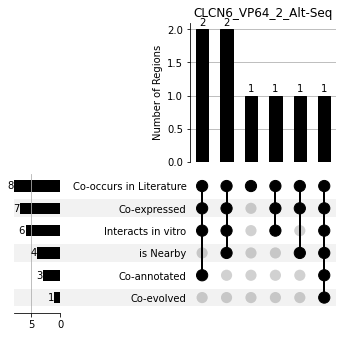

/tmp/ipykernel_188824/1337154778.py:105: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)


inter-string shape (8, 11)
DHS shape (8, 16)
TF shape (8, 282)


/tmp/ipykernel_188824/3629294891.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


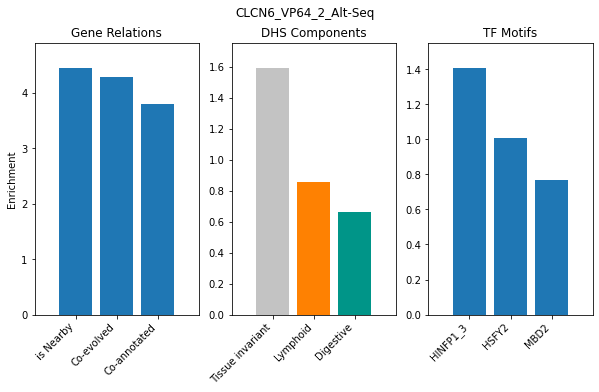

Significant_Gene_Sets_for_CLCN6_VP64_2_Alt-Seq


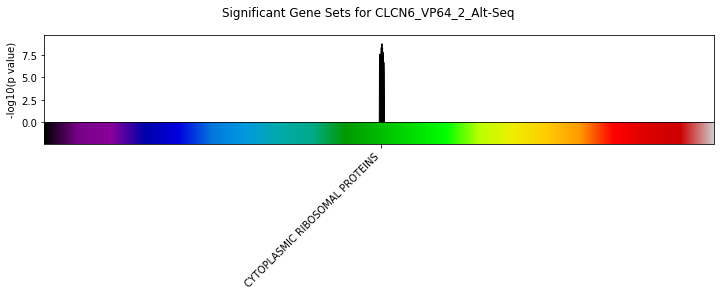

SIK2_KRAB_2_Alt-Seq
original number of genes 4


<Figure size 720x720 with 0 Axes>

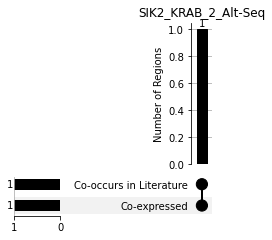

/tmp/ipykernel_188824/1337154778.py:105: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)


inter-string shape (1, 11)
DHS shape (4, 16)
TF shape (4, 282)


/tmp/ipykernel_188824/3629294891.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_188824/3629294891.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


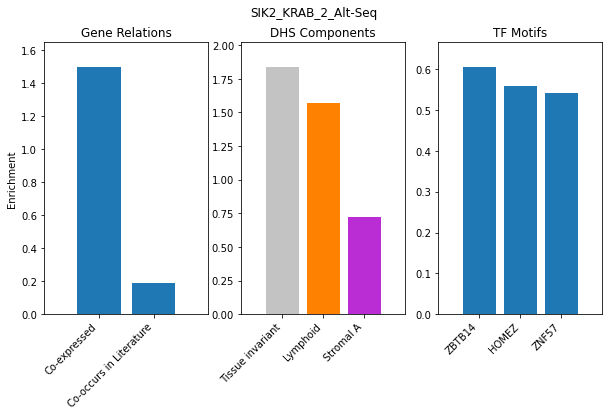

Significant_Gene_Sets_for_SIK2_KRAB_2_Alt-Seq


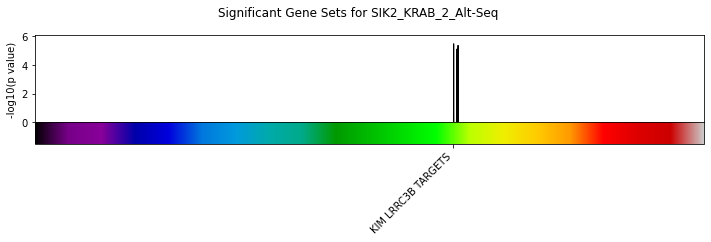

WAS_KRAB_2_Alt-Seq
original number of genes 3


<Figure size 720x720 with 0 Axes>

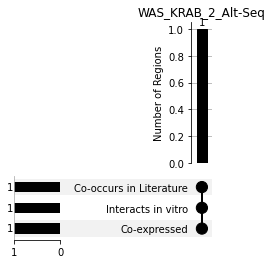

/tmp/ipykernel_188824/1337154778.py:105: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)
/tmp/ipykernel_188824/3629294891.py:7: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)


inter-string shape (1, 11)
DHS shape (3, 16)
TF shape (3, 282)


/tmp/ipykernel_188824/3629294891.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


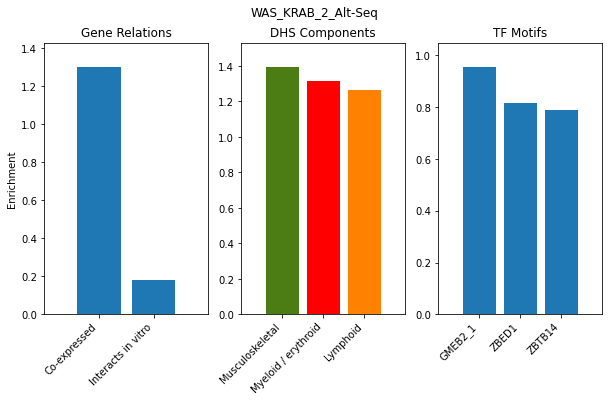

SRSF6_KRAB_5_Alt-Seq
original number of genes 2
inter-string shape (0, 11)
DHS shape (2, 16)


/tmp/ipykernel_188824/3629294891.py:7: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)


TF shape (2, 282)


/tmp/ipykernel_188824/3629294891.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


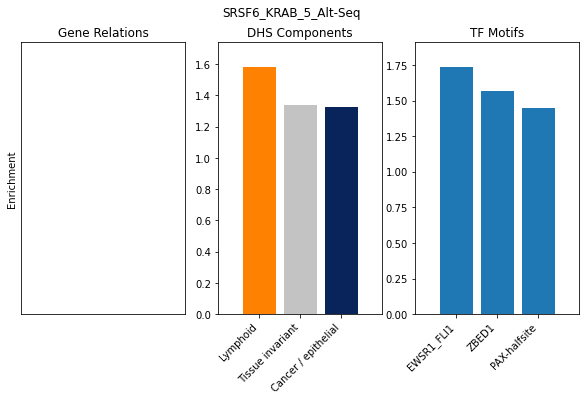

GLTSCR2_VP64_2_Alt-Seq
original number of genes 1
DHS shape (1, 16)


/tmp/ipykernel_188824/3629294891.py:7: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)


TF shape (0, 282)


/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/numpy/core/fromnumeric.py:3440: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/numpy/core/_methods.py:181: RuntimeWarning: invalid value encountered in true_divide
  ret = um.true_divide(
/tmp/ipykernel_188824/3629294891.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])
/tmp/ipykernel_188824/3629294891.py:85: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[2].set_ylim([0, max_val_TF*1.1])


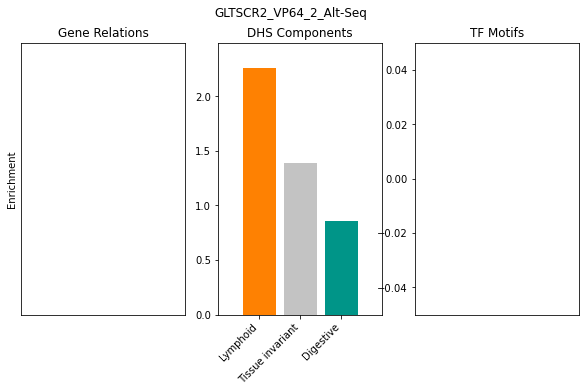

COX5A_KRAB_5_Alt-Seq
original number of genes 8


<Figure size 720x720 with 0 Axes>

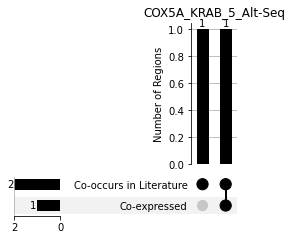

/tmp/ipykernel_188824/1337154778.py:105: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)


inter-string shape (2, 11)
DHS shape (6, 16)
TF shape (7, 282)


/tmp/ipykernel_188824/3629294891.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


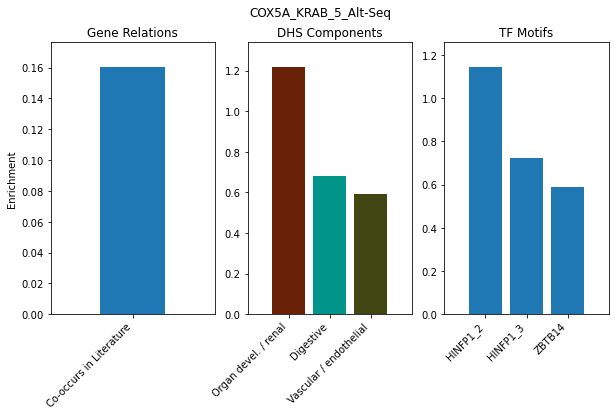

/tmp/ipykernel_188824/3101023632.py:60: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, np.max(spectrum_pvals)*1.1])


Significant_Gene_Sets_for_COX5A_KRAB_5_Alt-Seq


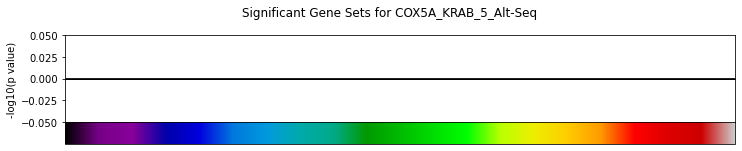

GDF11_VP64_5_Alt-Seq
original number of genes 3
inter-string shape (0, 11)
DHS shape (3, 16)
TF shape (2, 282)


/tmp/ipykernel_188824/3629294891.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_188824/3629294891.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


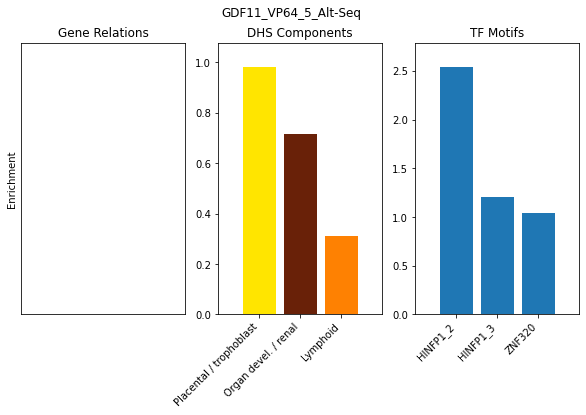

SEL1L_VP64_2_Alt-Seq
original number of genes 1
inter-string shape (0, 11)
DHS shape (1, 16)


/tmp/ipykernel_188824/3629294891.py:7: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)


TF shape (1, 282)


/tmp/ipykernel_188824/3629294891.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_188824/3629294891.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


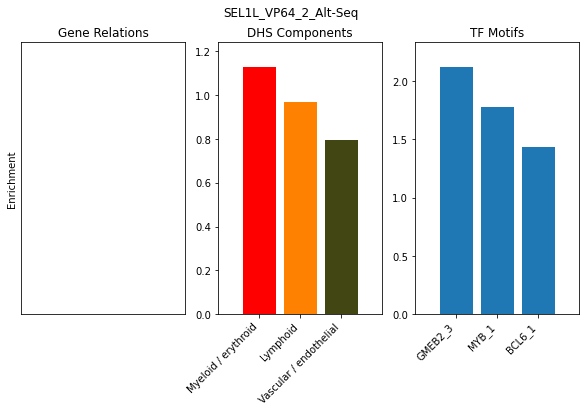

CTLA4_KRAB_2_Alt-Seq
original number of genes 1
DHS shape (1, 16)


/tmp/ipykernel_188824/3629294891.py:7: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)


TF shape (1, 282)


/tmp/ipykernel_188824/3629294891.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_188824/3629294891.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


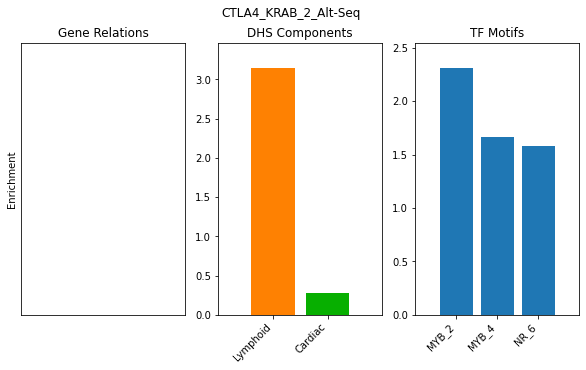

USP5_VP64_8_Alt-Seq
original number of genes 1
inter-string shape (0, 11)
DHS shape (1, 16)


/tmp/ipykernel_188824/3629294891.py:7: RuntimeWarning: divide by zero encountered in log2
  gene_DHS_ooe_mean_log2 = np.log2(gene_DHS_ooe_mean)


TF shape (1, 282)


/tmp/ipykernel_188824/3629294891.py:16: RuntimeWarning: divide by zero encountered in log2
  TF_ooe_mean_log2 = np.log2(TF_ooe_mean)
/tmp/ipykernel_188824/3629294891.py:70: UserWarning: Attempting to set identical bottom == top == 0 results in singular transformations; automatically expanding.
  axes[0].set_ylim([0, max_val_str*1.1])


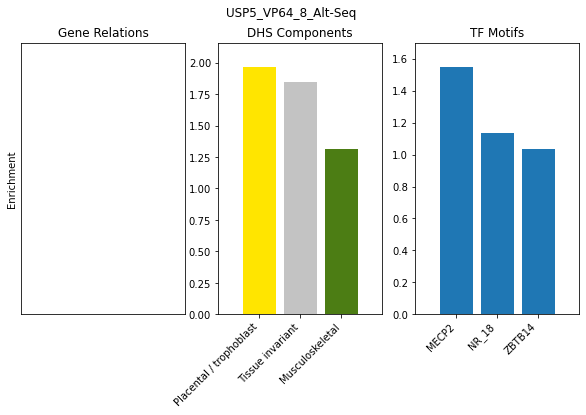

In [461]:
#new way

#ranked by mean_top10_corrs mean_top10_corrs_sorted
enrichments_dir = '/home/ctrader/region_similarity/data/gene_DHS_TF_enrichments/independent_filtering/mean_top10_corrs_sorted/enrichments/'
upset_dir = '/home/ctrader/region_similarity/data/gene_DHS_TF_enrichments/independent_filtering/mean_top10_corrs_sorted/upset/'
spectrum_dir = '/home/ctrader/region_similarity/data/gene_DHS_TF_enrichments/independent_filtering/mean_top10_corrs_sorted/spectrum/'
sig_gene_sets_dir = '/home/ctrader/region_similarity/data/gene_DHS_TF_enrichments/independent_filtering/mean_top10_corrs_sorted/significant_gene_sets/'

for i in np.argsort(-efficacy_07['mean_top10_corrs'])[:10]:
    results_mask = full_megamap_results_df.loc[i][4:]
    affected_genes = np.array(megmap_genes[results_mask])
    #experiment data
    target = full_megamap_results_df.loc[i]['target']
    effector = full_megamap_results_df.loc[i]['effector_purpose_short']
    kit = full_megamap_results_df.loc[i]['kit_name_short']
    day = str(int(full_megamap_results_df.loc[i]['day']))
    affected_genes = np.unique(np.append(np.array([target]), affected_genes))
    experiment = '_'.join([target, effector, day, kit])
    print(experiment)
    significant_gene_sets, pvals, set_string_mean = set_of_genes_analysis(affected_genes, experiment, enrichments_dir, upset_dir, spectrum_dir)
    f = open(sig_gene_sets_dir + 'significant_gene_sets.'+experiment+'_CT' + today.strftime("%Y%m%d") + '.txt', 'w')
    for gene_set, pval in zip(significant_gene_sets, pvals):
        f.write(gene_set + '\t' + str(pval) + '\n')
    f.close()

**Deep Dive into CLPB_KRAB_5_Alt-seq_v1**

In [337]:
#get results
#used /net/seq/data2/projects/megamap/rnaseq_analysis_v3/metric_thresh_cossim/deseq_stat/effect_thresh_2.0/min_num_effect_3/significant_downstreams_07.feather as full_megamap_results_df
target_m = full_megamap_results_df['target']=='CLPB'
effector_m = full_megamap_results_df['effector_purpose_short']=='KRAB'
kit_m = full_megamap_results_df['kit_name_short']=='Alt-Seq'
day_m = full_megamap_results_df['day']==5.0
CLPB_KRAB_5_Alt_seq_v1 = full_megamap_results_df[target_m & effector_m & kit_m & day_m]
CLPB_KRAB_5_Alt_seq_v1_corrs = corrs.loc[CLPB_KRAB_5_Alt_seq_v1.index[0]][4:]

experiment_mask = CLPB_KRAB_5_Alt_seq_v1.squeeze()[4:]
affected_genes = megmap_genes[experiment_mask]
affected_genes = np.unique(np.append('CLPB', affected_genes))
experiment = 'CLPB_KRAB_5_Alt_seq_v1'

original number of genes 106


<Figure size 720x720 with 0 Axes>

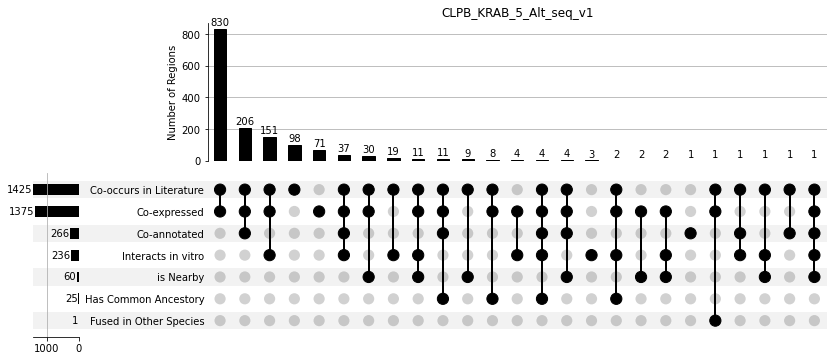

/tmp/ipykernel_188824/1337154778.py:105: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter.mean(axis=0)


inter-string shape (1508, 11)
DHS shape (100, 16)
TF shape (93, 282)


/tmp/ipykernel_188824/3629294891.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


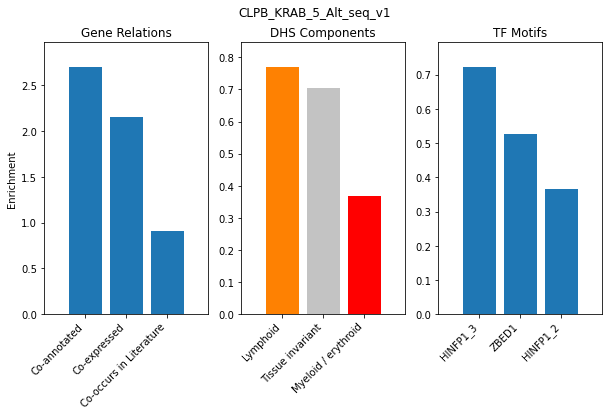

Significant_Gene_Sets_for_CLPB_KRAB_5_Alt_seq_v1


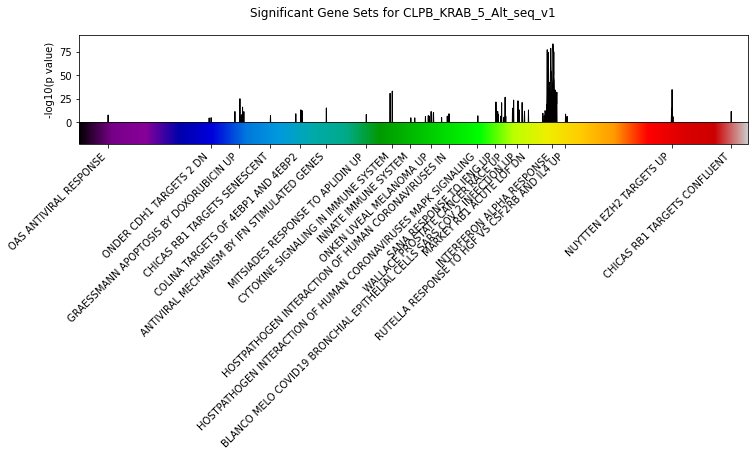

In [421]:
#normal enrichment analysis
significant_gene_sets, pvals, set_string_mean = set_of_genes_analysis(affected_genes, experiment, enrichments_dir, upset_dir, spectrum_dir, no_sig_gs=False)

In [428]:
#saving gene sets
f = open(sig_gene_sets_dir + 'significant_gene_sets.'+experiment+'_CT' + today.strftime("%Y%m%d") + '.txt', 'w')
for gene_set, pval in zip(significant_gene_sets, pvals):
    f.write(gene_set + '\t' + str(pval) + '\n')
f.close()

In [339]:
gene_list = affected_genes
title = 'CLPB_KRAB_5_Alt_seq_v1'

In [420]:
gene_list_filtered_STRING = gene_list[np.isin(gene_list, np.array(list(gene2id.keys())))]

ids_to_test = np.array([])
for gene in gene_list_filtered_STRING:
    ids_to_test = np.append(ids_to_test, gene2id[gene])

for i in range(len(ids_to_test)):
    ids_to_test[i] = ids_to_test[i].split('.')[0]

ids_to_test_set = set(ids_to_test)

#collecting all associations from genes of interest
string_scores_for_ids = []
filename = '/home/ctrader/region_similarity/data/9606.protein.links.full.v11.5.txt'
f = open(filename, 'r')
for line in f.readlines()[1:]:
    line = line.strip().split(' ')
    if line[0].split('.')[1] in ids_to_test_set:
        line[0] = line[0].split('.')[1]
        line[1] = line[1].split('.')[1]
        string_scores_for_ids.append(line)
string_scores_for_ids = np.array(string_scores_for_ids)
f.close()

#if ids have gene associations
scores_g = []
for row in string_scores_for_ids:
    new_row = []
    if row[0] in id2gene:
        new_row.append(id2gene[row[0]])
    else:
        new_row.append(row[0])

    if row[1] in id2gene:
        new_row.append(id2gene[row[1]])
    else:
        new_row.append(row[1])

    for i in range(2, len(row)):
        new_row.append(row[i])
    scores_g.append(new_row)
scores_g = np.array(scores_g)

if len(scores_g) > 0:
    #Dataframe
    set_df = pd.DataFrame(scores_g, columns = ['Gene1', 'Gene2', 'neighborhood', 'neighborhood_transferred',
                                               'fusion', 'cooccurence', 'homology', 'coexpression',
                                               'coexpression_transferred', 'experiments', 'experiments_transferred',
                                               'database', 'database_transferred', 'textmining', 'textmining_transferred',
                                               'combined_score'])

    set_df.loc[:, set_df.columns[2:]] = set_df[set_df.columns[2:]].astype(int)

    #combine human and transferred scores
    set_df['neighborhood'] = set_df[['neighborhood_transferred', 'neighborhood']].max(axis=1).astype(int)
    set_df['coexpression'] = set_df[['coexpression_transferred', 'coexpression']].max(axis=1).astype(int)
    set_df['experiments'] = set_df[['experiments_transferred', 'experiments']].max(axis=1).astype(int)
    set_df['database'] = set_df[['database_transferred', 'database']].max(axis=1).astype(int)
    set_df['textmining'] = set_df[['textmining_transferred', 'textmining']].max(axis=1).astype(int)
    set_df = set_df[['Gene1', 'Gene2', 'neighborhood', 'fusion', 'cooccurence', 'homology', 'coexpression', 
                     'experiments', 'database', 'textmining', 'combined_score']]
    
    #limiting set df
    genes12 = np.hstack((np.array(set_df['Gene1']).reshape(-1, 1), np.array(set_df['Gene2']).reshape(-1, 1)))
    genes12_sorted = np.sort(genes12, axis=1)
    genes12_sorted_joined = genes12_sorted[:, 0] + np.array(['_']*len(genes12_sorted)) + genes12_sorted[:, 1]
    genes12_unique, genes12_unique_inds = np.unique(genes12_sorted_joined, return_index=True)
    set_df = set_df.iloc[genes12_unique_inds]
    
    set_df_inter = set_df[set_df['Gene2'].isin(gene_list_filtered_STRING)]
    
#     if len(set_df_inter) > 0:
#         data_for_upset = set_df_inter.iloc[:, 2:-1].to_numpy()

#         labels_for_upset = ['is Nearby', 'Fused in Other Species', 'Co-evolved', 'Has Common Ancestory', 
#                             'Co-expressed', 'Interacts in vitro', 'Co-annotated', 'Co-occurs in Literature']
#         if np.count_nonzero(np.sum(data_for_upset, axis=0)) > 1:
#             make_upset(data_for_upset, labels_for_upset, title, upset_dir, no_save=True)

In [344]:
#limiting enrichment analysis to textmining genes
set_df_inter_limit = set_df_inter[set_df_inter['textmining']>0]
new_genes_list = np.unique(np.append(np.array(set_df_inter_limit['Gene1']), np.array(set_df_inter_limit['Gene2'])))
print(new_genes_list.shape)
print(gene_list.shape)
title = 'CLPB_KRAB_5_Alt_seq_v1_textmining_genes'

(89,)
(106,)


/tmp/ipykernel_188824/3830295859.py:2: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  set_df_inter_mean = set_df_inter_limit.mean(axis=0)


limited inter-string shape (1425, 11)
DHS shape (88, 16)
TF shape (85, 282)


/tmp/ipykernel_188824/3629294891.py:20: RuntimeWarning: divide by zero encountered in log2
  string_ooe_mean_log2 = np.log2(string_ooe_mean)[:-1] #don't care about overall score


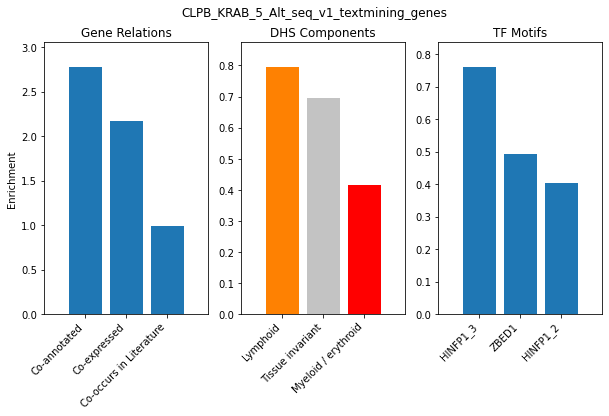

In [345]:
#limiting enrichment analysis to textmining genes
set_df_inter_mean = set_df_inter_limit.mean(axis=0)
print('limited inter-string shape', set_df_inter_limit.shape)

regions_set_TF = np.array([], dtype=int)
for gene in new_genes_list:
    if gene in gene2promoterregion:
        regions_set_TF = np.append(regions_set_TF, gene2promoterregion[gene])

#filter out genes not in gene dhs df
genes_to_test_DHS = new_genes_list[np.isin(new_genes_list, np.array(gene_dhs_df.index))]

#plotting - new format
set_string_mean = analyze_regions(regions_set_TF, all_df_mean, set_df_inter_mean, genes_to_test_DHS, title, enrichments_dir)
    

/tmp/ipykernel_188824/3444356208.py:7: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  average_strength = gene_df.mean(axis=0)['combined_score']


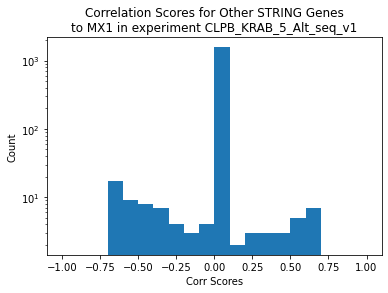

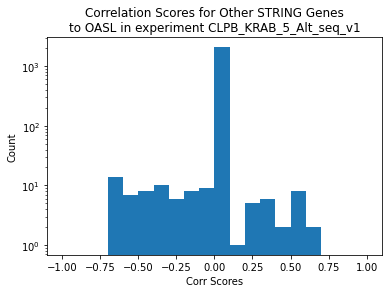

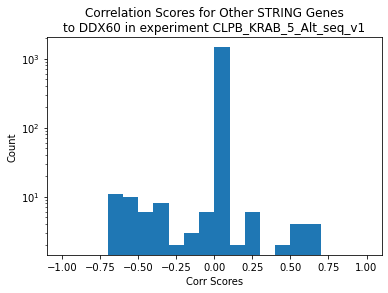

In [419]:
###checking for other string scores

#rank genes by association strength
gene_association_strength = np.array([])
for gene in gene_list:
    gene_df = set_df_inter[(set_df_inter['Gene1']==gene) | (set_df_inter['Gene2']==gene)]
    num_associations = len(gene_df)
    average_strength = gene_df.mean(axis=0)['combined_score']
    gene_association_strength = np.append(gene_association_strength, num_associations) #average_strength
#sorting by association
gene_list_sorted = gene_list[np.argsort(-gene_association_strength)]

#for top genes, what are other string relations and what are their correlations for the experiment?
for gene in gene_list_sorted[:3]:
    gene_full_df = set_df[(set_df['Gene1']==gene) | (set_df['Gene1']==gene)]
    string_genes = np.unique(np.append(np.array(gene_full_df['Gene1']), np.array(gene_full_df['Gene2'])))
    string_genes = string_genes[~np.isin(string_genes, gene_list)]
    megamap_scores = np.array(CLPB_KRAB_5_Alt_seq_v1_corrs[np.isin(megmap_genes, string_genes)], dtype=float)
    fig = plt.figure()

    plt.hist(megamap_scores, bins=np.arange(0, 2.1, 0.1)-1)
    
    plt.ylabel('Count')
    plt.xlabel('Corr Scores')
    plt.yscale('log')
    plt.title('Correlation Scores for Other STRING Genes\nto %s in experiment %s' %(gene, experiment))
    plt.show()

**Using CLT without cutoff to estimate p-value for all gene sets (for all experiments?)**

In [464]:
corrs = pd.read_feather('/net/seq/data2/projects/megamap/rnaseq_analysis_v4/metric_thresh_cossim/deseq_stat/effect_thresh_2.0/min_num_effect_3/corrs.feather')

In [468]:
megamap_genes = corrs.columns[4:]

In [579]:
num_gs = len(c1c2hallmarkgeneset2gene)

array(['HALLMARK_TNFA_SIGNALING_VIA_NFKB', 'HALLMARK_TGF_BETA_SIGNALING',
       'HALLMARK_REACTIVE_OXYGEN_SPECIES_PATHWAY', ...,
       'REACTOME_SPERM_MOTILITY_AND_TAXES',
       'REACTOME_MOLYBDENUM_COFACTOR_BIOSYNTHESIS',
       'REACTOME_ORGANIC_ANION_TRANSPORT'], dtype='<U141')

In [581]:
for i in range(len(corrs))[:1]:
    exper_corrs = corrs.loc[i][4:]
    exper_corrs_mean = np.mean(exper_corrs)
    print(exper_corrs_mean)
    print()
    for gs in np.array(list(c1c2hallmarkgeneset2gene.keys()))[50:60]:
        genes_in_gs = c1c2hallmarkgeneset2gene[gs]
        gs_genes_scores = np.array(exper_corrs[np.isin(megamap_genes, genes_in_gs)])
        print(np.mean(gs_genes_scores))
        gs_std = np.std(exper_corrs) / len(gs_genes_scores)
        gs_z = (np.mean(gs_genes_scores) - exper_corrs_mean) / gs_std
        gs_p = stats.norm.sf(np.abs(gs_z)) * num_gs #bonferroni correction
        gs_p = np.min([gs_p, 1])
        print(gs_std, gs_z, gs_p)
#         print(ttest_1samp(gs_genes_scores, exper_corrs_mean))
        print()

0.0017462453008331717

0.005333241489198472
0.010773277216333088 0.3329531131833448 1.0

0.04032278557618459
0.004039978956124908 9.548698321031234 4.4096071445113164e-18

0.0006682780172143663
0.0006925678210499842 -1.5564790203283299 1.0

0.011294162273406983
0.0017628999081272325 5.416028969402338 0.0002045967570868335

0.013888613535807682
0.0012430704480384332 9.768045129007117 5.184062314323764e-19

0.025490650991061785
0.0008735089634864666 27.182784244659317 3.484686445800155e-159

9.818341996934679e-05
0.0010773277216333088 -1.529768377597525 1.0

-0.0027553502183694104
0.0024861408960768663 -1.8106759461244157 1.0

0.003917925344790266
0.0005298333057212995 4.098798660836605 0.13943700813311688

0.01096857760263526
0.001053907553771715 8.750608408486386 7.12480081084791e-15



In [575]:
(np.mean(gs_genes_scores) - exper_corrs_mean) / gs_std

55.0912758546231

In [561]:
gs_genes_score.shape

(200,)

In [556]:
exper_corrs.shape

(36591,)

In [554]:
np.isin(megamap_genes, genes_in_gs).shape

(36591,)

In [493]:
exper_corrs_mean

0.017635270898507013

In [491]:
describe(exper_corrs)

DescribeResult(nobs=36591, minmax=(-0.9548597931861877, 0.9999999403953552), mean=0.0017462453008331717, variance=0.009401400592426105, skewness=0.5352687325110923, kurtosis=39.909671717203004)

In [513]:
s

0.0018186380506727685

In [514]:
sem(a)

0.01799999999999999

In [517]:
(np.mean(a) - exper_corrs_mean) / sem(a)

50.02026272786074

In [538]:
a = np.array([0.1, 0.3, 0.5])

In [541]:
exper_corrs_mean

0.017635270898507013

3.245738334872859e-19

In [537]:
z

19.450126530905145

Ttest_1sampResult(statistic=50.02026272786074, pvalue=9.558969620750213e-07)